# Final Project: Midterm Checkpoint
**Project:** How High Will Gas Prices Get Tomorrow? A GARCH-LSTM-t forecast scored against Kalshi AAA gas markets
**Team 5, AAI 6640:** Orville Rockwell Jr. (lead, Part 1 data and integration), Yi-Ting Lin (Part 3), Wenjun Chen (Part 2), Yixin Tian (Part 4)

This single notebook combines the team's four parts and runs top to bottom. Part 1 (data) is the `H.require_part1()` check in Section 3, Part 2 is Section 3, Part 3 is Section 4, and Part 4 is Sections 5 to 7. Section 1 and Section 2 are the progress overview and the team record.

| Section | Content |
|---|---|
| 1 | Progress overview |
| 2 | Team participation (Table 1 meeting record, Table 2 individual contributions) |
| 3 | Baseline implementation |
| 4 | Optimization experiments |
| 5 | Generalization and diagnostic analysis |
| 6 | Challenges and mitigation |
| 7 | Reflection and forward plan |

## 1. Progress overview

**What is done since the proposal.** The full pipeline runs end to end: data validation (Part 1), baselines and the GARCH-LSTM-t model (Part 2), controlled optimization experiments (Part 3), and diagnostics with a daily forecast service (Part 4), all in `gaslab/` and this notebook.

| Proposal item | Status | Evidence (test period) |
|---|---|---|
| Data pipeline: FRED/EIA weekly prices, daily wholesale and crude, AAA daily, Kalshi settlements | Done | 3,349 FRED rows to Nov 3 2026, 3,865 daily AAA values, 234 Kalshi daily events (Section 3) |
| Baselines: persistence, momentum, error-correction model, GARCH(1,1)-t, Gaussian LSTM | Done | Weekly test NLL 2.723 / – / 2.336 / 2.079 / 2.755 (Section 3) |
| GARCH-LSTM-t with Student-t head | Done | Weekly test NLL 2.032, daily test NLL -0.122 (Section 3) |
| At least two controlled optimization experiments | Done | Dropout, learning rate, plus L2 and revisions; tuned weekly test NLL 2.005 (Section 4) |
| Generalization and diagnostics | Done | PIT tests, market calibration, backtest, train/validation/test gaps, residuals (Section 5) |
| Kalshi benchmark | Done | Market better at the money (ATM accuracy 0.850 vs 0.802), not significantly better overall (Section 5) |
| Optional Transformer, neural SDE | Not started | Transformer is optional for Stage 3; neural SDE is out of scope |

**What changed from the proposal.**
* **Daily target.** Weekly EIA labels cannot define a daily move, so the daily model is trained on daily AAA values. Kalshi stores the AAA value each contract settled on, and Wayback Machine snapshots of gasprices.aaa.com extended the series from 367 to 3,865 days. Daily training windows grew from 83 to 3,181. The 10-year weekly model is kept and feeds the daily model.
* **Fresher inputs.** FRED wholesale and crude series were refreshed through Nov 3 2026 (previously Oct 14).
* **Extra baseline and tests.** Added an ECM-GARCH-t baseline, exact seed-mixture scoring and Diebold–Mariano tests. The tuned weekly setting (learning rate 3e-3, dropout 0.4) replaces the proposal's defaults.
* **Findings that reversed.** With the extended data the GARCH input no longer helps the daily model, and the market's lead over the model is significant only at the money.

**Where we stand.** The model forecasts the daily AAA move well relative to simple baselines (daily CRPS and Brier significantly better than persistence, momentum and GARCH alone) but does not match the Kalshi price. A separate smoke test on Nov 4–7 (4 days, 72 contracts; `tools/backtest_nov2026/RESULTS.md`) gave a mean error of 0.83 cents against 2.81 for "tomorrow equals today", with Brier 0.065 against 0.022 for the market. We claim no trading edge.

## 2. Team participation and coordination

**How the team coordinated.** Each member owned one part of the notebook (Table 2) and worked on a branch of the shared GitHub repository `aai6640-team5`, following `CONTRIBUTING.md`: pull first, work on a branch, open a pull request, a teammate reviews and merges, nothing is pushed straight to `main`. One person edits a given notebook at a time, announced in the group chat. All parts share the `gaslab/` package and save results to `results/` keyed by a data fingerprint, so a change in one part is picked up by the next. Orville integrated the parts and merged the pull requests.

**Table 1. Team meeting record**

| Meeting | Date and time | Format | Attendees | Topics and decisions | Action items |
|---|---|---|---|---|---|
| Kickoff | About Oct 20 (exact date TEAM TO CONFIRM) | Group chat (Discord) | Orville to Yi-Ting, Wenjun and Yixin | Orville posted the three-part split (Part 2 baselines, Part 3 optimization experiments, Part 4 diagnostics and reflection), kept Part 1 (data) and integration, and asked each member to pick a part, post five improvements marked "Revision" by Wednesday night, and keep a log of their work | Each member picks a part, writes five revisions, logs their work; review together on Friday |
| 1 | Sat Oct 24, 3:30 pm | Virtual | All four members | Split the work into four parts (data, baselines, optimization, diagnostics) and agree to reconvene on Friday | Each member starts their part |
| 2 | Friday review (date TEAM TO CONFIRM) | Virtual | All four members | Review progress of Parts 2–4 and each member's revisions | Each member finalizes their part and revision log |

*The team meets together virtually; attendance is recorded as all four members for each meeting. The date of the Friday review is not recorded in the repository and should be confirmed by the team.*

**Table 2. Individual contribution summary**

| Member | Role | Contributions | Evidence | Stage 3 responsibility (proposed) |
|---|---|---|---|---|
| Orville Rockwell Jr. | Team lead; Part 1 data; integration | Repository, README, requirements and contributing guide; data files and Part 1 validation; merged the four parts into one pipeline and notebook (pull request #3); with Claude Code assistance: refreshed FRED wholesale and crude data through Nov 3, retrained `model/`, ran the Nov 4–7 out-of-sample check (`tools/backtest_nov2026/`) | Commits Oct 28–29; pull requests #2 and #3; this notebook | lead; fresher daily wholesale and intraday AAA inputs (item 1); integration, reruns and PR review |
| Wenjun Chen | Part 2: baselines | Persistence, momentum, ECM, GARCH(1,1)-t, Gaussian LSTM, Student-t LSTM and GARCH-LSTM-t on weekly and daily data; daily raw-data plot; Revisions 1–5 (scale calibration, ECM-GARCH-t, exact mixture scoring, Diebold–Mariano tests, 5 seeds and regularization); extended the AAA daily series from Wayback snapshots (367 to 3,865 days) and fixed the daily test window | Commits Nov 4 and Nov 7; revision log in Section 3 | validation-fitted scale factor for daily intervals and at least five seeds (item 3); matched-time market comparison (item 4) |
| Yi-Ting (Jerry) Lin | Part 3: optimization experiments | Experiments 1 and 2 (dropout, learning rate) and the combined setting; Revisions 1–6 (5 seeds, wider grid, L2 experiment, lr × dropout grid, training/validation curves, learning-rate schedule) | Upload Nov 2; revision log in Section 4.2 | apply and test dropout 0.5 from Revision 6 (item 3); optional Transformer encoder on identical splits (item 5) |
| Yixin Tian | Part 4: diagnostics, challenges, reflection | PIT tests, market calibration by price bucket, model-versus-market blend, fee-aware backtest and bootstrap, weekly fallback, forecast and its scoring; Section 5.6 generalization and failure diagnostics; Sections 6–7 drafts | Upload Nov 7; pull request #2; revision log at the end of this notebook | rising/falling wholesale regime input and its diagnostics (item 2); rerun of Section 5 diagnostics and the forward track record |

*Table 2 follows the repository history and the revision logs. The Stage 3 column is a proposed split that follows each member's current part and the Section 7 plan; it is not yet confirmed by the team.*

## Setup (run this cell first, every time)
It installs any missing packages, then writes the project code (`gaslab/`) and the real data (`data/`) into this
notebook's folder **only if they are not there yet**. If you edit a file in `gaslab/` or drop newer CSVs in `data/`,
re-running this cell will not overwrite them. Data: EIA/FRED weekly retail and daily wholesale and crude prices
from Jan 2014 to Nov 3 2026, plus every settled Kalshi AAA gas contract (the daily AAA labels), and the AAA national daily average from
June 2015 to November 2026 recovered from Wayback Machine snapshots of gasprices.aaa.com (`manual_aaa.csv`).

#### ▶ What the next cell does: quick look at a FRED price series (exploratory, not used by the model)

Downloads the FRED series `DCOILWTICO` (daily WTI crude oil spot price) for Sep 1 2015 – Aug 31 2026 straight from the FRED website, renames the columns to `date` and `gas_price`, converts the dates, and prints the first rows and the table size. It then counts the calendar days between the two dates.

**Output:** the first five rows, the shape (2,870 trading days × 2 columns) and the number of calendar days (4,017). Missing values (`NaN`) are market holidays, such as Sep 7 2015 (Labor Day).

**Note:** `DCOILWTICO` is the **WTI crude oil price in dollars per barrel**, not a gasoline price, so the column name `gas_price` is misleading. This cell needs an internet connection, and nothing later in the notebook uses `df`: the model reads its data from `data/fred.csv`, written by the Setup cell. `df.tail()` in the middle of the cell shows nothing, because Jupyter only displays the last expression of a cell.

In [1]:
import pandas as pd

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILWTICO&cosd=2015-09-01&coed=2026-08-31"
df = pd.read_csv(url)
df.columns = ['date', 'gas_price']
df['date'] = pd.to_datetime(df['date'])

print(df.head())
print(df.shape)
df.tail()
from datetime import date
start = date(2015, 9, 1)
end = date(2026, 8, 31)
print((end - start).days)

        date  gas_price
0 2015-09-01      45.38
1 2015-09-02      46.30
2 2015-09-03      46.75
3 2015-09-04      46.02
4 2015-09-07        NaN
(2870, 2)
4017


#### ▶ What the next cell does: Setup: install packages, write the project code and the data

1. Checks whether `arch`, `statsmodels`, `scikit-learn`, `tensorflow`, `matplotlib` and `scipy` are installed and installs any that are missing.
2. `CODE` holds the source of every project module as text. The cell writes them to `gaslab/` (`data.py`, `models.py`, `evaluate.py`, `pipeline.py`, `experiments.py`, `handoff.py`, …). If `gaslab/` holds an older version of the code, it is first backed up to `gaslab_backup_<version>/` and then replaced.
3. `DATA` holds the five data files encoded as base64 text. They are decoded and written to `data/`: `fred.csv` (EIA/FRED retail, wholesale and crude prices), `kalshi_markets.csv` (every Kalshi AAA gas contract), `kalshi_open_book.csv` (bid/ask at the open), `manual_aaa.csv` (AAA national daily average, Jun 2015 – Nov 2026, from Wayback Machine snapshots of gasprices.aaa.com) and `manual_aaa_sources.csv` (where each AAA value came from: observed on the page, or read from its week-, month- or year-ago row).
4. Files that already exist are never overwritten, so your own edits and newer data are kept.

**Output:** the list of code files and the size of each data file. The cell is very long because the code and data are stored inside it, which is what lets the notebook run on its own.

In [2]:
import sys, os, base64, shutil, subprocess, importlib.util
need = [pkg for pkg, mod in [("arch", "arch"), ("statsmodels", "statsmodels"), ("scikit-learn", "sklearn"),
                             ("tensorflow", "tensorflow"), ("matplotlib", "matplotlib"), ("scipy", "scipy")]
        if importlib.util.find_spec(mod) is None]
if need:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *need]); print("installed:", need)
VERSION = '2026-11-08'
CODE = {'__init__.py': '', 'data.py': '"""Data layer: FRED wholesale/crude/retail + Kalshi AAA settlements -> leak-free feature tensors.\n\nTiming conventions (all decisions are made with information available at the bid time):\n  * Weekly model: origin = Monday t (EIA retail R_t surveyed 8 a.m. Monday). Target = log(R_{t+1}/R_t).\n    Wholesale/crude inputs use closes through the Friday before Monday t.\n  * Daily model: origin = 8:00 a.m. ET on day D-1, when Kalshi opens the contract settling on day D.\n    AAA\'s D-1 average is already posted (Kalshi centres the strike ladder on it). Wholesale/crude\n    inputs use closes through business day D-2. Target = log(A_D/A_{D-1}).\n"""\nfrom pathlib import Path\nimport numpy as np, pandas as pd\n\nDATA = Path(__file__).resolve().parent.parent / "data"\nGAL_PER_BBL = 42.0\n\n\ndef load_fred():\n    f = pd.read_csv(DATA / "fred.csv", parse_dates=["date"]).set_index("date").sort_index()\n    f["wti"] /= GAL_PER_BBL; f["brent"] /= GAL_PER_BBL            # $/bbl -> $/gal\n    f.loc[f["wti"] <= 0, "wti"] = np.nan                           # 2020-04-20 negative WTI print\n    return f\n\n\ndef load_aaa_daily():\n    """AAA national regular average by date, from Kalshi settlement values plus any manual rows."""\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series.isin(["KXAAAGASD", "KXAAAGASW", "KXAAAGASM"])].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["value"] = pd.to_numeric(k.value, errors="coerce")\n    s = k.dropna(subset=["value"]).groupby("date").value.first()\n    manual = DATA / "manual_aaa.csv"                               # optional: date,aaa\n    if manual.exists():\n        m = pd.read_csv(manual, parse_dates=["date"]).set_index("date")["aaa"]\n        s = pd.concat([s, m]).groupby(level=0).last()\n    return s.sort_index().rename("aaa")\n\n\ndef daily_contracts(series="KXAAAGASD"):\n    k = pd.read_csv(DATA / "kalshi_markets.csv")\n    k = k[k.series == series].copy()\n    k["date"] = pd.to_datetime(k.exp, utc=True).dt.tz_convert("America/New_York").dt.normalize().dt.tz_localize(None)\n    k["y"] = (k.result == "yes").astype(float).where(k.result.isin(["yes", "no"]))\n    book = DATA / "kalshi_open_book.csv"\n    if book.exists():\n        k = k.merge(pd.read_csv(book)[["ticker", "bid", "ask", "hours_after_open"]], on="ticker", how="left")\n    return k\n\n\n# ----------------------------------------------------------------------------------- weekly (10 years)\nWEEKLY_FEATS = ["d_retail", "d_gulf", "d_nyh", "d_brent", "up_gulf", "dn_gulf", "ect", "garch_sd"]\n\n\ndef weekly_frame(f=None):\n    """One row per EIA Monday t with features known at t and target y = log(R_{t+1}/R_t)."""\n    f = load_fred() if f is None else f\n    r = f["retail_eia_weekly"].dropna()\n    bd = f[["whsl_gulf", "whsl_nyh", "brent"]].ffill()\n    rows = []\n    for t in r.index:\n        fri = bd.loc[: t - pd.Timedelta(days=3)].tail(5)            # Mon-Fri week ending the Friday before t\n        if len(fri) < 5: continue\n        rows.append(dict(date=t, retail=r.loc[t], gulf=fri.whsl_gulf.mean(), nyh=fri.whsl_nyh.mean(), brent=fri.brent.mean()))\n    w = pd.DataFrame(rows).set_index("date")\n    lw = np.log(w)\n    w["d_retail"] = lw.retail.diff(); w["d_gulf"] = lw.gulf.diff(); w["d_nyh"] = lw.nyh.diff(); w["d_brent"] = lw.brent.diff()\n    w["up_gulf"] = w.d_gulf.clip(lower=0); w["dn_gulf"] = w.d_gulf.clip(upper=0)         # rockets & feathers\n    spread = lw.retail - lw.gulf                                                          # retail margin (log)\n    w["ect"] = spread - spread.rolling(52, min_periods=26).mean()                        # error-correction term\n    w["y"] = w.d_retail.shift(-1)\n    return w\n\n\n# ----------------------------------------------------------------------------------- daily (Kalshi)\nDAILY_FEATS = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift", "garch_sd"]\n\n\ndef daily_frame(f=None, aaa=None, weekly_drift=None, extend_to=None):\n    """One row per settlement day D with features known at 8 a.m. ET on D-1.\n    extend_to adds future settlement dates (no target yet) so live contracts can be priced."""\n    f = load_fred() if f is None else f\n    aaa = load_aaa_daily() if aaa is None else aaa\n    a = aaa.asfreq("D")\n    if extend_to is not None and pd.Timestamp(extend_to) > a.index[-1]:\n        a = a.reindex(pd.date_range(a.index[0], extend_to, freq="D"))\n    bd = f[["whsl_gulf", "brent"]].ffill().asfreq("D").reindex(a.index.union(f.index)).ffill().reindex(a.index)\n    df = pd.DataFrame(index=a.index)\n    df["aaa_prev"] = a.shift(1)                                          # A_{D-1}\n    df["d_aaa"] = np.log(a).diff().shift(1)                              # change into D-1\n    df["d_aaa_l2"] = df["d_aaa"].shift(1)                                # change into D-2\n    g2 = np.log(bd.whsl_gulf).shift(2); b2 = np.log(bd.brent).shift(2)   # closes through D-2\n    df["d_gulf"] = g2.diff(); df["d_brent"] = b2.diff()\n    spread = np.log(df.aaa_prev) - g2.rolling(5).mean()\n    df["ect"] = spread - spread.rolling(28, min_periods=10).mean()\n    df["w_drift"] = 0.0 if weekly_drift is None else weekly_drift.reindex(df.index, method="ffill").fillna(0) / 7.0\n    df["y"] = np.log(a).diff()\n    return df\n\n\ndef sequences(df, feats, lookback, rows=None, allow_missing_y=()):\n    """Stack rolling windows of features ending at each row. Returns X, y, index.\n    Rows listed in allow_missing_y are kept even without a target (used for live forecasts)."""\n    vals = df[feats].values.astype("float32"); ys = df["y"].values.astype("float32")\n    idx = []; X = []; Y = []\n    want = set(df.index if rows is None else rows)\n    for i in range(lookback - 1, len(df)):\n        if df.index[i] not in want: continue\n        win = vals[i - lookback + 1: i + 1]\n        if np.isnan(win).any() or (np.isnan(ys[i]) and df.index[i] not in allow_missing_y): continue\n        X.append(win); Y.append(ys[i]); idx.append(df.index[i])\n    return np.array(X), np.array(Y), pd.DatetimeIndex(idx)\n', 'evaluate.py': '"""Scoring: distribution metrics, Kalshi strike-ladder pricing, accuracy variants, and a fee-aware backtest."""\nimport numpy as np, pandas as pd\nfrom scipy import stats\n\n\ndef cdf(x, mu, scale, df):\n    z = (x - mu) / scale\n    return np.where(np.isinf(df), stats.norm.cdf(z), stats.t.cdf(z, np.where(np.isinf(df), 30, df)))\n\n\ndef logpdf(y, mu, scale, df):\n    z = (y - mu) / scale\n    return np.where(np.isinf(df), stats.norm.logpdf(z), stats.t.logpdf(z, np.where(np.isinf(df), 30, df))) - np.log(scale)\n\n\ndef crps_mc(y, mu, scale, df, n=2000, seed=0):\n    rng = np.random.default_rng(seed); z = rng.standard_normal((n, len(y)))\n    t = np.where(np.isinf(df), z, rng.standard_t(np.where(np.isinf(df), 30, df), size=(n, len(y))))\n    s = mu + scale * t; s2 = mu + scale * np.roll(t, 1, axis=0)\n    return np.mean(np.abs(s - y), 0) - 0.5 * np.mean(np.abs(s - s2), 0)\n\n\ndef dist_metrics(y_pct, d):\n    mu, sc, nu = d.mu.values, d.scale.values, d.df.values\n    nz = y_pct != 0\n    return {"NLL": float(-logpdf(y_pct, mu, sc, nu).mean()),\n            "CRPS": float(crps_mc(y_pct, mu, sc, nu).mean()),\n            "MAE": float(np.abs(y_pct - mu).mean()),\n            "dir_acc": float((np.sign(mu[nz]) == np.sign(y_pct[nz])).mean()) if np.any(mu != 0) else np.nan,\n            "cov80": float(np.mean(np.abs(cdf(y_pct, mu, sc, nu) - 0.5) <= 0.4)),\n            "n": int(len(y_pct))}\n\n\ndef price_ladder(contracts, dist, prev_col="prev", extra_sd_pct=None):\n    """P(YES) = P(level_D > k) = 1 - F(100*ln(k/prev)). extra_sd_pct widens the scale (e.g. basis noise)."""\n    c = contracts.join(dist, on="date", how="inner")\n    sc = c.scale if extra_sd_pct is None else np.sqrt(c.scale ** 2 + extra_sd_pct ** 2)\n    x = 100 * np.log(c.strike / c[prev_col])\n    c["p"] = np.clip(1 - cdf(x, c.mu, sc, c.df), 1e-4, 1 - 1e-4)\n    return c\n\n\ndef contract_metrics(c, atm_cents=1.0):\n    y, p = c.y.values, c.p.values\n    atm = (np.abs(c.strike - c.prev) * 100 <= atm_cents).values\n    out = {"contracts": int(len(c)), "events": int(c.date.nunique()),\n           "accuracy": float(((p > 0.5) == (y == 1)).mean()),\n           "atm_accuracy": float(((p[atm] > 0.5) == (y[atm] == 1)).mean()) if atm.any() else np.nan,\n           "atm_n": int(atm.sum()),\n           "brier": float(np.mean((p - y) ** 2)),\n           "logloss": float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))}\n    return out\n\n\ndef kalshi_fee(price, rate=0.07):\n    """Kalshi taker fee per contract: rate * P * (1-P), rounded up to the centicent ($0.0001), per the Kalshi fee\n    schedule effective July 7, 2026. Resting (maker) orders on KXAAAGASD are not in the non-standard fee table,\n    so their maker multiplier defaults to 0 (no maker fee); this backtest conservatively assumes taker orders."""\n    return np.ceil(rate * price * (1 - price) * 10000 - 1e-9) / 10000\n\n\ndef backtest(c, edge=0.03):\n    """Take one contract per signal at the first-hour book after open. YES at ask, NO at (1-bid)."""\n    c = c.dropna(subset=["bid", "ask", "y"]).copy()\n    c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]\n    buy_yes = c.p - c.ask - kalshi_fee(c.ask) > edge\n    no_px = 1 - c.bid\n    buy_no = (1 - c.p) - no_px - kalshi_fee(no_px) > edge\n    pnl = np.where(buy_yes, c.y - c.ask - kalshi_fee(c.ask), 0.0) + np.where(buy_no, (1 - c.y) - no_px - kalshi_fee(no_px), 0.0)\n    trades = buy_yes | buy_no\n    c["pnl"] = pnl; c["trade"] = trades\n    cost = np.where(buy_yes, c.ask, 0) + np.where(buy_no, no_px, 0)\n    return {"trades": int(trades.sum()), "hit_rate": float((pnl[trades] > 0).mean()) if trades.any() else np.nan,\n            "pnl_per_contract": float(pnl[trades].mean()) if trades.any() else np.nan,\n            "total_pnl_$": float(pnl.sum()), "capital_$": float(cost.sum()),\n            "roi": float(pnl.sum() / cost.sum()) if cost.sum() else np.nan}, c\n\n\ndef market_metrics(c):\n    m = c.dropna(subset=["bid", "ask", "y"]).copy()\n    m["p"] = ((m.bid + m.ask) / 2).clip(0.005, 0.995)\n    return contract_metrics(m), m\n\n\ndef event_bootstrap(a, b, n=2000, seed=0):\n    """95% CIs that respect the small number of events: resample whole settlement days (all strikes of a day\n    move together), then recompute accuracy and Brier for signal a, signal b and the difference a - b.\n    a, b: priced contract tables (ticker, date, p, y) on the same contracts."""\n    m = a[["ticker", "date", "p", "y", "strike", "prev"]].merge(b[["ticker", "p"]], on="ticker", suffixes=("_a", "_b"))\n    m["acc_a"] = ((m.p_a > .5) == (m.y == 1)).astype(float); m["acc_b"] = ((m.p_b > .5) == (m.y == 1)).astype(float)\n    m["br_a"] = (m.p_a - m.y) ** 2; m["br_b"] = (m.p_b - m.y) ** 2\n    m["atm"] = (np.abs(m.strike - m.prev) * 100 <= 1.0)\n    g = m.groupby("date"); days = list(g.groups); rng = np.random.default_rng(seed)\n    sums = g[["acc_a", "acc_b", "br_a", "br_b"]].sum(); cnt = g.size()\n    atm = m[m.atm].groupby("date")[["acc_a", "acc_b"]].sum().reindex(days).fillna(0); atm_n = m[m.atm].groupby("date").size().reindex(days).fillna(0)\n    stats = []\n    for _ in range(n):\n        idx = rng.integers(0, len(days), len(days)); S = sums.iloc[idx].sum(); N = cnt.iloc[idx].sum()\n        A = atm.iloc[idx].sum(); An = atm_n.iloc[idx].sum()\n        stats.append([S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n                      A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An])\n    stats = np.array(stats); S = sums.sum(); N = cnt.sum(); A = atm.sum(); An = atm_n.sum()\n    point = [S.acc_a / N, S.acc_b / N, (S.acc_a - S.acc_b) / N, S.br_a / N, S.br_b / N, (S.br_a - S.br_b) / N,\n             A.acc_a / An, A.acc_b / An, (A.acc_a - A.acc_b) / An]\n    names = ["accuracy A", "accuracy B", "accuracy A-B", "Brier A", "Brier B", "Brier A-B", "ATM accuracy A", "ATM accuracy B", "ATM accuracy A-B"]\n    lo, hi = np.percentile(stats, 2.5, axis=0), np.percentile(stats, 97.5, axis=0)\n    return pd.DataFrame({"metric": names, "estimate": point, "ci95_low": lo, "ci95_high": hi}), dict(contracts=int(N), events=len(days), atm_contracts=int(An))\n', 'experiments.py': '"""Reproducible experiment suite used by the midterm notebook. Each function returns tables/figures."""\nimport os, warnings, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3"); warnings.filterwarnings("ignore")\nimport numpy as np, pandas as pd, matplotlib\nimport matplotlib.pyplot as plt\nfrom scipy import stats\nfrom . import data as D, models as M, evaluate as E, pipeline as P\n\nSEEDS = range(3)\nVA = ("2026-07-01", "2026-08-19"); TE = ("2026-08-20", "2026-10-19")   # fixed end: last settled Kalshi contract, so new AAA days do not change the test set\nWVA = ("2023-01-01", "2024-12-31"); WTE = ("2025-01-01", "2027-12-31")\n\n\ndef _rows(res, df_y, rngs, contracts=None):\n    out = []\n    for name, d in res.items():\n        for lab, (a, b) in rngs.items():\n            dd = d.loc[a:b].dropna(); y = df_y.loc[dd.index].values * 100\n            row = {"model": name, "split": lab, **E.dist_metrics(y, dd)}\n            if contracts is not None:\n                row.update(E.contract_metrics(E.price_ladder(contracts[contracts.date.isin(dd.index)], dd)))\n            out.append(row)\n    return pd.DataFrame(out)\n\n\n# --------------------------------------------------------------------------------------- Stage 1: weekly\ndef weekly_stage1():\n    w, gpar = P.weekly_dataset()\n    base, beta = P.weekly_baselines(w)\n    runs_g = [P.run_weekly(w, head="gauss", seed=s) for s in SEEDS]\n    runs_n = [P.run_weekly(w, head="t_nog", seed=s) for s in SEEDS]      # ablation: Student-t, no GARCH input\n    runs_t = [P.run_weekly(w, head="t", seed=s) for s in SEEDS]\n    nu = float(gpar["nu"]); ok = w.dropna(subset=["y", "garch_sd"]).index      # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": w.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    res = {**base, "Gaussian LSTM (x3)": P.ensemble(runs_g), "Student-t LSTM, no GARCH (x3)": P.ensemble(runs_n),\n           "GARCH-LSTM-t (x3)": P.ensemble(runs_t)}\n    tab = _rows(res, w["y"], {"val": WVA, "test": WTE})\n    return dict(w=w, garch=gpar, ecm_beta=beta, runs_g=runs_g, runs_n=runs_n, runs_t=runs_t, res=res, table=tab)\n\n\n# --------------------------------------------------------------------------------------- Stage 2: controlled\ndef stage2_experiments(w):\n    """One factor at a time on the weekly GARCH-LSTM-t; everything else fixed at the baseline config\n    (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, early stop on val NLL)."""\n    grid = {"E1 dropout": ("dropout", [0.0, 0.2, 0.4]),\n            "E2 learning rate": ("lr", [3e-4, 1e-3, 3e-3])}\n    rows, curves = [], {}\n    for exp, (k, vals) in grid.items():\n        for v in vals:\n            nll, ep = [], []\n            for s in SEEDS:\n                r = P.run_weekly(w, head="t", seed=s, **{k: v})\n                tr, va, te = r["masks"]\n                nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"]); ep.append(len(r["hist"]["loss"]))\n                if s == 0: curves[(exp, v)] = r["hist"]\n            rows.append({"experiment": exp, "setting": v, "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),\n                         "epochs_mean": np.mean(ep)})\n    return pd.DataFrame(rows), curves\n\n\ndef weekly_tuned(w, s2):\n    """Use the Stage 2 findings: combine the best single-factor settings step by step and keep a change only if\n    mean validation NLL improves. Returns the chosen config, the comparison table and the ensemble forecast."""\n    best = {e: s2[s2.experiment == e].sort_values("val_NLL_mean").iloc[0].setting for e in s2.experiment.unique()}\n    steps = [("baseline (lb 8, lr 1e-3, dropout 0.2)", {}),\n             ("+ lr %g" % best["E2 learning rate"], {"lr": float(best["E2 learning rate"])}),\n             ("+ dropout %g" % best["E1 dropout"], {"dropout": float(best["E1 dropout"])})]\n    cfg, rows, keep_runs, best_nll = {}, [], None, np.inf\n    for name, add in steps:\n        trial = {**cfg, **add}\n        runs = [P.run_weekly(w, head="t", seed=s, **trial) for s in SEEDS]\n        va = runs[0]["masks"][1]\n        nll = [E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"] for r in runs]\n        kept = np.mean(nll) < best_nll\n        rows.append({"step": name, "config": dict(trial), "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll), "kept": kept})\n        if kept: cfg, best_nll, keep_runs = trial, np.mean(nll), runs\n    return cfg, pd.DataFrame(rows), keep_runs\n\n\n# --------------------------------------------------------------------------------------- daily Kalshi model\ndef daily_stage(weekly_mu, lookbacks=(7, 14), heads=("gauss", "t")):\n    df, gpar = P.daily_dataset(weekly_mu_pct=weekly_mu)\n    c = P.daily_contracts_with_prev(); c = c[c.y.notna()]\n    base, beta = P.daily_baselines(df)\n    nu = float(gpar["nu"]); ok = df.dropna(subset=["y", "garch_sd"]).index    # GARCH(1,1)-t on its own, zero mean\n    base["GARCH(1,1)-t alone"] = pd.DataFrame({"mu": 0.0, "scale": df.loc[ok, "garch_sd"] * np.sqrt((nu - 2) / nu), "df": nu}, index=ok)\n    runs = {lb: {h: [P.run_daily(df, head=h, seed=s, lookback=lb) for s in SEEDS] for h in heads} for lb in lookbacks}\n    res = {**base}\n    for lb in runs:\n        if "gauss" in runs[lb]: res[f"Gaussian LSTM lb{lb} (x3)"] = P.ensemble(runs[lb]["gauss"])\n        if "t_nog" in runs[lb]: res[f"Student-t LSTM, no GARCH lb{lb} (x3)"] = P.ensemble(runs[lb]["t_nog"])\n        if "t" in runs[lb]: res[f"GARCH-LSTM-t lb{lb} (x3)"] = P.ensemble(runs[lb]["t"])\n    tab = _rows(res, df["y"], {"val": VA, "test": TE}, c)\n    mk = [{"model": "Kalshi market (9 a.m., 1 h after open)", "split": lab, **E.market_metrics(c[c.date.isin(df.loc[a:b].index)])[0]}\n          for lab, (a, b) in {"val": VA, "test": TE}.items()]\n    tab = pd.concat([tab, pd.DataFrame(mk)], ignore_index=True)\n    return dict(df=df, garch=gpar, ecm_beta=beta, contracts=c, runs=runs, res=res, table=tab)\n\n\ndef final_daily(ds, name="GARCH-LSTM-t lb7 (x3)"):\n    """Final signal = model, plus a market-blended version. The blend is fitted on a calibration window\n    (Aug 20 - Sep 19) and scored only on the later, untouched window (Sep 20 - Oct 19)."""\n    df, c, d = ds["df"], ds["contracts"], ds["res"][name]\n    ct = E.price_ladder(c[c.date.isin(df.loc[TE[0]:TE[1]].index)], d.loc[TE[0]:TE[1]])\n    # stack weights fitted on the first half of the test window, scored on the second half (time-ordered, no overlap)\n    cut = "2026-09-19"; cfit, ct = ct[ct.date <= cut], ct[ct.date > cut]\n    st, coef = P.stack_with_market(cfit, ct)\n    bt_model, tr_model = E.backtest(ct); bt_stack, tr_stack = E.backtest(st)\n    _, mkt = E.market_metrics(ct)\n    return dict(model_test=ct, stacked_test=st, market_test=mkt, stack_coef=coef,\n                backtest=pd.DataFrame([{"signal": "model", **bt_model}, {"signal": "model+market stack", **bt_stack}]),\n                trades_model=tr_model, trades_stack=tr_stack,\n                metrics=pd.DataFrame([{"signal": "model", **E.contract_metrics(ct)},\n                                      {"signal": "model+market stack", **E.contract_metrics(st)},\n                                      {"signal": "market mid", **E.contract_metrics(mkt)}]))\n\n\ndef weekly_on_kalshi(w, d_weekly, start="2025-01-01"):\n    """Score the 10-year weekly model on real Kalshi weekly AAA contracts using the EIA->AAA basis.\n    Out of sample: only contracts whose forecast origin is in the weekly TEST period (from `start`), and the\n    basis is estimated only on Mondays before `start`."""\n    aaa = D.load_aaa_daily(); r = w["retail"]\n    both = pd.concat([aaa, r], axis=1, join="inner").dropna(); both = both[both.index < start]\n    basis = both["aaa"] - both["retail"]\n    k = D.daily_contracts("KXAAAGASW"); k = k[k.y.notna()].copy()\n    k["origin"] = k.date - pd.Timedelta(days=7)\n    k = k[k.origin.isin(d_weekly.index) & k.date.isin(r.index) & (k.origin >= start)].copy()\n    k["prev"] = r.reindex(k.origin).values + basis.mean()\n    dd = d_weekly.reindex(k.origin.unique()); dd.index.name = "date"\n    kk = k.rename(columns={"date": "settle"}).rename(columns={"origin": "date"})\n    dd = dd.dropna()\n    priced = E.price_ladder(kk, dd, extra_sd_pct=100 * basis.std() / r.mean()).dropna(subset=["p", "y"])\n    return dict(basis_mean=float(basis.mean()), basis_sd=float(basis.std()), basis_n=int(len(basis)),\n                metrics=E.contract_metrics(priced), priced=priced)\n\n\n# --------------------------------------------------------------------------------------- diagnostics\ndef convergence_table(named_runs):\n    """Per run: epochs, best epoch (1-based), train/val loss at the best epoch and at the end."""\n    rows = []\n    for name, runs in named_runs.items():\n        for sd, r in enumerate(runs):\n            h = r["hist"]; b = int(np.argmin(h["val_loss"]))\n            rows.append(dict(model=name, seed=sd, epochs_run=len(h["loss"]), best_epoch=b + 1, train_loss_at_best=h["loss"][b],\n                             val_loss_at_best=h["val_loss"][b], final_train_loss=h["loss"][-1], final_val_loss=h["val_loss"][-1],\n                             train_windows=int(r["masks"][0].sum())))\n    t = pd.DataFrame(rows); t["val_minus_train_at_best"] = t.val_loss_at_best - t.train_loss_at_best\n    return t\n\n\ndef plot_learning_curves(runs_g, runs_t, title="Weekly model learning curves (seed 0)", names=("Gaussian LSTM", "GARCH-LSTM-t")):\n    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))\n    for a, r, nm in [(ax[0], runs_g[0], names[0]), (ax[1], runs_t[0], names[1])]:\n        ep = np.arange(1, len(r["hist"]["loss"]) + 1)\n        a.plot(ep, r["hist"]["loss"], label="train NLL"); a.plot(ep, r["hist"]["val_loss"], label="validation NLL")\n        best = int(np.argmin(r["hist"]["val_loss"])) + 1; a.axvline(best, ls="--", c="gray", lw=1, label=f"best epoch {best}")\n        a.set_title(nm); a.set_xlabel("epoch (1-based)"); a.set_ylabel("NLL (percent units)"); a.legend(fontsize=8)\n    fig.suptitle(title); fig.tight_layout(); return fig\n\n\ndef plot_stage2(curves):\n    exps = sorted({e for e, _ in curves})\n    fig, ax = plt.subplots(1, len(exps), figsize=(5 * len(exps), 3.4))\n    for a, e in zip(ax, exps):\n        for (ee, v), h in curves.items():\n            if ee == e: a.plot(h["val_loss"], label=f"{v}")\n        a.set_title(e); a.set_xlabel("epoch (1-based)"); a.set_ylabel("validation NLL"); a.legend(fontsize=8)\n    fig.tight_layout(); return fig\n\n\ndef plot_reliability(fin, bins=10):\n    fig, ax = plt.subplots(figsize=(5, 4.5)); edges = np.linspace(0, 1, bins + 1)\n    for nm, c in [("model", fin["model_test"]), ("model+market stack", fin["stacked_test"]), ("market mid", fin["market_test"])]:\n        b = np.clip(np.digitize(c.p, edges) - 1, 0, bins - 1)\n        g = pd.DataFrame({"b": b, "p": c.p, "y": c.y}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))\n        ax.plot(g.p, g.y, "o-", label=nm)\n    ax.plot([0, 1], [0, 1], "k--", lw=1); ax.set_xlabel("predicted P(YES)"); ax.set_ylabel("observed YES frequency")\n    ax.set_title("Reliability, daily Kalshi test contracts"); ax.legend(fontsize=8); fig.tight_layout(); return fig\n\n\ndef plot_pit(w, d, rng=WTE, title="PIT histogram, weekly test (GARCH-LSTM-t)"):\n    dd = d.loc[rng[0]:rng[1]].dropna(); y = w.loc[dd.index, "y"].values * 100\n    u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)\n    fig, ax = plt.subplots(figsize=(5, 3.4)); ax.hist(u, bins=10, range=(0, 1), edgecolor="k")\n    ax.axhline(len(u) / 10, c="r", ls="--", lw=1); ax.set_xlabel("PIT value"); ax.set_ylabel("count"); ax.set_title(title)\n    fig.tight_layout(); return fig, stats.kstest(u, "uniform")\n\n\ndef accuracy_by_distance(c):\n    dist = (np.abs(c.strike - c.prev) * 100).round(1)\n    b = pd.cut(dist, [-0.01, 0.5, 1, 2, 3, 10], labels=["<=0.5c", "0.5-1c", "1-2c", "2-3c", ">3c"])\n    return c.assign(bucket=b, correct=((c.p > 0.5) == (c.y == 1))).groupby("bucket", observed=True).agg(\n        contracts=("y", "size"), accuracy=("correct", "mean"), brier=("p", lambda p: np.mean((p - c.loc[p.index, "y"]) ** 2)))\n\n\ndef error_by_regime(w, d, rng=WTE):\n    dd = d.loc[rng[0]:rng[1]].dropna(); x = w.loc[dd.index]\n    reg = np.where(x.d_gulf > 0, "wholesale rising", "wholesale falling")\n    y = x.y.values * 100\n    return pd.DataFrame({"regime": reg, "abs_err": np.abs(y - dd.mu.values),\n                         "dir_ok": np.sign(dd.mu.values) == np.sign(y)}).groupby("regime").agg(\n        weeks=("abs_err", "size"), MAE=("abs_err", "mean"), dir_acc=("dir_ok", "mean"))\n', 'handoff.py': '"""Connects the four notebook parts into one pipeline.\n\nPart 1 checks and fingerprints the data in data/ and saves results/part1.pkl.\nParts 2, 3 and 4 call part1() first, so they always run on the data Part 1 validated. Each part saves what the next\none needs (results/part2.pkl, part3.pkl). A saved file is used only if it was built from the same data; if you add\nor change data in data/, everything downstream is rebuilt automatically. Missing files are rebuilt too, so every part\nalso works on its own."""\nimport hashlib, json, pickle\nfrom pathlib import Path\nimport pandas as pd\nfrom . import data as D, pipeline as P, experiments as X\n\nR = Path("results")\nDATA_FILES = ["fred.csv", "kalshi_markets.csv", "kalshi_open_book.csv", "manual_aaa.csv", "manual_wholesale.csv"]\nDEFAULT_WEEKLY_CFG = {"lr": 0.003, "dropout": 0.4}   # selected by the Part 3 experiments\n\n\ndef fingerprint():\n    h = hashlib.md5()\n    for f in DATA_FILES:\n        p = D.DATA / f\n        if p.exists(): h.update(f.encode()); h.update(p.read_bytes())\n    return h.hexdigest()[:12]\n\n\ndef save(name, obj):\n    R.mkdir(exist_ok=True); pickle.dump({"fp": fingerprint(), "obj": obj}, open(R / f"{name}.pkl", "wb"))\n    print(f"saved results/{name}.pkl for the next part (data fingerprint {fingerprint()})")\n\n\ndef _load(name):\n    f = R / f"{name}.pkl"\n    if not f.exists(): return None\n    d = pickle.load(open(f, "rb"))\n    if d["fp"] != fingerprint():\n        print(f"results/{name}.pkl was built from different data: rebuilding"); return None\n    print(f"loaded results/{name}.pkl (from the previous part, same data)"); return d["obj"]\n\n\ndef _merge_manual_wholesale():\n    m = D.DATA / "manual_wholesale.csv"\n    if not m.exists(): return 0\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"]).set_index("date")\n    add = pd.read_csv(m, parse_dates=["date"]).set_index("date")\n    f = f.combine_first(add); f.update(add); f.sort_index().to_csv(D.DATA / "fred.csv")\n    m.rename(D.DATA / "manual_wholesale.merged.csv"); return len(add)     # so rows are merged once\n\n\ndef part1(verbose=True):\n    """Validate data/, merge any manual rows, print a data report and save results/part1.pkl."""\n    n = _merge_manual_wholesale()\n    if n and verbose: print(f"merged {n} manual wholesale rows into data/fred.csv")\n    f = pd.read_csv(D.DATA / "fred.csv", parse_dates=["date"])\n    need = ["date", "retail_eia_weekly", "whsl_nyh", "whsl_gulf", "wti", "brent"]\n    assert list(f.columns[:6]) == need, f"data/fred.csv columns must be {need}, found {list(f.columns)}"\n    assert f.date.is_monotonic_increasing and not f.date.duplicated().any(), "data/fred.csv dates must be sorted and unique"\n    aaa = D.load_aaa_daily(); k = pd.read_csv(D.DATA / "kalshi_markets.csv")\n    rep = dict(fred_rows=len(f), fred_first=str(f.date.min().date()), fred_last=str(f.date.max().date()),\n               weekly_retail=int(f.retail_eia_weekly.notna().sum()), aaa_dates=len(aaa), aaa_last=str(aaa.index[-1].date()),\n               kalshi_daily_events=int(k[k.series == "KXAAAGASD"].event.nunique()), fingerprint=fingerprint())\n    if verbose:\n        print("DATA REPORT (this is what Parts 2, 3 and 4 will use)")\n        for a, b in rep.items(): print(f"  {a:20s} {b}")\n    save("part1", rep); return rep\n\n\ndef require_part1():\n    """First cell of Parts 2-4: make sure the data was validated, and say so."""\n    rep = _load("part1")\n    if rep is None: print("running the Part 1 data check first"); rep = part1(verbose=False)\n    print(f"data: EIA/FRED {rep[\'fred_first\']} to {rep[\'fred_last\']}, {rep[\'aaa_dates\']} dated AAA values, last AAA {rep[\'aaa_last\']}")\n    return rep\n\n\ndef part2():\n    """Weekly frame + Stage 1 forecasts (needed by Parts 3 and 4)."""\n    require_part1()\n    o = _load("part2")\n    if o is None:\n        print("rebuilding Part 2 results from data/ (about 2 minutes)")\n        s1 = X.weekly_stage1(); o = {"w": s1["w"], "res": s1["res"]}; save("part2", o)\n    return o\n\n\ndef part3(s1):\n    """Tuned weekly GARCH-LSTM-t forecast (needed by Part 4)."""\n    o = _load("part3")\n    if o is None:\n        f = R / "weekly_cfg.json"\n        wcfg = json.load(open(f)) if f.exists() else DEFAULT_WEEKLY_CFG\n        print(f"retraining the tuned weekly model with {wcfg} (about 1 minute)")\n        runs = [P.run_weekly(s1["w"], head="t", seed=s, **wcfg) for s in X.SEEDS]\n        o = {"tuned": P.ensemble(runs), "wcfg": wcfg}; save("part3", o)\n    return o\n', 'models.py': '"""Forecasters. Every model returns a predictive distribution (mu, scale, df) for the next log change,\nin percent units (y*100). df=inf means Gaussian.\n\n  Persistence     : random walk, mu=0, scale = rolling sd                      (naive baseline)\n  ECM             : asymmetric error-correction OLS (Borenstein et al., 1997) (statistical baseline)\n  Gaussian LSTM   : 2x LSTM + Gaussian NLL                                     (Stage 1 deep baseline)\n  GARCH-LSTM-t    : LSTM fed GARCH(1,1) volatility, Student-t head scaled by GARCH sd (Stage 3 extension;\n                    successor of the proposal\'s VAD-LSTM recursion, now a trainable hybrid in the\n                    style of Kim & Won, 2018)\n"""\nimport numpy as np, pandas as pd\nfrom arch import arch_model\n\n# ----------------------------------------------------------------------------- GARCH feature (no look-ahead)\ndef garch_feature(returns, train_end):\n    """Fit GARCH(1,1)-t on returns up to train_end only, then run the variance recursion forward with\n    fixed parameters. Value at index t is the one-step-ahead sd sigma_{t+1|t} (percent units)."""\n    r = returns.dropna() * 100\n    fit = arch_model(r[r.index <= train_end], mean="Zero", vol="GARCH", p=1, q=1, dist="t").fit(disp="off")\n    om, al, be = fit.params["omega"], fit.params["alpha[1]"], fit.params["beta[1]"]\n    s2 = np.empty(len(r)); prev = r[r.index <= train_end].var()\n    for i, x in enumerate(r.values):\n        prev = om + al * x ** 2 + be * prev          # sigma^2_{t+1|t} uses r_t\n        s2[i] = prev\n    return pd.Series(np.sqrt(s2), index=r.index), fit.params\n\n\n# ----------------------------------------------------------------------------- statistical baselines\ndef persistence(df, window):\n    sd = (df["y"].shift(1).rolling(window, min_periods=max(4, window // 2)).std() * 100)\n    return pd.DataFrame({"mu": 0.0, "scale": sd, "df": np.inf}, index=df.index)\n\n\ndef ecm_fit_predict(df, feats, train_mask):\n    """OLS mean on the error-correction feature set; constant residual sd from training residuals."""\n    X = np.column_stack([np.ones(len(df)), df[feats].values]); y = df["y"].values * 100\n    ok = train_mask & ~np.isnan(X).any(1) & ~np.isnan(y)\n    beta, *_ = np.linalg.lstsq(X[ok], y[ok], rcond=None)\n    mu = X @ beta; sd = np.std(y[ok] - mu[ok], ddof=X.shape[1])\n    return pd.DataFrame({"mu": mu, "scale": sd, "df": np.inf}, index=df.index), dict(zip(["const"] + feats, beta))\n\n\n# ----------------------------------------------------------------------------- deep models (TensorFlow/Keras)\ndef build_lstm(lookback, n_feat, units=(32, 16), dropout=0.2, l2=1e-4, dense=16, head="gauss", garch_col=None, seed=0):\n    import tensorflow as tf\n    from tensorflow import keras\n    tf.keras.utils.set_random_seed(seed)\n    reg = keras.regularizers.l2(l2) if l2 else None\n    inp = keras.Input((lookback, n_feat))\n    h = inp\n    for i, u in enumerate(units):\n        h = keras.layers.LSTM(u, return_sequences=i < len(units) - 1, kernel_regularizer=reg,\n                              recurrent_initializer="orthogonal", unit_forget_bias=True)(h)\n        h = keras.layers.Dropout(dropout)(h)\n    h = keras.layers.Dense(dense, activation="gelu", kernel_regularizer=reg)(h)\n    mu = keras.layers.Dense(1)(h)\n    s_raw = keras.layers.Dense(1)(h)\n    if head == "gauss":\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 1e-3)(s_raw)\n        out = keras.layers.Concatenate()([mu, scale])\n    elif head == "t_nog":  # Student-t head WITHOUT the GARCH input (ablation: isolates the GARCH effect)\n        scale = keras.layers.Lambda(lambda z: tf.nn.softplus(z) + 0.05)(s_raw)\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    else:  # Student-t, scale anchored on the (raw, unstandardised) GARCH sd passed as last input column\n        g = keras.layers.Lambda(lambda x: x[:, -1, -1:])(inp)\n        scale = keras.layers.Lambda(lambda z: (tf.nn.softplus(z[0]) + 0.05) * z[1])([s_raw, g])\n        nu = keras.layers.Lambda(lambda z: 2.5 + tf.nn.softplus(z))(keras.layers.Dense(1)(h))\n        out = keras.layers.Concatenate()([mu, scale, nu])\n    return keras.Model(inp, out)\n\n\ndef nll_gauss(y, p):\n    import tensorflow as tf\n    mu, s = p[:, 0:1], p[:, 1:2]\n    return tf.reduce_mean(tf.math.log(s) + 0.5 * tf.square((y - mu) / s) + 0.9189385)\n\n\ndef nll_t(y, p):\n    import tensorflow as tf\n    mu, s, nu = p[:, 0:1], p[:, 1:2], p[:, 2:3]\n    z = (y - mu) / s\n    lp = (tf.math.lgamma((nu + 1) / 2) - tf.math.lgamma(nu / 2) - 0.5 * tf.math.log(nu * np.pi) - tf.math.log(s)\n          - (nu + 1) / 2 * tf.math.log1p(tf.square(z) / nu))\n    return -tf.reduce_mean(lp)\n\n\ndef train_lstm(Xtr, ytr, Xva, yva, head="gauss", lr=1e-3, wd=1e-4, batch=32, epochs=400, patience=40,\n               seed=0, verbose=0, **kw):\n    import tensorflow as tf\n    from tensorflow import keras\n    m = build_lstm(Xtr.shape[1], Xtr.shape[2], head=head, seed=seed, **kw)\n    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=wd, clipnorm=1.0),\n              loss=nll_gauss if head == "gauss" else nll_t)\n    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]\n    h = m.fit(Xtr, ytr[:, None] * 100, validation_data=(Xva, yva[:, None] * 100), epochs=epochs,\n              batch_size=batch, callbacks=cb, verbose=verbose, shuffle=True)\n    return m, h.history\n\n\ndef predict_dist(m, X, head="gauss"):\n    p = m.predict(X, verbose=0)\n    return pd.DataFrame({"mu": p[:, 0], "scale": p[:, 1], "df": p[:, 2] if head != "gauss" else np.inf})\n\n\nclass Scaler:\n    """Per-feature standardisation fitted on training windows only. The GARCH sd column (if last) is\n    left raw so the Student-t head can use it as a volatility anchor."""\n    def __init__(self, keep_last_raw=False): self.k = keep_last_raw\n    def fit(self, X):\n        flat = X.reshape(-1, X.shape[-1]); self.m = flat.mean(0); self.s = flat.std(0) + 1e-8\n        if self.k: self.m[-1], self.s[-1] = 0.0, 1.0\n        return self\n    def __call__(self, X): return (X - self.m) / self.s\n', 'pipeline.py': '"""End-to-end assembly used by the experiments, the notebook and predict.py."""\nimport numpy as np, pandas as pd\nfrom . import data as D, models as M, evaluate as E\n\nW_SPLIT = dict(train_start="2016-01-01", train_end="2022-12-31", val_end="2024-12-31")   # test = 2025-01-01 ->\nD_SPLIT = dict(train_end="2026-06-30", val_end="2026-08-19")                             # test = 2026-08-20 ->\nW_CFG = dict(lookback=8, dropout=0.2, lr=1e-3)   # baseline; replaced by the Stage 2 choice (see experiments.weekly_tuned)\nD_CFG = dict(lookback=7, head="t")\nECM_W = ["d_retail", "up_gulf", "dn_gulf", "d_nyh", "d_brent", "ect"]\nECM_D = ["d_aaa", "d_aaa_l2", "d_gulf", "d_brent", "ect", "w_drift"]\n\n\ndef split_masks(idx, s, start=None):\n    idx = pd.DatetimeIndex(idx)\n    tr = (idx <= s["train_end"]) & ((idx >= start) if start else True)\n    va = (idx > s["train_end"]) & (idx <= s["val_end"]); te = idx > s["val_end"]\n    return tr, va, te\n\n\n# ----------------------------------------------------------------------------------- weekly\ndef weekly_dataset(f=None, train_end=None):\n    w = D.weekly_frame(f)\n    g, gpar = M.garch_feature(w["d_retail"], train_end or W_SPLIT["train_end"])\n    w["garch_sd"] = g.reindex(w.index)\n    return w, gpar\n\n\ndef run_weekly(w, lookback=8, units=(32, 16), dropout=0.2, l2=1e-4, lr=1e-3, seed=0, head="gauss", feats=None, epochs=400,\n               split=None, live_rows=()):\n    feats = feats or (D.WEEKLY_FEATS if head == "t" else [c for c in D.WEEKLY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(w, feats, lookback, allow_missing_y=live_rows)\n    sp = split or W_SPLIT\n    tr, va, te = split_masks(idx, sp, sp.get("train_start"))\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef weekly_baselines(w):\n    ok = w.dropna(subset=["y"] + ECM_W)\n    tr, va, te = split_masks(ok.index, W_SPLIT, W_SPLIT["train_start"])\n    ecm, beta = M.ecm_fit_predict(ok, ECM_W, tr)\n    pers = M.persistence(ok, 26)\n    return {"Persistence": pers, "Asymmetric ECM": ecm}, beta\n\n\n# ----------------------------------------------------------------------------------- daily\ndef daily_dataset(f=None, weekly_mu_pct=None, train_end=None, extend_to=None):\n    # weekly forecast made with Monday t\'s EIA survey is published Monday ~5 p.m., so it is usable for\n    # bids from Tuesday 8 a.m. (settlement Wednesday) onward: shift by 2 days before forward-filling.\n    drift = None if weekly_mu_pct is None else (weekly_mu_pct / 100.0).shift(2, freq="D")\n    df = D.daily_frame(f, weekly_drift=drift, extend_to=extend_to)\n    ret = df["y"].dropna()\n    g, gpar = M.garch_feature(ret, train_end or D_SPLIT["train_end"])\n    df["garch_sd"] = g.shift(1, freq="D").reindex(df.index)      # sigma_{D|D-1} uses r_{D-1}\n    return df, gpar\n\n\ndef run_daily(df, lookback=7, units=(16,), dropout=0.3, l2=1e-3, lr=3e-3, seed=0, head="gauss", feats=None, epochs=600,\n              split=None, live_rows=()):\n    feats = feats or (D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"])\n    X, y, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    tr, va, te = split_masks(idx, split or D_SPLIT)\n    tr &= ~np.isnan(y); va &= ~np.isnan(y)\n    sc = M.Scaler(keep_last_raw=head == "t").fit(X[tr])\n    m, hist = M.train_lstm(sc(X[tr]), y[tr], sc(X[va]), y[va], head=head, lr=lr, seed=seed, epochs=epochs,\n                           units=units, dropout=dropout, l2=l2, dense=8, batch=16, patience=60)\n    d = M.predict_dist(m, sc(X), head); d.index = idx\n    return dict(model=m, hist=hist, dist=d, idx=idx, y=y, masks=(tr, va, te), scaler=sc, feats=feats, lookback=lookback)\n\n\ndef daily_baselines(df):\n    ok = df.dropna(subset=["y"] + ECM_D)\n    tr, va, te = split_masks(ok.index, D_SPLIT)\n    ecm, beta = M.ecm_fit_predict(ok, ECM_D, tr)\n    pers = M.persistence(ok, 14)\n    mom = pd.DataFrame({"mu": ok["d_aaa"] * 100, "scale": pers.scale, "df": np.inf}, index=ok.index)\n    return {"Persistence": pers, "Momentum": mom, "Daily ECM": ecm}, beta\n\n\ndef daily_contracts_with_prev(aaa=None):\n    c = D.daily_contracts("KXAAAGASD")\n    aaa = D.load_aaa_daily() if aaa is None else aaa\n    c = c.merge(aaa.rename("prev").shift(1, freq="D"), left_on="date", right_index=True, how="left")\n    return c.dropna(subset=["prev", "strike"])\n\n\ndef ensemble(runs):\n    """Average seeds as an equal-weight mixture, moment-matched to one distribution."""\n    mus = np.stack([r["dist"].mu.values for r in runs]); scs = np.stack([r["dist"].scale.values for r in runs])\n    dfs = np.stack([r["dist"].df.values for r in runs])\n    var_each = np.where(np.isinf(dfs), scs ** 2, scs ** 2 * dfs / np.maximum(dfs - 2, 1e-3))\n    mu = mus.mean(0); var = (var_each + mus ** 2).mean(0) - mu ** 2\n    nu = np.where(np.isinf(dfs).all(0), np.inf, np.where(np.isinf(dfs), 30, dfs).mean(0))\n    scale = np.where(np.isinf(nu), np.sqrt(var), np.sqrt(var * (nu - 2) / nu))\n    return pd.DataFrame({"mu": mu, "scale": scale, "df": nu}, index=runs[0]["dist"].index)\n\n\ndef stack_with_market(c_val, c_test):\n    """Logistic blend logit(p) = a*logit(p_model) + b*logit(p_market) + c, fitted on an earlier calibration window."""\n    from sklearn.linear_model import LogisticRegression\n    def feats(c):\n        pm = ((c.bid + c.ask) / 2).clip(0.01, 0.99); p = c.p.clip(0.001, 0.999)\n        return np.column_stack([np.log(p / (1 - p)), np.log(pm / (1 - pm))])\n    v = c_val.dropna(subset=["bid", "ask", "y"]); t = c_test.dropna(subset=["bid", "ask", "y"]).copy()\n    lr = LogisticRegression(C=1.0).fit(feats(v), v.y)\n    t["p"] = np.clip(lr.predict_proba(feats(t))[:, 1], 1e-4, 1 - 1e-4)\n    return t, dict(model=float(lr.coef_[0][0]), market=float(lr.coef_[0][1]), const=float(lr.intercept_[0]))\n', 'service.py': '"""Train once, save, then forecast tomorrow\'s AAA price from new data without retraining.\n\n    from gaslab import service\n    service.train()        # fits weekly + daily GARCH-LSTM-t ensembles on all data, saves to model/\n    service.forecast()     # loads model/, reads data/, prints tomorrow\'s price, intervals and confidence\n"""\nimport os, json\nos.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")\nfrom pathlib import Path\nimport numpy as np, pandas as pd\nfrom scipy import stats\nfrom . import data as D, models as M, pipeline as P\n\nROOT = Path(__file__).resolve().parent.parent\nMODEL_DIR = ROOT / "model"\n\n\ndef _save(r, path):\n    r["model"].save_weights(str(path) + ".weights.h5")\n    sc = r["scaler"]\n    np.savez(str(path) + "_scaler.npz", m=sc.m, s=sc.s, k=sc.k)\n\n\nBUILD = {"weekly": dict(units=(32, 16), l2=1e-4, dense=16), "daily": dict(units=(16,), l2=1e-3, dense=8)}\n\n\ndef _load_predict(path, df, feats, lookback, live_rows, kind, dropout):\n    X, _, idx = D.sequences(df, feats, lookback, allow_missing_y=live_rows)\n    z = np.load(str(path) + "_scaler.npz")\n    sc = M.Scaler(keep_last_raw=bool(z["k"])); sc.m, sc.s = z["m"], z["s"]\n    m = M.build_lstm(X.shape[1], X.shape[2], head="t", dropout=dropout, **BUILD[kind]); m.load_weights(str(path) + ".weights.h5")\n    d = M.predict_dist(m, sc(X), "t"); d.index = idx\n    return dict(dist=d)\n\n\ndef train(seeds=3, out=MODEL_DIR):\n    """Fit on everything available (validation = latest 104 weeks / 50 days for early stopping) and save."""\n    out = Path(out); out.mkdir(exist_ok=True)\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    D_date = aaa.index[-1] + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    last_w = w.dropna(subset=["y"]).index[-1]\n    wsplit = dict(train_start="2016-01-01", train_end=str((last_w - pd.Timedelta(weeks=104)).date()), val_end=str(last_w.date()))\n    cfg_f = ROOT / "results" / "weekly_cfg.json"\n    wcfg = json.load(open(cfg_f)) if cfg_f.exists() else {}\n    wruns = [P.run_weekly(w, head="t", seed=s, split=wsplit, live_rows=[w.index[-1]], **wcfg) for s in range(seeds)]\n    for s, r in enumerate(wruns): _save(r, out / f"weekly_s{s}")\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=str(aaa.index[-1].date()), extend_to=D_date)\n    last_d = df.dropna(subset=["y"]).index[-1]\n    dsplit = dict(train_end=str((last_d - pd.Timedelta(days=50)).date()), val_end=str(last_d.date()))\n    druns = [P.run_daily(df, head="t", seed=s, lookback=7, split=dsplit, live_rows=[D_date]) for s in range(seeds)]\n    for s, r in enumerate(druns): _save(r, out / f"daily_s{s}")\n    meta = dict(seeds=seeds, trained_through=str(aaa.index[-1].date()), weekly_cfg=wcfg, weekly_feats=wruns[0]["feats"],\n                weekly_lookback=wruns[0]["lookback"], daily_feats=druns[0]["feats"], daily_lookback=7,\n                daily_train_end=str(aaa.index[-1].date()), weekly_epochs=[len(r["hist"]["loss"]) for r in wruns],\n                daily_epochs=[len(r["hist"]["loss"]) for r in druns])\n    json.dump(meta, open(out / "meta.json", "w"), indent=1)\n    return meta\n\n\ndef forecast(model_dir=MODEL_DIR, verbose=True):\n    """Tomorrow\'s AAA price from saved models + current data/. No training happens here."""\n    mdir = Path(model_dir); meta = json.load(open(mdir / "meta.json"))\n    aaa = D.load_aaa_daily(); f = D.load_fred()\n    last = aaa.index[-1]; D_date = last + pd.Timedelta(days=1)\n    w, _ = P.weekly_dataset(f)\n    wruns = [_load_predict(mdir / f"weekly_s{s}", w, meta["weekly_feats"], meta["weekly_lookback"], [w.index[-1]], "weekly", meta["weekly_cfg"].get("dropout", 0.2)) for s in range(meta["seeds"])]\n    wk = P.ensemble(wruns)\n    df, _ = P.daily_dataset(f, weekly_mu_pct=wk.mu, train_end=meta["daily_train_end"], extend_to=D_date)\n    druns = [_load_predict(mdir / f"daily_s{s}", df, meta["daily_feats"], meta["daily_lookback"], [D_date], "daily", 0.3) for s in range(meta["seeds"])]\n    d = P.ensemble(druns).loc[D_date]\n    A = float(aaa.iloc[-1]); mu, sc, nu = float(d.mu), float(d.scale), float(d.df)\n    dist = stats.t(df=nu, loc=mu, scale=sc) if np.isfinite(nu) else stats.norm(loc=mu, scale=sc)\n    price = lambda pct: A * np.exp(pct / 100)\n    q = lambda p: float(price(dist.ppf(p)))\n    half = 0.5   # +/- half a cent, matches Kalshi\'s $0.005 strike spacing\n    lo_pct, hi_pct = 100 * np.log((price(mu) - .005) / A), 100 * np.log((price(mu) + .005) / A)\n    out = dict(target_date=str(D_date.date()), last_aaa_date=str(last.date()), last_aaa=A,\n               forecast=float(price(mu)), change_cents=float((price(mu) - A) * 100),\n               interval80=(q(.10), q(.90)), interval95=(q(.025), q(.975)),\n               prob_up=float(1 - dist.cdf(0.0)), prob_down=float(dist.cdf(0.0)),\n               confidence_within_half_cent=float(dist.cdf(hi_pct) - dist.cdf(lo_pct)),\n               trained_through=meta["trained_through"], stale_days=int((D_date - pd.Timedelta(days=2) - f["whsl_gulf"].dropna().index[-1]).days))\n    out.update(mu_pct=mu, scale_pct=sc, df=nu)\n    out["direction"] = "UP" if out["prob_up"] > .5 else "DOWN"\n    out["direction_confidence"] = max(out["prob_up"], out["prob_down"])\n    if verbose:\n        print(f"AAA national average forecast for {out[\'target_date\']} (last value {out[\'last_aaa_date\']}: ${A:.4f})")\n        print(f"  Forecast price : ${out[\'forecast\']:.4f}  ({out[\'change_cents\']:+.2f} cents)")\n        print(f"  80% interval   : ${out[\'interval80\'][0]:.4f} to ${out[\'interval80\'][1]:.4f}")\n        print(f"  95% interval   : ${out[\'interval95\'][0]:.4f} to ${out[\'interval95\'][1]:.4f}")\n        print(f"  Direction      : {out[\'direction\']} with {out[\'direction_confidence\']:.0%} probability")\n        print(f"  Confidence     : {out[\'confidence_within_half_cent\']:.0%} chance the price lands within +/- half a cent of the forecast")\n        if out["stale_days"] > 3:\n            print(f"  Note: wholesale data is {out[\'stale_days\']} days old; add fresher rows to data/manual_wholesale.csv")\n    return out\n'}
DATA = {'fred.csv': '...', 'kalshi_markets.csv': '...', 'kalshi_open_book.csv': '...', 'manual_aaa.csv': '...', 'manual_aaa_sources.csv': '...'}
for d in ("gaslab", "data", "results"): os.makedirs(d, exist_ok=True)
old = open("gaslab/VERSION").read().strip() if os.path.exists("gaslab/VERSION") else None
has_code = any(x.endswith(".py") for x in os.listdir("gaslab"))
if has_code and old != VERSION:                     # older copy of the code: back it up, then replace
    shutil.copytree("gaslab", f"gaslab_backup_{old or 'old'}", dirs_exist_ok=True)
    for f in CODE: os.remove(f"gaslab/{f}") if os.path.exists(f"gaslab/{f}") else None
for f, s in CODE.items():
    if not os.path.exists(f"gaslab/{f}"): open(f"gaslab/{f}", "w").write(s)
open("gaslab/VERSION", "w").write(VERSION)
for f, b in DATA.items():
    if not os.path.exists(f"data/{f}"): open(f"data/{f}", "wb").write(base64.b64decode(b))
print("code ready:", sorted(x for x in os.listdir("gaslab") if x.endswith(".py")))
print("data ready:", {f: f"{os.path.getsize('data/' + f) // 1024} KB" for f in sorted(os.listdir("data"))})


code ready: ['__init__.py', 'data.py', 'evaluate.py', 'experiments.py', 'handoff.py', 'models.py', 'pipeline.py', 'service.py']
data ready: {'fred.csv': '117 KB', 'kalshi_markets.csv': '859 KB', 'kalshi_open_book.csv': '94 KB', 'manual_aaa.csv': '63 KB', 'manual_aaa_sources.csv': '97 KB'}


#### ▶ What the next cell does: import the libraries and the project modules

Imports NumPy, pandas, matplotlib and TensorFlow, silences TensorFlow's log messages, and imports the six project modules under short names:
* `D` = data (loading and features);
* `M` = models (LSTM, GARCH, ECM);
* `E` = evaluate (scores);
* `P` = pipeline (training runs, splits);
* `X` = experiments (the Stage 1 experiments and tables);
* `H` = handoff (saving and loading results between Parts).

Finally it prints the version of every library so the results can be reproduced.

**Output:** the version line. The TensorFlow messages above it (oneDNN, "Could not find cuda drivers") are informational only: they mean the run is on CPU, which is fine for these small models.

In [3]:
%matplotlib inline
import os, warnings, json
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, tensorflow as tf
tf.get_logger().setLevel("ERROR")
from IPython.display import display
from gaslab import data as D, models as M, evaluate as E, pipeline as P, experiments as X, handoff as H
pd.set_option("display.precision", 4); pd.set_option("display.width", 160)
import sys, sklearn, statsmodels, arch, scipy
print("Python", sys.version.split()[0], "| TensorFlow", tf.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| statsmodels", statsmodels.__version__, "| arch", arch.__version__, "| scipy", scipy.__version__)

I0000 00:00:1794182842.796863     949 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794182845.068560     949 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Python 3.13.18 | TensorFlow 2.21.0 | pandas 3.0.5 | scikit-learn 1.9.1 | statsmodels 0.15.0 | arch 8.0.0 | scipy 1.18.1


#### ▶ What the next cell does: check the data (link to Part 1)

`H.require_part1()` makes sure this notebook runs on the same data Part 1 validated. If `results/part1.pkl` is missing or the data changed, it reruns the Part 1 checks: format, date ranges and row counts. It then computes a **fingerprint** (a short hash) of the data. If the data change later, the fingerprint changes and the saved results are rebuilt instead of reused.

**Output:** the data report: FRED rows from 2014-01-02 to 2026-11-03 (3,349 rows), 667 weekly retail prices, 3,865 dated AAA values (Kalshi settlements plus the Wayback AAA series) with the last on 2026-11-03, 234 Kalshi daily events, and the fingerprint (b2dc33c005be).

In [4]:
H.require_part1()   # uses the data validated in Part 1 (re-checks it if missing or changed)

running the Part 1 data check first
saved results/part1.pkl for the next part (data fingerprint b2dc33c005be)
data: EIA/FRED 2014-01-02 to 2026-11-03, 3865 dated AAA values, last AAA 2026-11-03


{'fred_rows': 3349,
 'fred_first': '2014-01-02',
 'fred_last': '2026-11-03',
 'weekly_retail': 667,
 'aaa_dates': 3865,
 'aaa_last': '2026-11-03',
 'kalshi_daily_events': 234,
 'fingerprint': 'b2dc33c005be'}

## 3. Baseline implementation (Stage 1)

**Baselines.** Persistence ("tomorrow = today"), momentum, an asymmetric error-correction model (ECM), GARCH(1,1)-t alone, a Gaussian LSTM, a Student-t LSTM without GARCH, and the GARCH-LSTM-t, which takes the GARCH(1,1) conditional volatility as an input and outputs a Student-t distribution. Section 3.3 gives the architecture and configuration. **Data and splits.** Weekly: 10 years of EIA/FRED prices, train 2016–22, validation 2023–24, test 2025–26. Daily: AAA daily values, train to Jun 30 2026, validation Jul 1 – Aug 19, test Aug 20 – Oct 19 2026 (61 settled Kalshi days). **Metrics.** NLL, CRPS, MAE, direction accuracy, 80% coverage, and on the Kalshi strike ladders contract accuracy, ATM accuracy and Brier score. The cells below run the baselines and then the Part 2 revisions.

### Daily raw data: price and volatility over time
AAA national daily average (Kalshi settlement values plus the Wayback Machine AAA history; shown from June 2016, after which 97.9% of days have a value and no gap is longer than 2 days) with its 14-day rolling volatility, and the FRED daily wholesale/crude inputs' 20-day rolling volatility since 2014. Dashed lines mark the daily train / validation / test split. Days without an AAA value are left as gaps.

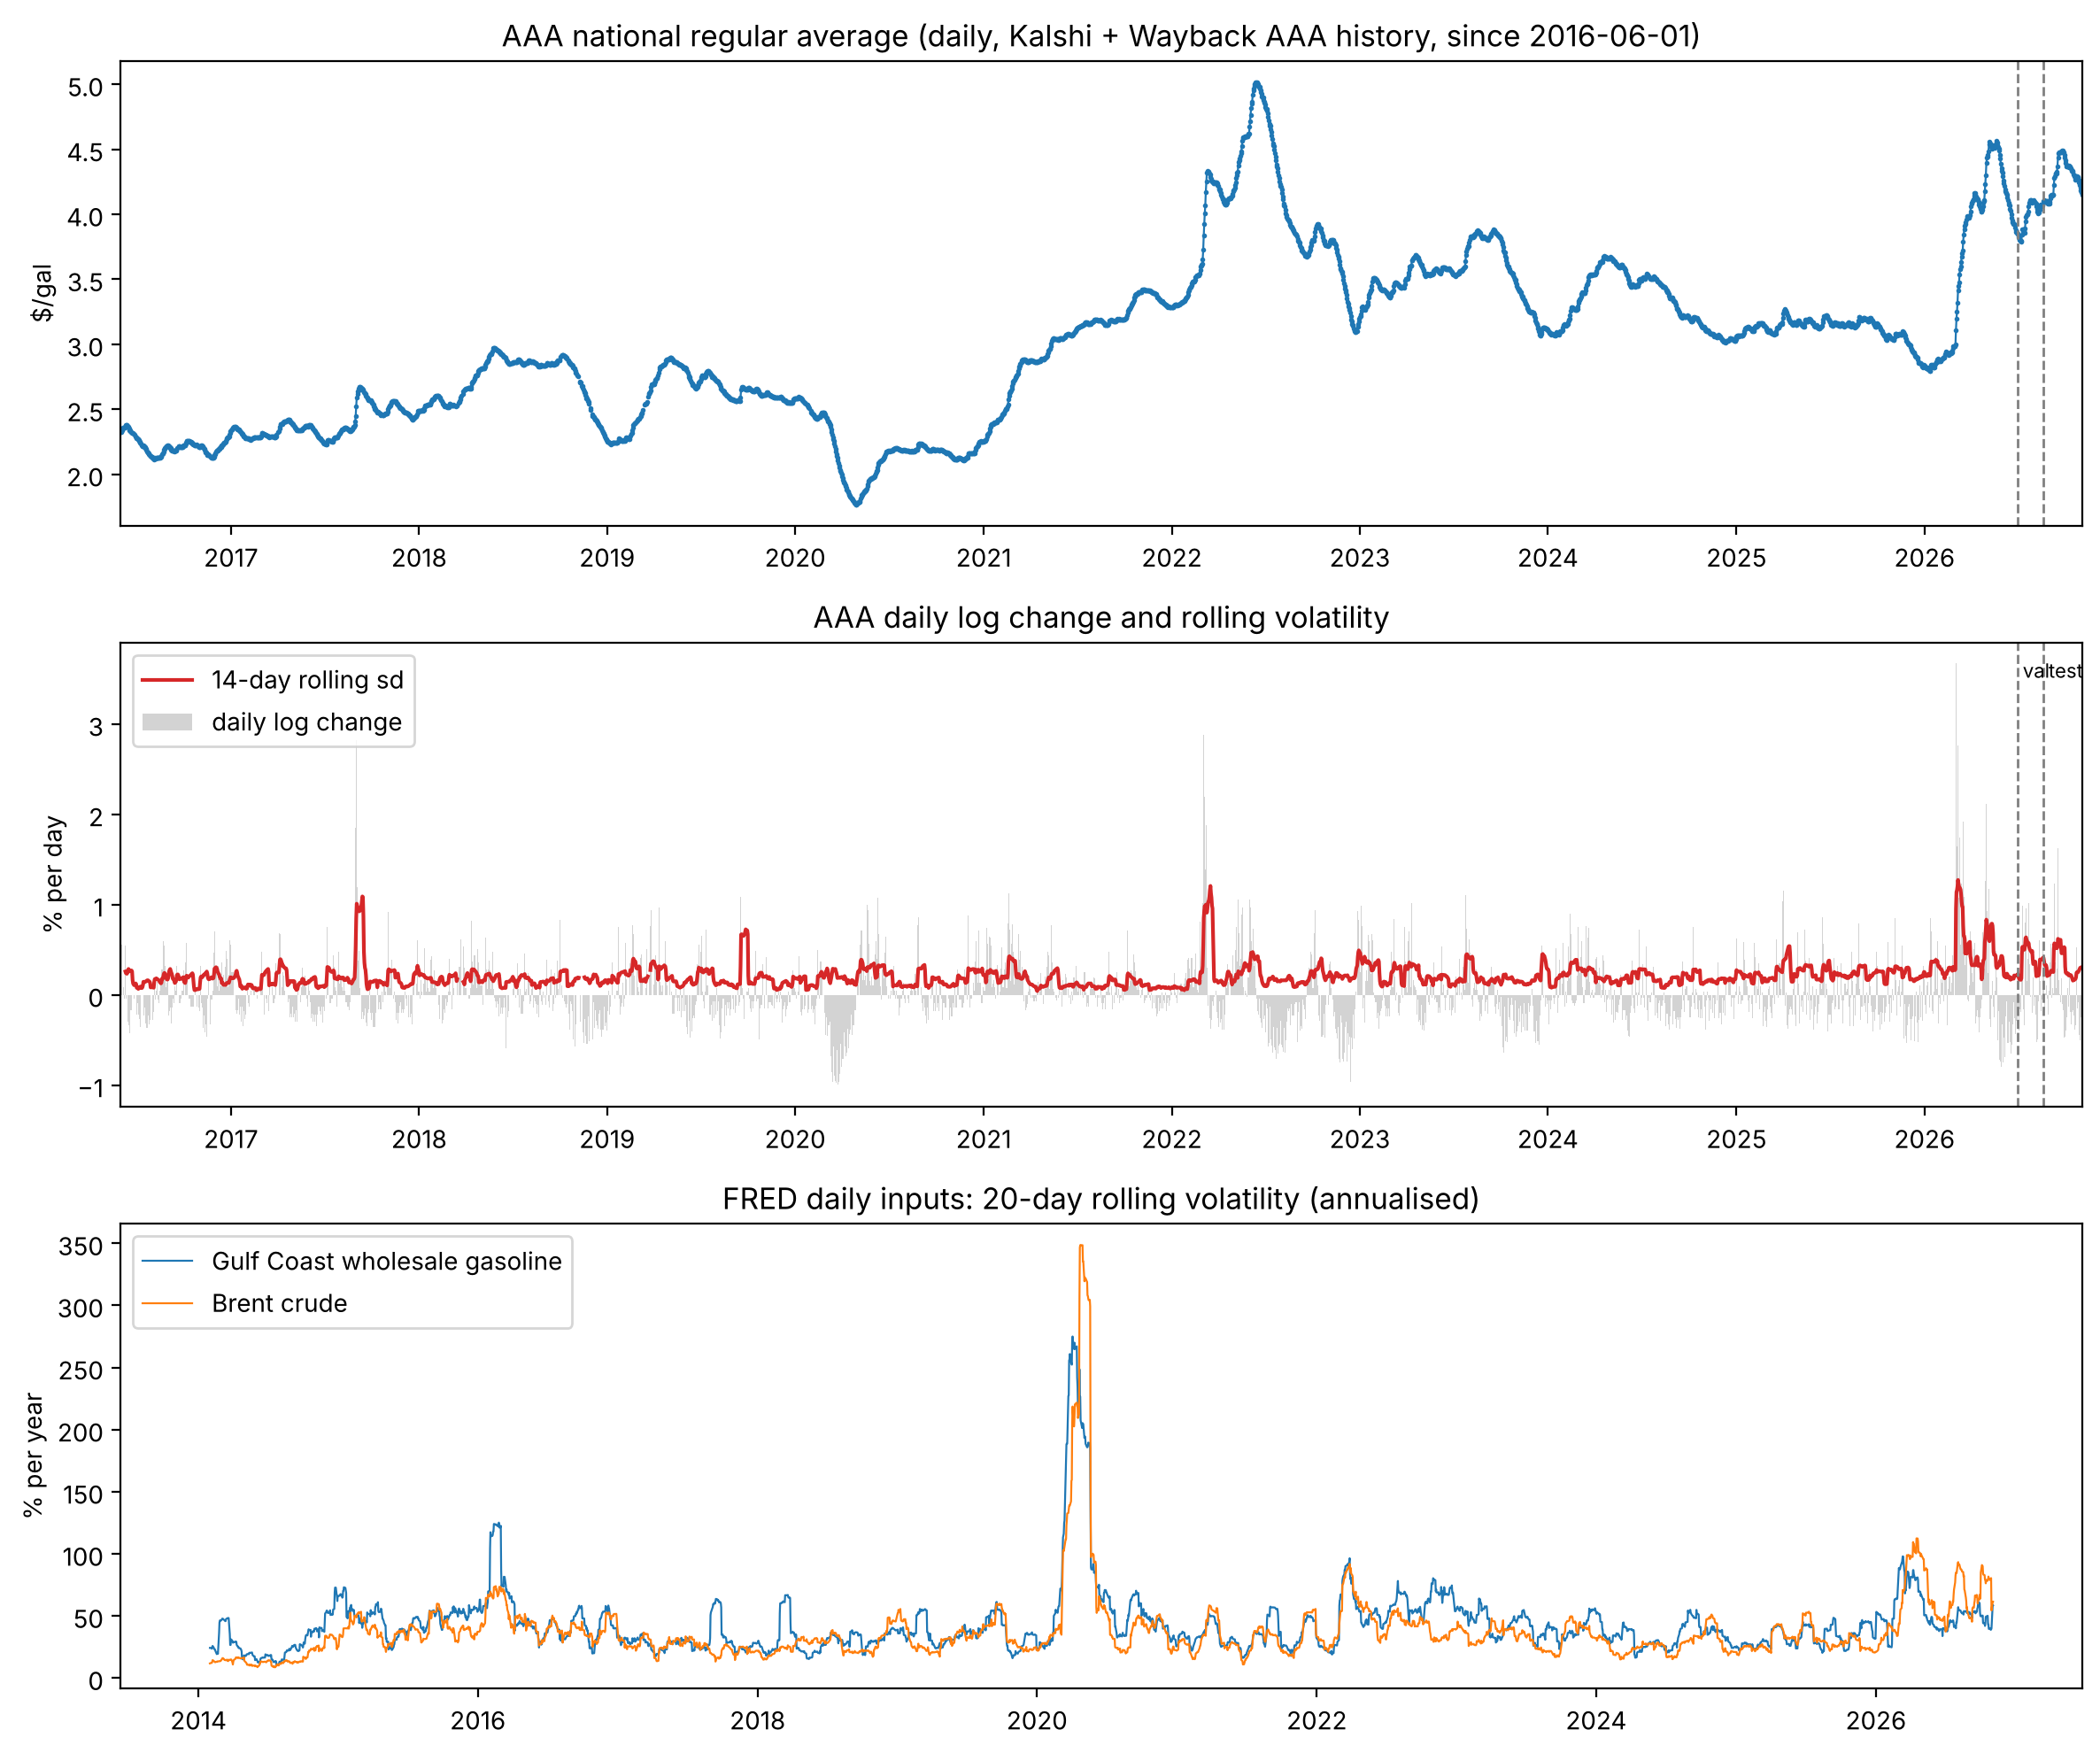

AAA daily: 3727 of 3808 days with a value, 2016-06-01 to 2026-11-03; daily-change sd 0.351% (train 0.347, val 0.462, test 0.429)


date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
sd of daily change (%),0.257,0.35,0.25,0.284,0.352,0.221,0.494,0.305,0.246,0.271,0.598
days,189.000,327.00,318.00,336.000,355.000,365.000,365.000,365.000,366.000,365.000,307.000


In [5]:
# Daily raw data: price levels and volatility over time (AAA daily from Kalshi settlements + Wayback AAA history; FRED daily wholesale/crude)
from gaslab import data as D
_aaa = D.load_aaa_daily().asfreq("D")
_start = pd.Timestamp("2016-06-01")                                  # before this the Wayback series is sparse
_aaa = _aaa.loc[_start:]
_r_aaa = np.log(_aaa).diff() * 100                                   # daily log change, %, only where D-1 is also known
_vol_aaa = _r_aaa.rolling(14, min_periods=7).std()                   # 14-day rolling sd (the daily persistence window)
_f = D.load_fred()
_r_f = np.log(_f[["whsl_gulf", "brent"]].dropna()).diff() * 100     # business-day log changes, %
_vol_f = _r_f.rolling(20).std() * np.sqrt(252)                       # 20-day rolling sd, annualised

fig, ax = plt.subplots(3, 1, figsize=(12, 10))
ax[0].plot(_aaa.index, _aaa.values, ".-", ms=2, lw=0.8, c="C0")
ax[0].set_title(f"AAA national regular average (daily, Kalshi + Wayback AAA history, since {_start:%Y-%m-%d})"); ax[0].set_ylabel("$/gal")
ax[1].bar(_r_aaa.index, _r_aaa.values, width=1, color="lightgray", label="daily log change")
ax[1].plot(_vol_aaa.index, _vol_aaa.values, c="C3", lw=1.5, label="14-day rolling sd")
ax[1].set_title("AAA daily log change and rolling volatility"); ax[1].set_ylabel("% per day"); ax[1].legend(loc="upper left")
for a_ in ax[:2]:
    for d_, lab in [(P.D_SPLIT["train_end"], "train end"), (P.D_SPLIT["val_end"], "val end")]:
        a_.axvline(pd.Timestamp(d_), c="gray", ls="--", lw=1)
    a_.set_xlim(_aaa.index[0], _aaa.index[-1])
ax[1].text(pd.Timestamp(P.D_SPLIT["train_end"]), ax[1].get_ylim()[1] * 0.9, " val", fontsize=8)
ax[1].text(pd.Timestamp(P.D_SPLIT["val_end"]), ax[1].get_ylim()[1] * 0.9, " test", fontsize=8)
ax[2].plot(_vol_f.index, _vol_f.whsl_gulf, lw=0.8, label="Gulf Coast wholesale gasoline")
ax[2].plot(_vol_f.index, _vol_f.brent, lw=0.8, label="Brent crude")
ax[2].set_title("FRED daily inputs: 20-day rolling volatility (annualised)"); ax[2].set_ylabel("% per year"); ax[2].legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"AAA daily: {int(_aaa.notna().sum())} of {len(_aaa)} days with a value, {_start:%Y-%m-%d} to {_aaa.last_valid_index():%Y-%m-%d}; "
      f"daily-change sd {_r_aaa.std():.3f}% (train {_r_aaa.loc[:P.D_SPLIT['train_end']].std():.3f}, "
      f"val {_r_aaa.loc[P.D_SPLIT['train_end']:P.D_SPLIT['val_end']].iloc[1:].std():.3f}, test {_r_aaa.loc[P.D_SPLIT['val_end']:].iloc[1:].std():.3f})")
display(_r_aaa.groupby(_r_aaa.index.to_period("Y")).agg(["std", "count"]).rename(columns={"std": "sd of daily change (%)", "count": "days"}).round(3).T)

### 3.3 Architecture and configuration

* **Persistence**: random walk, Gaussian with rolling standard deviation (26 weeks / 14 days).
* **GARCH(1,1)-t alone**: zero-mean forecast with the GARCH(1,1)-t volatility as its scale, which shows how much of the
  deep models' gain is just the volatility model.
* **Momentum** (daily): tomorrow's change equals today's change.
* **Asymmetric ECM** (statistical baseline): OLS on lagged retail change, positive and negative wholesale changes,
  crude change and the error-correction term (retail margin minus its rolling mean).
* **Gaussian LSTM** (Stage 1 deep baseline): weekly 2 LSTM layers (32, 16 units), daily 1 layer (16 units, dense 8, L2 1e-3,
  smaller because Stage 1 had only 83 complete 7-day training windows; kept unchanged after the AAA data extension, which raised this to 3,181); **activation functions:** tanh (LSTM cell), sigmoid (gates), GELU (dense layer), linear (mean output) and softplus (scale output); orthogonal recurrent init, unit forget
  bias, dropout (0.2 weekly, 0.3 daily), L2 weight penalty (1e-4 weekly, 1e-3 daily).
  Loss: Gaussian negative log-likelihood (a strictly proper scoring rule; Gneiting & Raftery, 2007). Optimizer AdamW (weekly lr 1e-3, daily 3e-3;
  weight decay 1e-4), gradient clipping 1.0, batch 32 (weekly) / 16 (daily), up to 400/600 epochs with early stopping
  on validation NLL (patience 40/60, best weights restored). Lookback 8 weeks / 7 days. Three seeds, averaged as a mixture.
* **Student-t LSTM, no GARCH** (ablation): same network and Student-t head, no GARCH input; scale = softplus(.) + 0.05.
* **GARCH-LSTM-t** (Stage 3 extension, first version): same network plus the one-step GARCH(1,1) volatility as an
  input; Student-t head with scale = (softplus(.) + 0.05)·σ_GARCH and ν = 2.5 + softplus(.); Student-t NLL loss.
  Comparing it with the ablation shows what the GARCH input adds; comparing the ablation with the Gaussian LSTM shows
  what the heavy-tailed head adds.

The daily settings (smaller network, stronger L2, dropout 0.3, lr 3e-3, batch 16, patience 60) were set for the small
daily sample and not tuned: the daily validation window has only 50 days, so tuning on it would overfit the choice.
Daily tuning is part of the Stage 3 plan. The settings were chosen for the 83-window sample and are kept unchanged
for the extended data (3,181 windows), so the effect of the extra data is measured with the same model.

**Metric glossary.** NLL: negative log-likelihood of the realized change under the forecast distribution (changes in
percent, lower is better). CRPS: continuous ranked probability score, in percent (lower is better). MAE: absolute error of
the mean forecast, in percent. dir_acc: share of non-zero changes whose sign was predicted (blank for persistence, which
always predicts zero). cov80: share of outcomes inside the 80% interval (target 0.80). Contract accuracy: share of Kalshi
strikes where p > 0.5 matched the settled YES/NO. ATM: strikes within 1 cent of the previous AAA price, the hard ones.
Brier and log loss: probability scores on the contracts (lower is better).

Every model outputs a predictive distribution for the next log change. A Kalshi strike *k* is then priced as
P(YES) = 1 − F(100·ln(k / A<sub>D−1</sub>)), so one distribution prices the whole strike ladder consistently.

#### ▶ What the next cell does: show the two network architectures

Builds the weekly and the daily GARCH-LSTM-t with exactly the settings used later, without training them, and prints `summary()` for each:
* **weekly:** 8-week lookback over the weekly features;
* **daily:** 7-day lookback, 16 LSTM units, dropout 0.3, L2 penalty 1e-3, a dense layer of 8.

The `head="t"` output layer produces the three parameters of a Student-t distribution (mean, scale, degrees of freedom) instead of one number.

**Output:** the layers, their output shapes and the number of trainable parameters. The daily network is smaller. Its size was set when only 83 daily training windows existed and is kept unchanged now that there are 3,181 (see the data update before the Revisions).

In [6]:
# The two trained architectures (weekly and daily GARCH-LSTM-t), built with the exact settings used below
M.build_lstm(8, len(D.WEEKLY_FEATS), head="t").summary()
M.build_lstm(7, len(D.DAILY_FEATS), units=(16,), dropout=0.3, l2=1e-3, dense=8, head="t").summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 8, 8)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 8, 32)     │      5,248 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 8, 32)     │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 16)        │      3,136 │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 16)        │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        272 │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda (Lambda)     │ (None, 1)         │          0 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_1 (Lambda)   │ (None, 1)         │          0 │ dense_2[0][0],    │
│                     │                   │            │ lambda[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_2 (Lambda)   │ (None, 1)         │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 3)         │          0 │ dense_1[0][0],    │
│ (Concatenate)       │                   │            │ lambda_1[0][0],   │
│                     │                   │            │ lambda_2[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 8,707 (34.01 KB)

 Trainable params: 8,707 (34.01 KB)

 Non-trainable params: 0 (0.00 B)

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 7, 7)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 16)        │      1,536 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 16)        │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 8)         │        136 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_3 (Lambda)   │ (None, 1)         │          0 │ input_layer_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_7 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 1)         │          9 │ dense_4[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_4 (Lambda)   │ (None, 1)         │          0 │ dense_6[0][0],    │
│                     │                   │            │ lambda_3[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lambda_5 (Lambda)   │ (None, 1)         │          0 │ dense_7[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 3)         │          0 │ dense_5[0][0],    │
│ (Concatenate)       │                   │            │ lambda_4[0][0],   │
│                     │                   │            │ lambda_5[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,699 (6.64 KB)

 Trainable params: 1,699 (6.64 KB)

 Non-trainable params: 0 (0.00 B)

#### ▶ What the next cell does: run the weekly Stage 1 experiment

`X.weekly_stage1()` runs the whole weekly comparison:
1. builds 10 years of weekly features from `fred.csv`: retail change, Gulf and NY Harbor wholesale changes, Brent, separate up and down wholesale moves, and the error-correction term;
2. fits GARCH(1,1)-t volatility on 2016–2022 only and adds it as a feature;
3. fits the baselines: persistence, the asymmetric ECM, and GARCH(1,1)-t alone;
4. trains three LSTMs (Gaussian, Student-t without GARCH, GARCH-LSTM-t), each with 3 seeds, and averages each one's seeds into an ensemble;
5. scores every model on validation (2023–24) and test (2025–26).

The results are stored in `s1`.

**Output:** the fitted GARCH parameters, then the comparison table: NLL, CRPS, MAE, direction accuracy, 80% coverage and number of weeks for each model and split. Lower NLL, CRPS and MAE are better; cov80 should be close to 0.80.

In [7]:
s1 = X.weekly_stage1()
print("Weekly GARCH(1,1)-t parameters (fit on 2016-2022):", s1["garch"].round(3).to_dict())
display(s1["table"].set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80", "n"]])

Weekly GARCH(1,1)-t parameters (fit on 2016-2022): {'omega': 0.623, 'alpha[1]': 0.593, 'beta[1]': 0.368, 'nu': 6.913}


NLL    CRPS     MAE  dir_acc   cov80    n
split model                                                                      
test  Asymmetric ECM                 2.3364  1.0694  1.4335   0.6087  0.7717   92
      GARCH(1,1)-t alone             2.0791  1.1716  1.5899      NaN  0.8152   92
      GARCH-LSTM-t (x3)              2.0315  1.0887  1.4592   0.6196  0.7283   92
      Gaussian LSTM (x3)             2.7550  1.1680  1.5238   0.5761  0.7283   92
      Persistence                    2.7232  1.1856  1.5899      NaN  0.7609   92
      Student-t LSTM, no GARCH (x3)  2.0620  1.1140  1.4716   0.6304  0.6848   92
val   Asymmetric ECM                 1.7131  0.7317  1.0208   0.6476  0.9048  105
      GARCH(1,1)-t alone             1.7958  0.8210  1.1642      NaN  0.8571  105
      GARCH-LSTM-t (x3)              1.6972  0.7232  1.0008   0.6762  0.8190  105
      Gaussian LSTM (x3)             1.7655  0.7558  1.0558   0.6381  0.8476  105
      Persistence                    1.8008  0.8204  1.1642      NaN  0.8476  105
      Student-t LSTM, no GARCH (x3)  1.7167  0.7349  1.0320   0.6857  0.8000  105

**Reading.** On the 2025-26 test set (92 weeks) GARCH-LSTM-t has the lowest NLL (2.032) ahead of the Student-t LSTM without GARCH (2.062), the ECM (2.336), persistence (2.723) and the Gaussian LSTM (2.755). The volatility model on its own (GARCH(1,1)-t with a zero mean) reaches 2.079 on test but only 1.796 on validation, worse than every LSTM there, so the network adds more than the volatility model. The ablation separates the two changes: the Student-t head gives most of the gain (2.755 to 2.062), and the GARCH input adds a smaller one (2.062 to 2.032 on test, 1.717 to 1.697 on validation). On point accuracy the ECM is slightly better (MAE 1.434 vs 1.459, CRPS 1.069 vs 1.089), and direction accuracy is only about 0.62 for all three. The GARCH-LSTM-t's 80% interval covers 0.82 of validation weeks but only 0.73 of test weeks (ECM 0.77): its intervals were too narrow for the more volatile test period. So the deep model improves the shape of the forecast distribution, not the point forecast.

#### ▶ What the next cell does: plot the weekly learning curves

Plots training and validation NLL by epoch for the Gaussian LSTM and the GARCH-LSTM-t (seed 0).

**Output:** where the validation curve reaches its minimum (the best epoch, kept by early stopping) and whether it rises afterwards (overfitting).

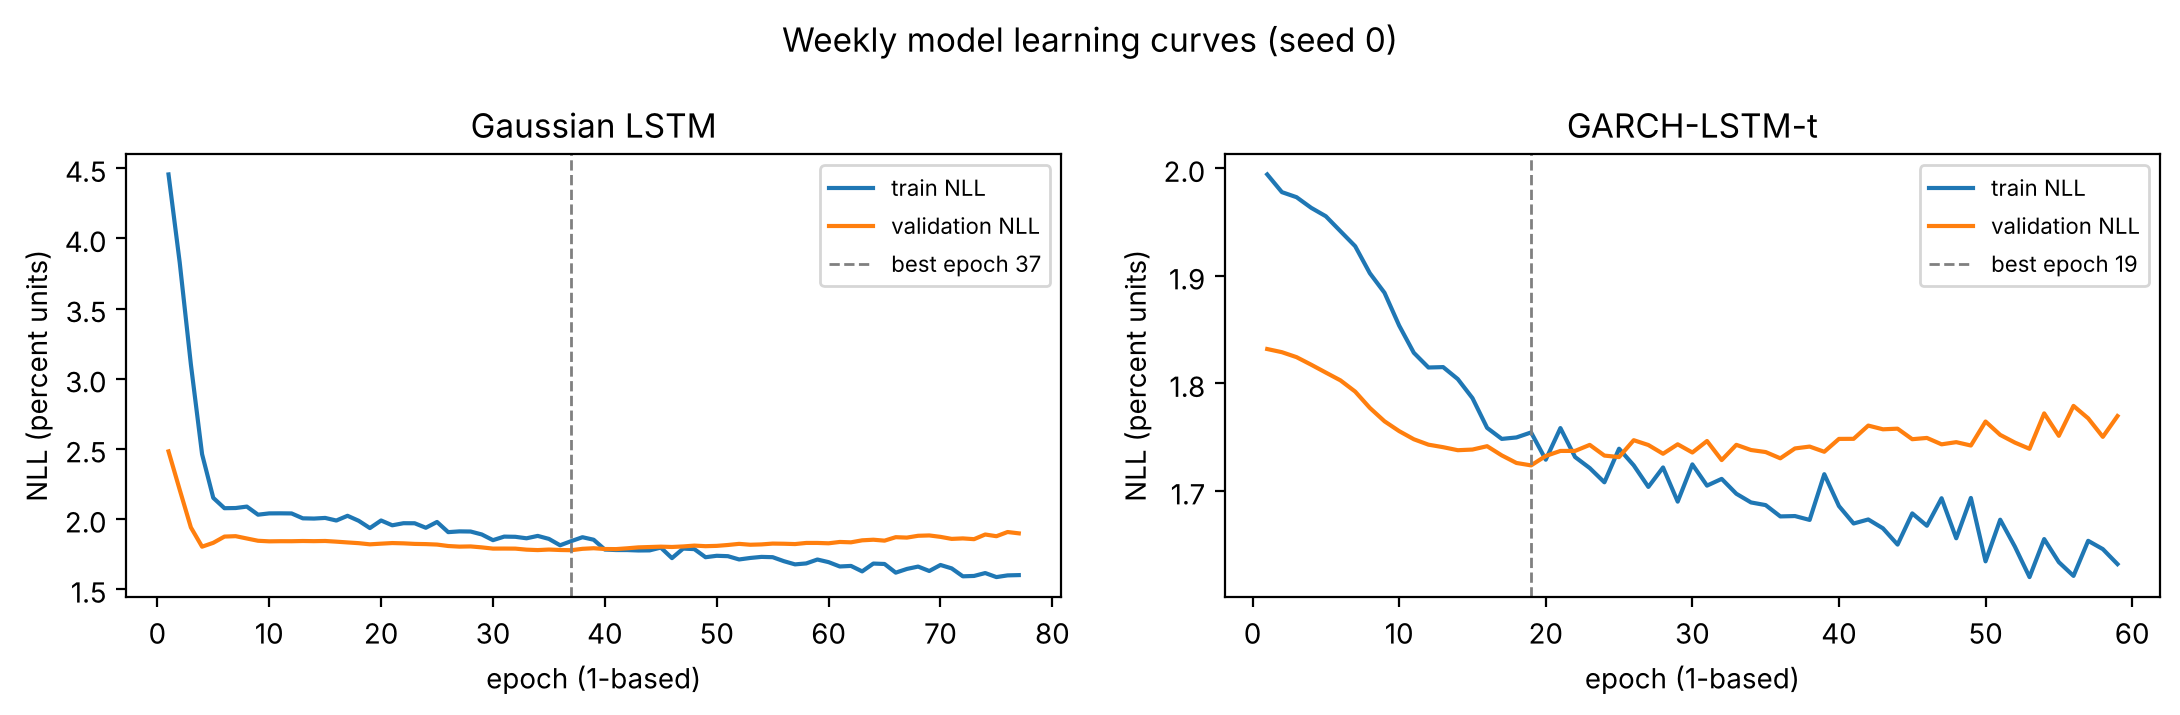

In [8]:
X.plot_learning_curves(s1["runs_g"], s1["runs_t"]); plt.show()

**Reading (learning curves).** Weekly, seed 0. The Gaussian LSTM starts far from a good fit (training NLL 4.5) and converges within about 10 epochs; its validation NLL is lowest at epoch 37. GARCH-LSTM-t starts much closer (training about 2.0, validation 1.83) because the GARCH volatility input anchors its scale, and reaches its validation minimum at epoch 19. In both, training loss keeps falling after the minimum while validation loss rises, which is overfitting that early stopping (best weights restored) removes.

#### ▶ What the next cell does: weekly convergence table

Summarises the training of all nine weekly runs (3 models × 3 seeds): epochs trained, best epoch, training and validation loss at the best and at the last epoch, and the validation-minus-training gap.

**Output:** a gap near 0 at the best epoch means no overfitting yet. A validation loss that is higher at the last epoch than at the best one means early stopping was needed.

In [9]:
conv = X.convergence_table({"Gaussian LSTM": s1["runs_g"], "Student-t LSTM, no GARCH": s1["runs_n"], "GARCH-LSTM-t": s1["runs_t"]})
display(conv.round(3))

,model,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,train_windows,val_minus_train_at_best
0,Gaussian LSTM,0,77,37,1.842,1.777,1.600,1.898,365,-0.065
1,Gaussian LSTM,1,93,53,1.739,1.798,1.540,1.955,365,0.059
2,Gaussian LSTM,2,69,29,1.886,1.794,1.686,1.853,365,-0.093
3,"Student-t LSTM, no GARCH",0,79,39,1.698,1.725,1.504,1.890,365,0.027
4,"Student-t LSTM, no GARCH",1,80,40,1.700,1.729,1.498,1.912,365,0.029
5,"Student-t LSTM, no GARCH",2,61,21,1.762,1.751,1.621,1.800,365,-0.010
6,GARCH-LSTM-t,0,59,19,1.754,1.724,1.632,1.770,365,-0.031
7,GARCH-LSTM-t,1,59,19,1.753,1.708,1.603,1.798,365,-0.044
8,GARCH-LSTM-t,2,93,53,1.656,1.706,1.529,1.830,365,0.049


**Reading.** In all nine weekly runs training loss keeps falling after the best epoch while validation loss rises (GARCH-LSTM-t seed 0: training 1.754 to 1.632, validation 1.724 to 1.770), so early stopping is required. At the best epoch the validation-minus-training gap is small (-0.09 to +0.06). There is no sign of underfitting: training loss can still fall well below its best-epoch value, so capacity is not the limit; generalization is. GARCH-LSTM-t reaches the lowest validation loss (1.706 to 1.724) against the Student-t LSTM without GARCH (1.725 to 1.751) and the Gaussian LSTM (1.777 to 1.798).

#### ▶ What the next cell does: run the daily Stage 1 experiment (Kalshi contracts)

`X.daily_stage(...)` builds the daily model that prices the Kalshi contracts:
1. builds daily features from the AAA daily series (Kalshi settlements plus the Wayback AAA history from June 2015); one of them is the weekly GARCH-LSTM-t forecast (`s1["res"]["GARCH-LSTM-t (x3)"].mu`), so the weekly model feeds the daily one;
2. fits the daily baselines: persistence, momentum, daily ECM, and GARCH alone;
3. trains the three LSTM types with a 7-day lookback, 3 seeds each;
4. turns every forecast distribution into P(YES) for each Kalshi strike and scores it against the settled outcome;
5. adds the Kalshi market price 1 hour after the open as a benchmark.

The results are stored in `ds`.

**Output:** the table with distribution scores (NLL, CRPS, dir_acc) and contract scores (accuracy, ATM accuracy, Brier, log loss, number of contracts and events), then the number of labelled days before July 2026 (3,599) and of complete 7-day training windows (3,181). The test window is Aug 20 – Oct 19 2026 (61 settlement days).

In [10]:
ds = X.daily_stage(s1["res"]["GARCH-LSTM-t (x3)"].mu, lookbacks=(7,), heads=("gauss", "t_nog", "t"))
cols = ["NLL", "CRPS", "dir_acc", "accuracy", "atm_accuracy", "brier", "logloss", "contracts", "events"]
display(ds["table"].set_index(["split", "model"]).sort_index()[cols])
print("Daily labelled days up to 2026-06-30:", int(ds["df"].y.loc[:"2026-06-30"].notna().sum()),
      "| complete 7-day LSTM training windows:", int(ds["runs"][7]["t"][0]["masks"][0].sum()))

NLL    CRPS  dir_acc  accuracy  atm_accuracy   brier  logloss  contracts  events
split model                                                                                                                      
test  Daily ECM                               0.5836  0.1463   0.7541    0.9106        0.8219  0.0706   0.2935       1107      61
      GARCH(1,1)-t alone                      0.2667  0.2001      NaN    0.8726        0.6923  0.0946   0.3523       1107      61
      GARCH-LSTM-t lb7 (x3)                  -0.1218  0.1310   0.8361    0.9151        0.8057  0.0629   0.2561       1107      61
      Gaussian LSTM lb7 (x3)                  0.6959  0.1310   0.8033    0.9133        0.8057  0.0635   0.2589       1107      61
      Kalshi market (9 a.m., 1 h after open)     NaN     NaN      NaN    0.9330        0.8502  0.0489   0.1639       1105      61
      Momentum                                0.4932  0.1784   0.7213    0.8880        0.7773  0.0859   0.3184       1107      61
      Persistence                             0.7089  0.2138      NaN    0.8726        0.6923  0.1023   0.3895       1107      61
      Student-t LSTM, no GARCH lb7 (x3)      -0.1734  0.1259   0.8033    0.9178        0.8057  0.0610   0.2396       1107      61
val   Daily ECM                               0.5981  0.1686   0.7708    0.8981        0.8000  0.0745   0.2911        913      50
      GARCH(1,1)-t alone                      0.5686  0.2454      NaN    0.8510        0.6350  0.1061   0.3656        913      50
      GARCH-LSTM-t lb7 (x3)                  -0.1510  0.1414   0.8125    0.9135        0.8200  0.0632   0.2181        913      50
      Gaussian LSTM lb7 (x3)                  0.2614  0.1411   0.8125    0.9168        0.8250  0.0628   0.2502        913      50
      Kalshi market (9 a.m., 1 h after open)     NaN     NaN      NaN    0.9262        0.8571  0.0527   0.1654        122       7
      Momentum                                0.6954  0.2088   0.7708    0.8828        0.7950  0.0904   0.3264        913      50
      Persistence                             1.0922  0.2558      NaN    0.8510        0.6350  0.1133   0.4163        913      50
      Student-t LSTM, no GARCH lb7 (x3)      -0.1692  0.1332   0.8333    0.9168        0.8200  0.0597   0.2179        913      50

Daily labelled days up to 2026-06-30: 3599 | complete 7-day LSTM training windows: 3181


**Reading.** The daily test covers 61 settlement days (Aug 20 – Oct 19 2026, 1,107 listed strikes). With the Wayback AAA history the LSTMs are trained on 3,181 complete 7-day windows (2015 to June 2026) instead of 83. Persistence and momentum are not trained and score exactly as in the 83-window version (test NLL 0.709 and 0.493), so the test targets are unchanged and the comparison is like for like.

* **Best models.** The two Student-t LSTMs are clearly the best forecasters. Test NLL is −0.173 without GARCH and −0.122 for GARCH-LSTM-t. The other models score 0.267 (GARCH alone), 0.493 (momentum), 0.584 (ECM) and 0.696 (Gaussian LSTM).
* **The GARCH input no longer helps.** With 83 windows, it was the GARCH input that made GARCH-LSTM-t best. With 3,181 windows, the Student-t LSTM without it is slightly better on test (NLL −0.173 vs −0.122, CRPS 0.126 vs 0.131, Brier 0.061 vs 0.063) and on validation (−0.169 vs −0.151).
* **The heavy-tailed head matters, through NLL only.** The Gaussian LSTM has the same CRPS (0.131) and Brier (0.064) as GARCH-LSTM-t, so its mean forecast is as good. Its high NLL comes from a few large moves that its thin tails rate as almost impossible.
* **The deep models now beat momentum on point accuracy.** CRPS is 0.126–0.131 against 0.178, and ATM accuracy 0.806 against 0.777. With 83 windows, momentum had the best CRPS.
* **The market is still better.** The Kalshi price one hour after the open beats every model (accuracy 0.933, ATM 0.850, Brier 0.049 vs 0.061–0.063). Section 5 tests whether that gap is significant. On validation the market benchmark covers only 7 events (122 of 913 contracts), because the order-book history starts in August, so it is not comparable there.

#### ▶ What the next cell does: daily learning curves and convergence table

Same as the two weekly cells above, but for the daily models: the learning curves of the Gaussian LSTM and the GARCH-LSTM-t (seed 0), then the convergence table of all nine daily runs.

**Output:** how early the validation minimum comes and how fast validation loss climbs afterwards. With 3,181 training windows the networks train longer before the validation minimum than they did with 83, but validation loss still rises afterwards.

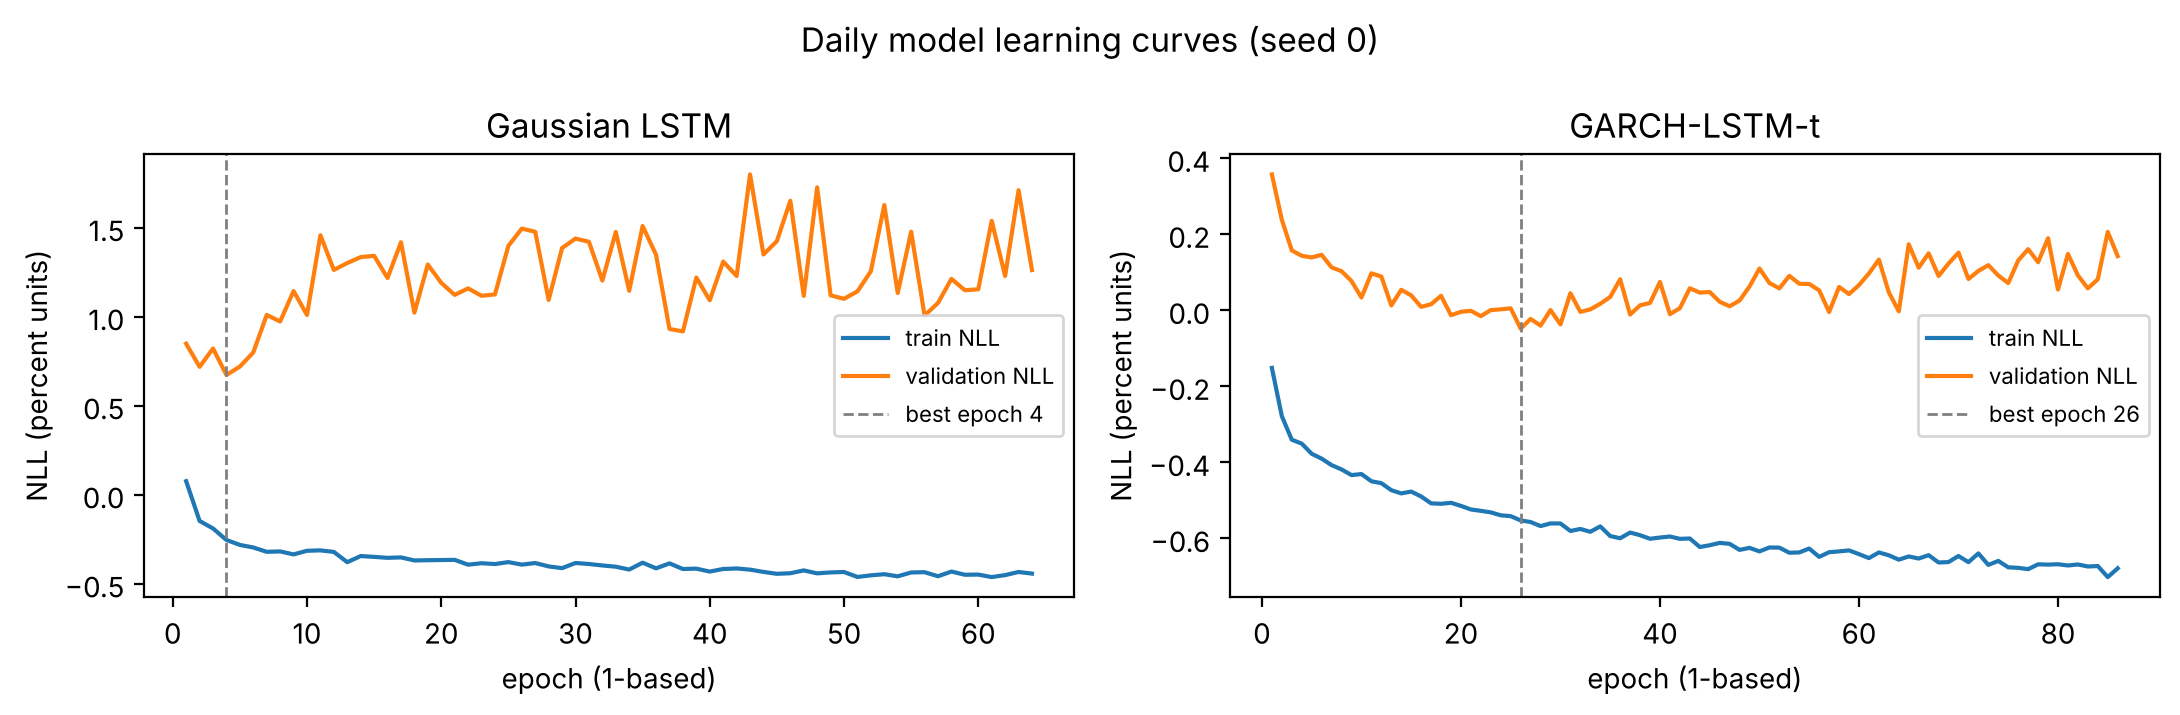

,model,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,train_windows,val_minus_train_at_best
0,Gaussian LSTM (daily),0,64,4,-0.254,0.672,-0.443,1.261,3181,0.926
1,Gaussian LSTM (daily),1,99,39,-0.421,0.380,-0.494,1.447,3181,0.801
2,Gaussian LSTM (daily),2,66,6,-0.313,0.319,-0.461,1.877,3181,0.632
3,"Student-t, no GARCH (daily)",0,68,8,-0.435,0.074,-0.666,0.629,3181,0.508
4,"Student-t, no GARCH (daily)",1,89,29,-0.512,-0.046,-0.683,0.351,3181,0.466
5,"Student-t, no GARCH (daily)",2,109,49,-0.591,-0.212,-0.699,0.005,3181,0.378
6,GARCH-LSTM-t (daily),0,86,26,-0.553,-0.048,-0.679,0.143,3181,0.504
7,GARCH-LSTM-t (daily),1,76,16,-0.481,-0.076,-0.673,0.243,3181,0.405
8,GARCH-LSTM-t (daily),2,75,15,-0.503,-0.107,-0.693,0.197,3181,0.396


In [11]:
X.plot_learning_curves(ds["runs"][7]["gauss"], ds["runs"][7]["t"], title="Daily model learning curves (seed 0)"); plt.show()
display(X.convergence_table({"Gaussian LSTM (daily)": ds["runs"][7]["gauss"], "Student-t, no GARCH (daily)": ds["runs"][7]["t_nog"],
                             "GARCH-LSTM-t (daily)": ds["runs"][7]["t"]}).round(3))

**Reading.** With 3,181 training windows the daily curves are much healthier than with 83.
* **Later, better minimum.** GARCH-LSTM-t reaches its validation minimum at epochs 15–26 (with 83 windows, as early as epoch 2). Its validation NLL at the best epoch is −0.107 to −0.048, against 0.37–0.68 before.
* **Still overfits after the minimum.** Validation loss rises afterwards, to 0.14–0.24 for GARCH-LSTM-t at the last epoch and up to 1.88 for the Gaussian LSTM, so early stopping is still needed.
* **Large train/validation gap.** At the best epoch, validation NLL is 0.38 to 0.93 above training NLL. Training NLL averages over 2015–2026, while validation covers only July–August 2026, so the gap mixes overfitting with a validation period that is harder than average.

The data limit identified in Stage 1 is largely removed. What remains is the overfitting after the minimum and the interval calibration (Revision 3 shows the daily 80% intervals are now too narrow).

## Revisions (Part 2)

The five revisions below build on the Stage 1 results above.

**Data update (2026-11-04).** The daily AAA series was extended from 367 Kalshi settlement values (Sep 2023 – Oct 2026)
to 3,865 days (Jun 2015 – Nov 2026), using Wayback Machine snapshots of gasprices.aaa.com (`data/manual_aaa.csv`).
* **Coverage.** From June 2016 on, 3,727 of 3,808 days have a value (97.9%), and no gap is longer than 2 days. Before June 2016 there are 138 sparse days.
* **Sources.** 3,422 values were read directly from the page. The rest come from the page's week-, month- or year-ago row, which match the directly read values on 99.5%, 98.7% and 87% of overlapping days. `data/manual_aaa_sources.csv` records each value's source.
* **Check against Kalshi.** On days both sources have, the values are identical after aligning on AAA's own "Price as of" date. That check also showed that the Kalshi settlement dates for Sep 2023 – Apr 2024 are shifted by one day; the Wayback values, which take precedence in `load_aaa_daily()`, correct this.
* **Effect.** Daily LSTM training windows grew from 83 to 3,181. All daily numbers in this notebook use the extended data. Weekly results are unchanged, because the weekly model uses EIA data.

**Code change.** The only change to `gaslab/` is that the daily test window now has a fixed end: `X.TE` = Aug 20 – Oct 19 2026,
the last settled Kalshi contract. Newer AAA days therefore do not enter the test set. `results/part2.pkl`, which holds the weekly
frame and forecasts, is saved in the last cell as before. Every new number is computed on the same splits: weekly
validation 2023–2024 and test 2025–26; daily validation Jul 1 – Aug 19 2026 and test Aug 20 – Oct 19 2026. Choices are made on validation data only, and test numbers are reported only after the choice.

| # | Revision | Question it answers |
|---|---|---|
| 1 | Scale calibration of the predictive distributions | Can the too-narrow test intervals (80% coverage 0.73) be fixed without look-ahead? |
| 2 | New baseline: ECM mean + GARCH(1,1)-t on its residuals | Does the LSTM beat a simple statistical model that also has time-varying volatility? |
| 3 | Exact seed-mixture scoring | Does the moment-matched ensemble understate what the 3-seed mixture actually achieves? |
| 4 | Diebold–Mariano tests (with Holm correction) | Are the NLL/CRPS differences in the Stage 1 tables statistically significant? |
| 5 | Daily model: 5 seeds and stronger regularization | Do more seeds or stronger regularization still help once the daily model has 3,181 training windows? |

The next cell defines the helper functions used by all five revisions.

#### ▶ What the next cell does: define the helper functions for Revisions 1–5

Defines the tools the five revisions use; nothing is trained or scored yet. It also sets the split ranges (`WRNG` weekly, `DRNG` daily), short names for the data (`wk`, `dly`, `dcon`) and `REV`, a dictionary that collects the revision tables.
* **Revision 1:** `fit_scale_factor`, `static_calibrate`, `rolling_calibrate` (scale calibration) and `coverage_table` (coverage at 50/80/90/95%).
* **Revision 2:** `ecm_garch_t` (ECM mean + GARCH(1,1)-t fitted on the ECM residuals).
* **Revision 3:** `comps_on`, `mix_logpdf`, `mix_cdf`, `mix_crps`, `mix_metrics`, `price_ladder_mix` (scoring the exact mixture of the seeds).
* **Revision 4:** `dm_test` (Diebold–Mariano test), `holm` (multiple-testing correction), `obs_losses` and `dm_table`.
* **Revision 5:** `run_daily_cfg` (one daily training run with adjustable settings).

**Output:** only the line `revision helpers ready`.

In [12]:
# ===================== Revision helpers (used by Revisions 1-5) =====================
from scipy import stats, optimize
from scipy.special import logsumexp
from arch import arch_model

WRNG = {"val": X.WVA, "test": X.WTE}          # weekly splits (same as the Stage 1 table)
DRNG = {"val": X.VA, "test": X.TE}            # daily splits
wk, dly, dcon = s1["w"], ds["df"], ds["contracts"]
REV = {}                                      # collects the revision tables (saved at the end)


def on(d, rng):
    return d.loc[rng[0]:rng[1]].dropna()


def coverage_table(res, y_series, rngs, levels=(0.5, 0.8, 0.9, 0.95)):
    # central-interval coverage at several nominal levels, from the PIT value F(y)
    rows = []
    for name, d in res.items():
        for lab, r in rngs.items():
            dd = on(d, r); y = y_series.loc[dd.index].values * 100
            u = E.cdf(y, dd.mu.values, dd.scale.values, dd.df.values)
            rows.append({"model": name, "split": lab, "n": len(y),
                         **{f"cov{int(l * 100)} (nominal {l:.2f})": float(np.mean(np.abs(u - 0.5) <= l / 2)) for l in levels}})
    return pd.DataFrame(rows)


# ---------- Revision 1: scale calibration ----------
def fit_scale_factor(y, d, bounds=(0.3, 5.0)):
    # k that minimises the mean NLL of y under the distribution with scale multiplied by k
    mu, sc, nu = d.mu.values, d.scale.values, d.df.values
    f = lambda lk: -np.mean(E.logpdf(y, mu, sc * np.exp(lk), nu))
    return float(np.exp(optimize.minimize_scalar(f, bounds=np.log(bounds), method="bounded").x))


def static_calibrate(d, y_series, fit_rng):
    dd = on(d, fit_rng)
    k = fit_scale_factor(y_series.loc[dd.index].values * 100, dd)
    out = d.copy(); out["scale"] = d.scale * k
    return out, k


def rolling_calibrate(d, y_series, oos_start, window=52, min_obs=13):
    # k_t is fitted on the out-of-sample outcomes BEFORE origin t only (rows after oos_start, at most `window`
    # of them). Row t-1's outcome is known at origin t (weekly: Monday t's EIA price is the outcome of week t-1).
    # Until min_obs out-of-sample outcomes exist, k = 1 (no calibration).
    d = d.dropna(); idx = d.index; yv = y_series.reindex(idx).values * 100
    oos = idx > pd.Timestamp(oos_start)
    k = np.ones(len(d))
    for i in range(len(d)):
        if not oos[i]: continue
        past = np.where(oos[:i] & ~np.isnan(yv[:i]))[0][-window:]
        if len(past) >= min_obs:
            k[i] = fit_scale_factor(yv[past], d.iloc[past])
    out = d.copy(); out["scale"] = d.scale.values * k
    return out, pd.Series(k, index=idx)


# ---------- Revision 2: ECM mean + GARCH(1,1)-t on the ECM residuals ----------
def ecm_garch_t(frame, feats, split, train_start=None):
    ok = frame.dropna(subset=["y"] + feats)
    tr, _, _ = P.split_masks(ok.index, split, train_start)
    ecm, _ = M.ecm_fit_predict(ok, feats, tr)
    e = ok["y"].values * 100 - ecm.mu.values                       # residual of row i is known at origin i+1
    fit = arch_model(e[tr], mean="Zero", vol="GARCH", p=1, q=1, dist="t", rescale=False).fit(disp="off")
    om, al, be, nu = (float(fit.params[k]) for k in ["omega", "alpha[1]", "beta[1]", "nu"])
    s2 = np.empty(len(e)); s2[0] = e[tr].var()
    for i in range(1, len(e)):
        s2[i] = om + al * e[i - 1] ** 2 + be * s2[i - 1]          # sigma^2 for row i uses residuals up to i-1
    out = pd.DataFrame({"mu": ecm.mu.values, "scale": np.sqrt(s2 * (nu - 2) / nu), "df": nu}, index=ok.index)
    return out, pd.Series(dict(omega=om, alpha=al, beta=be, nu=nu, train_obs=int(tr.sum())))


# ---------- Revision 3: exact mixture of the seed distributions ----------
def comps_on(runs, rng):
    parts = [r["dist"].loc[rng[0]:rng[1]].dropna() for r in runs]
    common = parts[0].index
    for p in parts[1:]: common = common.intersection(p.index)
    return [p.loc[common] for p in parts]


def mix_logpdf(y, comps):
    lp = np.stack([E.logpdf(y, c.mu.values, c.scale.values, c.df.values) for c in comps])
    return logsumexp(lp, axis=0) - np.log(len(comps))


def mix_cdf(x, comps):
    return np.mean([E.cdf(x, c.mu.values, c.scale.values, c.df.values) for c in comps], axis=0)


def mix_crps(y, comps, n=2000, seed=0):
    # Monte Carlo CRPS of the equal-weight mixture (same estimator as evaluate.crps_mc)
    rng = np.random.default_rng(seed); K, N = len(comps), len(y)
    mu = np.stack([c.mu.values for c in comps]); sc = np.stack([c.scale.values for c in comps])
    nu = np.stack([c.df.values for c in comps])
    k = rng.integers(0, K, size=(n, N)); col = np.arange(N)
    m, s, v = mu[k, col], sc[k, col], nu[k, col]
    z = np.where(np.isinf(v), rng.standard_normal((n, N)), rng.standard_t(np.where(np.isinf(v), 30, v)))
    x = m + s * z; x2 = np.roll(x, 1, axis=0)
    return np.mean(np.abs(x - y), 0) - 0.5 * np.mean(np.abs(x - x2), 0)


def mix_metrics(y, comps):
    mu = np.mean([c.mu.values for c in comps], axis=0); nz = y != 0
    u = mix_cdf(y, comps)
    return {"NLL": float(-mix_logpdf(y, comps).mean()), "CRPS": float(mix_crps(y, comps).mean()),
            "MAE": float(np.abs(y - mu).mean()), "dir_acc": float((np.sign(mu[nz]) == np.sign(y[nz])).mean()),
            "cov80": float(np.mean(np.abs(u - 0.5) <= 0.4)), "n": int(len(y))}


def price_ladder_mix(contracts, comps):
    c = contracts[contracts.date.isin(comps[0].index)].copy()
    x = 100 * np.log(c.strike.values / c.prev.values)
    p = np.mean([1 - E.cdf(x, d.mu.reindex(c.date).values, d.scale.reindex(c.date).values,
                           d.df.reindex(c.date).values) for d in comps], axis=0)
    c["p"] = np.clip(p, 1e-4, 1 - 1e-4)
    return c


# ---------- Revision 4: Diebold-Mariano test ----------
def dm_test(loss_a, loss_b, h=1, lag=None):
    # H0: equal expected loss. d = loss_a - loss_b (negative mean -> A better). Newey-West (Bartlett) long-run
    # variance with lag floor(T^(1/3)), Harvey-Leybourne-Newbold small-sample correction, t(T-1) reference.
    d = np.asarray(loss_a, float) - np.asarray(loss_b, float); d = d[np.isfinite(d)]; T = len(d)
    lag = int(np.floor(T ** (1 / 3))) if lag is None else lag
    dc = d - d.mean()
    lrv = dc @ dc / T + 2 * sum((1 - j / (lag + 1)) * (dc[j:] @ dc[:-j]) / T for j in range(1, lag + 1))
    dm = d.mean() / np.sqrt(lrv / T)
    dm *= np.sqrt((T + 1 - 2 * h + h * (h - 1) / T) / T)
    return dict(mean_diff=float(d.mean()), DM=float(dm), p_value=float(2 * stats.t.sf(abs(dm), T - 1)), n=T)


def holm(p):
    p = np.asarray(p, float); order = np.argsort(p); m = len(p); adj = np.empty(m); run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * p[i]); adj[i] = min(1.0, run)
    return adj


def obs_losses(d, y_series, idx):
    dd = d.loc[idx]; y = y_series.loc[idx].values * 100
    return {"NLL": -E.logpdf(y, dd.mu.values, dd.scale.values, dd.df.values),
            "CRPS": E.crps_mc(y, dd.mu.values, dd.scale.values, dd.df.values)}   # same seed -> common random numbers


def dm_table(res, ref, others, y_series, rngs, contracts=None):
    rows = []
    for lab, r in rngs.items():
        idx = on(res[ref], r).index
        for o in others: idx = idx.intersection(on(res[o], r).index)
        idx = idx[y_series.loc[idx].notna().values]
        la = obs_losses(res[ref], y_series, idx)
        if contracts is not None:
            ca = E.price_ladder(contracts[contracts.date.isin(idx)], res[ref].loc[idx])
            la["Brier (per day)"] = ((ca.p - ca.y) ** 2).groupby(ca.date).mean().reindex(idx).values
        for o in others:
            lb = obs_losses(res[o], y_series, idx)
            if contracts is not None:
                cb = E.price_ladder(contracts[contracts.date.isin(idx)], res[o].loc[idx])
                lb["Brier (per day)"] = ((cb.p - cb.y) ** 2).groupby(cb.date).mean().reindex(idx).values
            for metric in la:
                rows.append({"split": lab, "metric": metric, "model A": ref, "model B": o, **dm_test(la[metric], lb[metric])})
    t = pd.DataFrame(rows)
    t["p_holm"] = t.groupby(["split", "metric"]).p_value.transform(lambda p: holm(p.values))
    t["verdict"] = np.where(t.p_holm < 0.05, np.where(t.mean_diff < 0, "A better", "B better"), "no significant difference")
    return t


# ---------- Revision 5: daily runs with configurable training settings ----------
def run_daily_cfg(df, seed, lookback=7, units=(16,), dense=8, dropout=0.3, l2=1e-3, lr=3e-3, batch=16,
                  patience=60, epochs=600, head="t"):
    # same as pipeline.run_daily, but patience, batch size and dense width are arguments
    feats = D.DAILY_FEATS if head == "t" else [c for c in D.DAILY_FEATS if c != "garch_sd"]
    Xs, ys, idx = D.sequences(df, feats, lookback)
    tr, va, te = P.split_masks(idx, P.D_SPLIT)
    tr &= ~np.isnan(ys); va &= ~np.isnan(ys)
    sc = M.Scaler(keep_last_raw=head == "t").fit(Xs[tr])
    m, hist = M.train_lstm(sc(Xs[tr]), ys[tr], sc(Xs[va]), ys[va], head=head, lr=lr, seed=seed, epochs=epochs,
                           units=units, dropout=dropout, l2=l2, dense=dense, batch=batch, patience=patience)
    d = M.predict_dist(m, sc(Xs), head); d.index = idx
    return dict(hist=hist, dist=d, idx=idx, y=ys, masks=(tr, va, te))

print("revision helpers ready")

revision helpers ready


## Revision 1: Scale calibration of the weekly predictive distributions

**What I changed.** I added two post-hoc calibrations of the predictive scale, applied to the weekly Gaussian LSTM,
Student-t LSTM (no GARCH), GARCH-LSTM-t and ECM. Each multiplies the model's scale by a factor *k*, with the mean and
tail parameter left unchanged.
* **Static:** a single *k* chosen to minimise NLL on the 2023–24 validation weeks, then applied unchanged to the test.
* **Rolling:** at each forecast origin *t*, *k* is refitted on the out-of-sample outcomes observed before *t* (at most
  52 weeks, all after the training period). Until 13 such weeks exist, *k* = 1. It uses no future data, so it could
  run live.

I also report coverage at 50/80/90/95% instead of 80% only.

**Why.** The Stage 1 reading shows GARCH-LSTM-t's 80% interval covering 0.82 of validation weeks but only 0.73 of
test weeks: the intervals were too narrow for the more volatile 2025–26 period. For a Kalshi strike ladder, a
too-narrow distribution means overconfident YES/NO probabilities, which is exactly where losses come from.

**Result.** Calibration does not fix GARCH-LSTM-t.

The static factors fitted on 2023–24 validation are close to 1 for the deep models: GARCH-LSTM-t k = 0.974, Gaussian LSTM 0.942, Student-t LSTM 0.979 (ECM 0.798). On validation these models were already well calibrated (GARCH-LSTM-t cov80 0.82), so validation gives no signal to widen the intervals.

On test, GARCH-LSTM-t's NLL moves from 2.032 to 2.037 (static) and 2.035 (rolling), and cov80 stays at 0.72–0.73, even though the rolling k ranged from 0.85 to 1.31 during the test period. The coverage table shows why: GARCH-LSTM-t covers only 0.42 at the 50% level but 0.935 at 95%. Its centre is too narrow while its tails are about right. That is a shape problem, and one scale factor cannot correct it.

Rolling calibration does help the models whose scale is less well specified:
* Gaussian LSTM: test NLL 2.755 → 2.487, cov80 0.73 → 0.78.
* Student-t LSTM without GARCH: test NLL 2.062 → 2.046, cov80 0.68 → 0.72.
* ECM: the static factor backfires (test NLL 2.336 → 2.648, cov80 0.68), because it shrinks the intervals to fit the calmer validation years, the opposite of what the volatile test period needed. Rolling k gives the ECM near-nominal coverage (0.80) and a lower CRPS (1.069 → 1.053), but a higher NLL (2.512).

Two caveats:
1. The idea for this revision came from the Stage 1 *test* coverage, so it is not a clean out-of-sample discovery. No parameter was fitted on test, but the test comparisons above should be read with that in mind.
2. With 92 test weeks, a perfectly calibrated model would show cov80 between 0.72 and 0.88 in 95% of samples (binomial). Observing 67 of 92 weeks inside the interval gives a two-sided p of about 0.12. The original "intervals were too narrow" finding is itself only weak evidence.

#### ▶ What the next cell does: run Revision 1 (scale calibration)

For four weekly models, it builds two calibrated versions: one with the static factor *k* fitted on validation, one with a rolling *k* re-fitted each week on past out-of-sample outcomes. It then scores the original and both versions on validation and test, builds the coverage table at four levels for test, and draws two plots.

**Output:** the static *k* values; the table of NLL, CRPS and cov80; the coverage table; a plot of the rolling *k* over time; and a plot of test coverage against nominal coverage (on the dashed diagonal = perfectly calibrated). The last line, `RESULT: …`, summarises the numbers used in the Result text above.

Static scale factors fitted on 2023-24 validation: {'Gaussian LSTM (x3)': 0.942, 'Student-t LSTM, no GARCH (x3)': 0.979, 'GARCH-LSTM-t (x3)': 0.974, 'Asymmetric ECM': 0.798}


NLL    CRPS   cov80    n
split model                                                                 
test  Asymmetric ECM                             2.3364  1.0694  0.7717   92
      Asymmetric ECM + rolling k                 2.5123  1.0532  0.8043   92
      Asymmetric ECM + static k                  2.6478  1.0819  0.6848   92
      GARCH-LSTM-t (x3)                          2.0315  1.0887  0.7283   92
      GARCH-LSTM-t (x3) + rolling k              2.0346  1.0903  0.7283   92
      GARCH-LSTM-t (x3) + static k               2.0372  1.0897  0.7174   92
      Gaussian LSTM (x3)                         2.7550  1.1680  0.7283   92
      Gaussian LSTM (x3) + rolling k             2.4873  1.1582  0.7826   92
      Gaussian LSTM (x3) + static k              2.8881  1.1715  0.7065   92
      Student-t LSTM, no GARCH (x3)              2.0620  1.1140  0.6848   92
      Student-t LSTM, no GARCH (x3) + rolling k  2.0462  1.1073  0.7174   92
      Student-t LSTM, no GARCH (x3) + static k   2.0684  1.1157  0.6739   92
val   Asymmetric ECM                             1.7131  0.7317  0.9048  105
      Asymmetric ECM + rolling k                 1.6761  0.7221  0.8571  105
      Asymmetric ECM + static k                  1.6691  0.7212  0.8000  105
      GARCH-LSTM-t (x3)                          1.6972  0.7232  0.8190  105
      GARCH-LSTM-t (x3) + rolling k              1.7022  0.7265  0.8000  105
      GARCH-LSTM-t (x3) + static k               1.6968  0.7227  0.7810  105
      Gaussian LSTM (x3)                         1.7655  0.7558  0.8476  105
      Gaussian LSTM (x3) + rolling k             1.7598  0.7562  0.8476  105
      Gaussian LSTM (x3) + static k              1.7621  0.7527  0.8286  105
      Student-t LSTM, no GARCH (x3)              1.7167  0.7349  0.8000  105
      Student-t LSTM, no GARCH (x3) + rolling k  1.7209  0.7368  0.8095  105
      Student-t LSTM, no GARCH (x3) + static k   1.7164  0.7348  0.8000  105

n  cov50 (nominal 0.50)  cov80 (nominal 0.80)  cov90 (nominal 0.90)  cov95 (nominal 0.95)
split model                                                                                                                                
test  Gaussian LSTM (x3)                         92                 0.500                 0.728                 0.815                 0.870
      Gaussian LSTM (x3) + static k              92                 0.489                 0.707                 0.772                 0.859
      Gaussian LSTM (x3) + rolling k             92                 0.533                 0.783                 0.837                 0.902
      Student-t LSTM, no GARCH (x3)              92                 0.424                 0.685                 0.837                 0.924
      Student-t LSTM, no GARCH (x3) + static k   92                 0.413                 0.674                 0.837                 0.913
      Student-t LSTM, no GARCH (x3) + rolling k  92                 0.402                 0.717                 0.870                 0.924
      GARCH-LSTM-t (x3)                          92                 0.424                 0.728                 0.859                 0.935
      GARCH-LSTM-t (x3) + static k               92                 0.413                 0.717                 0.848                 0.935
      GARCH-LSTM-t (x3) + rolling k              92                 0.413                 0.728                 0.859                 0.946
      Asymmetric ECM                             92                 0.500                 0.772                 0.859                 0.946
      Asymmetric ECM + static k                  92                 0.424                 0.685                 0.783                 0.837
      Asymmetric ECM + rolling k                 92                 0.457                 0.804                 0.891                 0.935

Note: the static rows are in-sample on validation (k was fitted there); compare them on test.


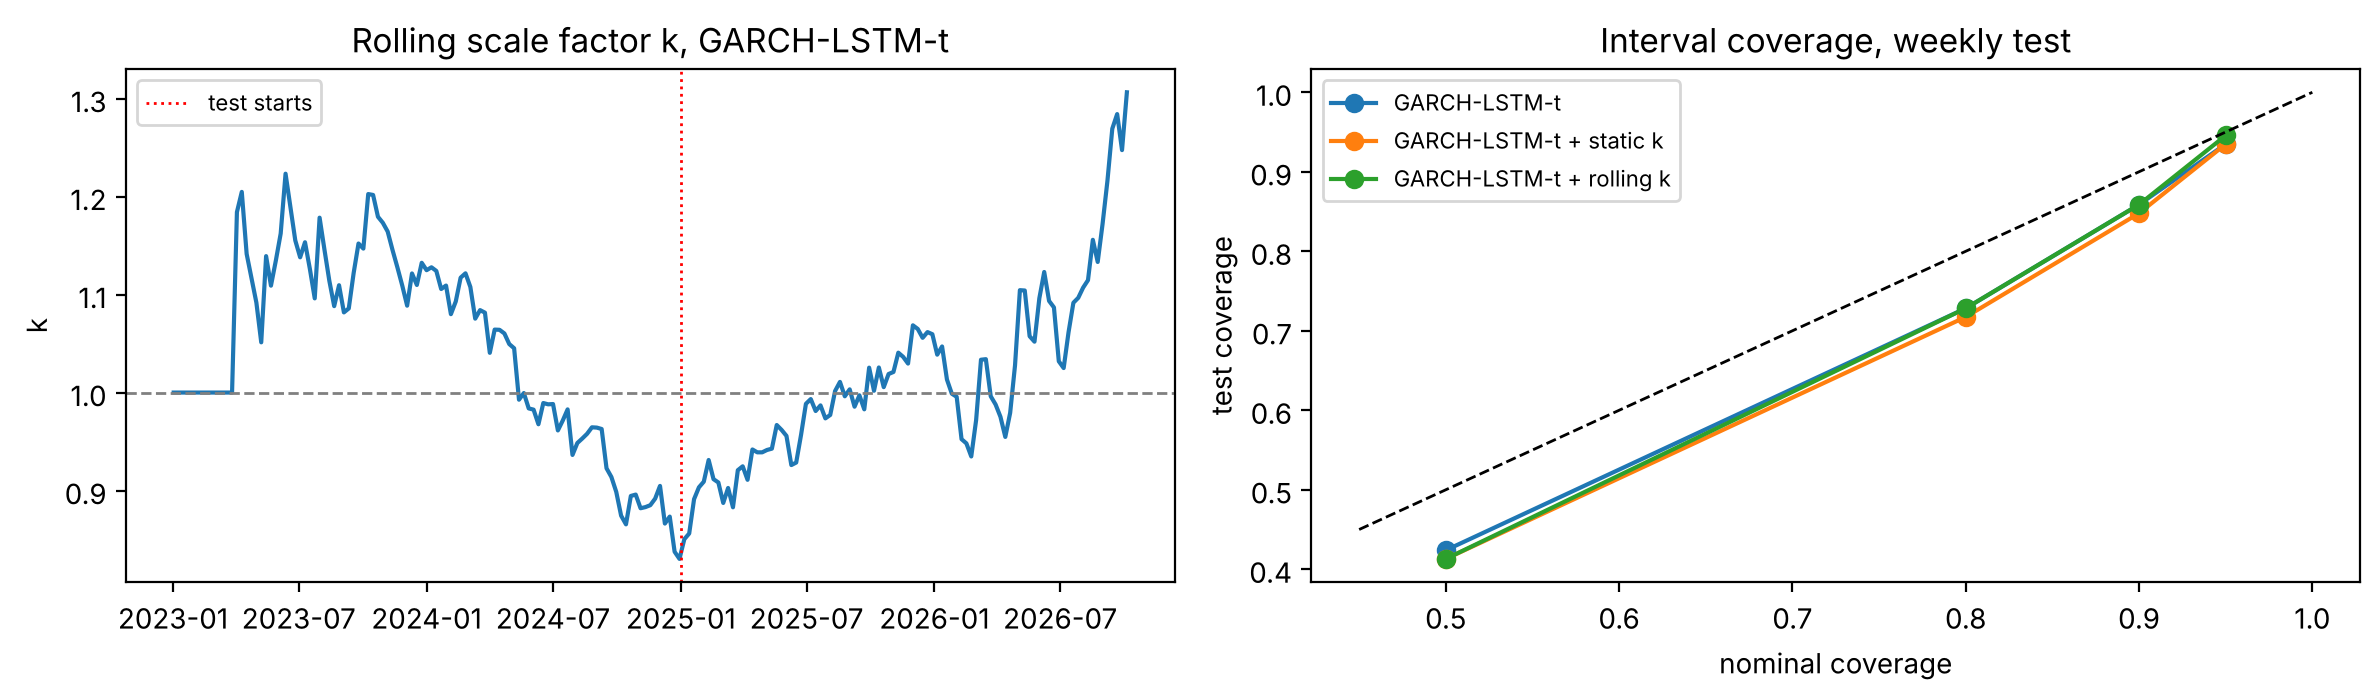

RESULT: GARCH-LSTM-t (x3) test NLL 2.032 -> static 2.037 (k=0.974) -> rolling 2.035; test cov80 0.73 -> 0.72 -> 0.73; rolling k on test ranged 0.85-1.31


In [13]:
cal_models = ["Gaussian LSTM (x3)", "Student-t LSTM, no GARCH (x3)", "GARCH-LSTM-t (x3)", "Asymmetric ECM"]
res_cal, k_static, k_roll = {}, {}, {}
for name in cal_models:
    d = s1["res"][name]
    d_st, k_static[name] = static_calibrate(d, wk["y"], X.WVA)
    d_ro, k_roll[name] = rolling_calibrate(d, wk["y"], oos_start=P.W_SPLIT["train_end"])
    res_cal[name] = d
    res_cal[name + " + static k"] = d_st
    res_cal[name + " + rolling k"] = d_ro

print("Static scale factors fitted on 2023-24 validation:", {k: round(v, 3) for k, v in k_static.items()})
cal_tab = X._rows(res_cal, wk["y"], WRNG)[["split", "model", "NLL", "CRPS", "cov80", "n"]]
display(cal_tab.set_index(["split", "model"]).sort_index().round(4))
cov_tab = coverage_table(res_cal, wk["y"], {"test": X.WTE})
display(cov_tab.set_index(["split", "model"]).round(3))
REV["r1_calibration"], REV["r1_coverage"] = cal_tab, cov_tab
print("Note: the static rows are in-sample on validation (k was fitted there); compare them on test.")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
kr = k_roll["GARCH-LSTM-t (x3)"].loc[X.WVA[0]:]
ax[0].plot(kr.index, kr.values); ax[0].axhline(1, c="gray", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(X.WTE[0]), c="r", ls=":", lw=1, label="test starts")
ax[0].set_title("Rolling scale factor k, GARCH-LSTM-t"); ax[0].set_ylabel("k"); ax[0].legend(fontsize=8)
lev = [0.5, 0.8, 0.9, 0.95]
for nm in ["GARCH-LSTM-t (x3)", "GARCH-LSTM-t (x3) + static k", "GARCH-LSTM-t (x3) + rolling k"]:
    row = cov_tab[cov_tab.model == nm].iloc[0]
    ax[1].plot(lev, [row[f"cov{int(l * 100)} (nominal {l:.2f})"] for l in lev], "o-", label=nm.replace("GARCH-LSTM-t (x3)", "GARCH-LSTM-t"))
ax[1].plot([0.45, 1], [0.45, 1], "k--", lw=1); ax[1].set_xlabel("nominal coverage"); ax[1].set_ylabel("test coverage")
ax[1].set_title("Interval coverage, weekly test"); ax[1].legend(fontsize=8); fig.tight_layout(); plt.show()

t = cal_tab[cal_tab.split == "test"].set_index("model")
g = "GARCH-LSTM-t (x3)"
print(f"RESULT: {g} test NLL {t.loc[g, 'NLL']:.3f} -> static {t.loc[g + ' + static k', 'NLL']:.3f} "
      f"(k={k_static[g]:.3f}) -> rolling {t.loc[g + ' + rolling k', 'NLL']:.3f}; test cov80 {t.loc[g, 'cov80']:.2f} -> "
      f"{t.loc[g + ' + static k', 'cov80']:.2f} -> {t.loc[g + ' + rolling k', 'cov80']:.2f}; "
      f"rolling k on test ranged {kr.loc[X.WTE[0]:].min():.2f}-{kr.loc[X.WTE[0]:].max():.2f}")

## Revision 2: New statistical baseline: ECM mean + GARCH(1,1)-t on the ECM residuals

**What I changed.** I added an **ECM-GARCH-t** baseline, weekly and daily. The mean is the same asymmetric ECM
(OLS on the training split). The scale comes from a GARCH(1,1) with Student-t errors, fitted to the ECM's
**training residuals** and then run forward with fixed parameters. The variance for row *t* uses residuals up to
*t−1* only, so there is no look-ahead. I report it on the same metrics as Stage 1, including the Kalshi contract
metrics for the daily version.

**Why.** Stage 1 compares GARCH-LSTM-t against an ECM with a *constant* scale and a GARCH model with a *zero* mean.
Neither has both a good mean and time-varying volatility. That leaves open whether the LSTM's NLL advantage comes
from the network or just from combining those two pieces. This baseline is the strongest simple econometric
competitor, so beating it is the fair test of the deep model.

**Result.** On the weekly data, this simple model is the best forecaster in the table.

ECM-GARCH-t has the lowest NLL on both splits: validation 1.689 (GARCH-LSTM-t 1.697, ECM 1.713) and test 1.999 (GARCH-LSTM-t 2.032, ECM 2.336). It also has the lowest CRPS on both: validation 0.722 vs 0.723, test 1.054 vs 1.089. Its 80% coverage is 0.80 on validation and 0.77 on test, against 0.82 and 0.73 for GARCH-LSTM-t. Because it uses the ECM's mean, its MAE (1.434 on test) and direction accuracy (0.61) are the same as the ECM's. The fitted GARCH is persistent (α = 0.085, β = 0.812, ν = 5.0).

Adding GARCH volatility to the ECM therefore closes, and slightly reverses, the gap to the LSTM. On weekly data, the deep model's advantage over the constant-scale ECM comes from time-varying volatility, not from the network.

On the daily data the picture is different. ECM-GARCH-t is a large improvement over the daily ECM: test NLL 0.032 vs 0.584, validation 0.223 vs 0.598. Its GARCH is now fitted on 3,435 residuals instead of 92. Because it keeps the ECM mean, its CRPS and Brier are almost the same as the ECM's (test Brier 0.0705 vs 0.0706).

GARCH-LSTM-t stays ahead on both splits: validation NLL −0.151, test −0.122, with test Brier 0.0629 vs 0.0705 and CRPS 0.131 vs 0.148. Unlike on weekly data, the daily network improves the mean forecast as well as the scale. Revision 4 tests whether these gaps are significant.

#### ▶ What the next cell does: run Revision 2 (ECM-GARCH-t baseline)

Fits the new ECM-GARCH-t model on the weekly and the daily data and prints its GARCH parameters. It then compares it with persistence, the ECM, GARCH alone and GARCH-LSTM-t, weekly and daily (the daily table includes the Kalshi contract scores).

**Output:** the parameter table (omega, alpha, beta, nu, number of training residuals), the weekly and daily comparison tables, and two `RESULT:` lines with the key NLL numbers.

In [14]:
eg_w, eg_w_par = ecm_garch_t(wk, P.ECM_W, P.W_SPLIT, P.W_SPLIT["train_start"])
eg_d, eg_d_par = ecm_garch_t(dly, P.ECM_D, P.D_SPLIT)
display(pd.DataFrame({"weekly": eg_w_par, "daily": eg_d_par}).round(4))

res_w2 = {k: s1["res"][k] for k in ["Persistence", "Asymmetric ECM", "GARCH(1,1)-t alone", "GARCH-LSTM-t (x3)"]}
res_w2["ECM-GARCH-t (new)"] = eg_w
tab_w2 = X._rows(res_w2, wk["y"], WRNG)
display(tab_w2.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80", "n"]].round(4))

d_names = ["Persistence", "Momentum", "Daily ECM", "GARCH(1,1)-t alone", "GARCH-LSTM-t lb7 (x3)"]
res_d2 = {k: ds["res"][k] for k in d_names if k in ds["res"]}
res_d2["ECM-GARCH-t (new)"] = eg_d
tab_d2 = X._rows(res_d2, dly["y"], DRNG, dcon)
display(tab_d2.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "dir_acc", "accuracy", "atm_accuracy", "brier", "logloss", "contracts", "events"]].round(4))
REV["r2_weekly"], REV["r2_daily"] = tab_w2, tab_d2

tw, td = tab_w2[tab_w2.split == "test"].set_index("model"), tab_d2[tab_d2.split == "test"].set_index("model")
print(f"RESULT weekly test NLL: ECM {tw.loc['Asymmetric ECM', 'NLL']:.3f} | ECM-GARCH-t {tw.loc['ECM-GARCH-t (new)', 'NLL']:.3f} | "
      f"GARCH-LSTM-t {tw.loc['GARCH-LSTM-t (x3)', 'NLL']:.3f}")
print(f"RESULT daily test NLL: ECM {td.loc['Daily ECM', 'NLL']:.3f} | ECM-GARCH-t {td.loc['ECM-GARCH-t (new)', 'NLL']:.3f} | "
      f"GARCH-LSTM-t {td.loc['GARCH-LSTM-t lb7 (x3)', 'NLL']:.3f}; Brier {td.loc['ECM-GARCH-t (new)', 'brier']:.3f} vs "
      f"{td.loc['GARCH-LSTM-t lb7 (x3)', 'brier']:.3f}")

,weekly,daily
omega,0.2244,0.0008
alpha,0.0848,0.0500
beta,0.8118,0.9300
nu,5.0024,4.4879
train_obs,365.0000,3435.0000


NLL    CRPS     MAE  dir_acc   cov80    n
split model                                                           
test  Asymmetric ECM      2.3364  1.0694  1.4335   0.6087  0.7717   92
      ECM-GARCH-t (new)   1.9988  1.0536  1.4335   0.6087  0.7717   92
      GARCH(1,1)-t alone  2.0791  1.1716  1.5899      NaN  0.8152   92
      GARCH-LSTM-t (x3)   2.0315  1.0887  1.4592   0.6196  0.7283   92
      Persistence         2.7232  1.1856  1.5899      NaN  0.7609   92
val   Asymmetric ECM      1.7131  0.7317  1.0208   0.6476  0.9048  105
      ECM-GARCH-t (new)   1.6885  0.7215  1.0208   0.6476  0.8000  105
      GARCH(1,1)-t alone  1.7958  0.8210  1.1642      NaN  0.8571  105
      GARCH-LSTM-t (x3)   1.6972  0.7232  1.0008   0.6762  0.8190  105
      Persistence         1.8008  0.8204  1.1642      NaN  0.8476  105

NLL    CRPS  dir_acc  accuracy  atm_accuracy   brier  logloss  contracts  events
split model                                                                                                     
test  Daily ECM              0.5836  0.1463   0.7541    0.9106        0.8219  0.0706   0.2935       1107      61
      ECM-GARCH-t (new)      0.0323  0.1477   0.7541    0.9106        0.8219  0.0705   0.2702       1107      61
      GARCH(1,1)-t alone     0.2667  0.2001      NaN    0.8726        0.6923  0.0946   0.3523       1107      61
      GARCH-LSTM-t lb7 (x3) -0.1218  0.1310   0.8361    0.9151        0.8057  0.0629   0.2561       1107      61
      Momentum               0.4932  0.1784   0.7213    0.8880        0.7773  0.0859   0.3184       1107      61
      Persistence            0.7089  0.2138      NaN    0.8726        0.6923  0.1023   0.3895       1107      61
val   Daily ECM              0.5981  0.1686   0.7708    0.8981        0.8000  0.0745   0.2911        913      50
      ECM-GARCH-t (new)      0.2229  0.1673   0.7708    0.8981        0.8000  0.0741   0.2620        913      50
      GARCH(1,1)-t alone     0.5686  0.2454      NaN    0.8510        0.6350  0.1061   0.3656        913      50
      GARCH-LSTM-t lb7 (x3) -0.1510  0.1414   0.8125    0.9135        0.8200  0.0632   0.2181        913      50
      Momentum               0.6954  0.2088   0.7708    0.8828        0.7950  0.0904   0.3264        913      50
      Persistence            1.0922  0.2558      NaN    0.8510        0.6350  0.1133   0.4163        913      50

RESULT weekly test NLL: ECM 2.336 | ECM-GARCH-t 1.999 | GARCH-LSTM-t 2.032
RESULT daily test NLL: ECM 0.584 | ECM-GARCH-t 0.032 | GARCH-LSTM-t -0.122; Brier 0.070 vs 0.063


## Revision 3: Score the 3-seed ensemble as an exact mixture

**What I changed.** `pipeline.ensemble()` averages the three seeds by **moment matching**: it collapses the
mixture into one Student-t with the mixture's mean and variance and an averaged degrees of freedom. I now also score
the **exact equal-weight mixture**:
* density = mean of the three densities (log-sum-exp for NLL);
* CDF and contract probabilities = mean of the three CDFs;
* CRPS by sampling from the mixture.

I compare it against the moment-matched version and against the average single seed, for the weekly and daily
Gaussian, Student-t (no GARCH) and GARCH-LSTM-t models.

**Why.** The moment-matched t has the right mean and variance, but not the right shape: the mixture is wider in the
shoulders and its tails depend on each seed's own ν. NLL and strike probabilities depend on the whole shape. So the
Stage 1 numbers may misstate what the ensemble really forecasts. The single-seed rows also show how much the
ensemble itself adds.

**Result.** For the main model, the scoring method makes little difference.
* Weekly GARCH-LSTM-t: exact mixture 2.031 vs moment-matched 2.032 on test, and 1.695 vs 1.697 on validation.
* Daily GARCH-LSTM-t: −0.120 vs −0.122 on test and −0.143 vs −0.151 on validation, with Brier 0.0629 vs 0.0629.

The Stage 1 numbers for the reported model are therefore reliable.

The exception is the Gaussian LSTM. Its weekly test NLL is 2.572 as an exact mixture but 2.755 moment-matched. Collapsing three Gaussians into one Gaussian throws away the heavier tails of the mixture, and the volatile test period punishes that. As a result, the Stage 1 ablation overstates the Student-t head's contribution on weekly test data: measured with exact mixtures, the gain is 2.572 → 2.068 rather than 2.755 → 2.062. On weekly validation the two scoring methods agree for every model. On daily data the effect is mixed: the exact mixture is better on validation (0.187 vs 0.261) but worse on test (0.737 vs 0.696).

Ensembling itself clearly helps. Compared with the average single seed, the 3-seed ensemble lowers:
* weekly test NLL from 2.041 to 2.031;
* daily test NLL from −0.086 to −0.120;
* daily test Brier from 0.0640 to 0.0629.

Daily calibration has reversed since the data extension. With 83 windows the daily ensemble was too wide (cov80 0.93). Now it is too narrow: GARCH-LSTM-t covers 0.72 of test days and 0.74 of validation days at 80% (single seeds 0.68 and 0.72). A scale calibration like Revision 1's, fitted on daily validation, is the natural next step.

#### ▶ What the next cell does: run Revision 3 (exact mixture vs moment matching)

`ensemble_compare` scores each LSTM family in three ways on validation and test: the average single seed, the Stage 1 moment-matched ensemble, and the exact mixture of the seeds. It does this weekly and daily, and adds the contract scores for the daily models.

**Output:** the weekly and daily comparison tables and two `RESULT:` lines for GARCH-LSTM-t.

In [15]:
def ensemble_compare(families, y_series, rngs, contracts=None):
    rows = []
    for fam, (runs, mm) in families.items():
        for lab, r in rngs.items():
            comps = comps_on(runs, r); idx = comps[0].index; y = y_series.loc[idx].values * 100
            single = pd.DataFrame([E.dist_metrics(y, c) for c in comps]).mean()
            variants = {"single seed (mean of 3)": single.to_dict(),
                        "moment-matched (Stage 1)": E.dist_metrics(y, mm.loc[idx]),
                        "exact mixture (new)": mix_metrics(y, comps)}
            if contracts is not None:
                cc = contracts[contracts.date.isin(idx)]
                variants["single seed (mean of 3)"].update(pd.DataFrame([E.contract_metrics(E.price_ladder(cc, c)) for c in comps]).mean().to_dict())
                variants["moment-matched (Stage 1)"].update(E.contract_metrics(E.price_ladder(cc, mm.loc[idx])))
                variants["exact mixture (new)"].update(E.contract_metrics(price_ladder_mix(cc, comps)))
            for v, m in variants.items():
                rows.append({"model": fam, "split": lab, "ensemble": v, **m})
    return pd.DataFrame(rows)

fam_w = {"Gaussian LSTM": (s1["runs_g"], s1["res"]["Gaussian LSTM (x3)"]),
         "Student-t LSTM, no GARCH": (s1["runs_n"], s1["res"]["Student-t LSTM, no GARCH (x3)"]),
         "GARCH-LSTM-t": (s1["runs_t"], s1["res"]["GARCH-LSTM-t (x3)"])}
mix_w = ensemble_compare(fam_w, wk["y"], WRNG)
display(mix_w.set_index(["split", "model", "ensemble"]).sort_index()[["NLL", "CRPS", "MAE", "cov80", "n"]].round(4))

r7 = ds["runs"][7]
fam_d = {"Gaussian LSTM": (r7["gauss"], ds["res"]["Gaussian LSTM lb7 (x3)"]),
         "Student-t LSTM, no GARCH": (r7["t_nog"], ds["res"]["Student-t LSTM, no GARCH lb7 (x3)"]),
         "GARCH-LSTM-t": (r7["t"], ds["res"]["GARCH-LSTM-t lb7 (x3)"])}
mix_d = ensemble_compare(fam_d, dly["y"], DRNG, dcon)
display(mix_d.set_index(["split", "model", "ensemble"]).sort_index()[["NLL", "CRPS", "cov80", "accuracy", "brier", "logloss", "n"]].round(4))
REV["r3_weekly"], REV["r3_daily"] = mix_w, mix_d

for nm, tb in [("weekly", mix_w), ("daily", mix_d)]:
    t = tb[(tb.split == "test") & (tb.model == "GARCH-LSTM-t")].set_index("ensemble")
    print(f"RESULT {nm} test GARCH-LSTM-t NLL: single {t.loc['single seed (mean of 3)', 'NLL']:.3f} | "
          f"moment-matched {t.loc['moment-matched (Stage 1)', 'NLL']:.3f} | exact mixture {t.loc['exact mixture (new)', 'NLL']:.3f}"
          + (f" | Brier {t.loc['moment-matched (Stage 1)', 'brier']:.4f} vs {t.loc['exact mixture (new)', 'brier']:.4f}" if nm == "daily" else ""))

NLL    CRPS     MAE   cov80      n
split model                    ensemble                                                       
test  GARCH-LSTM-t             exact mixture (new)       2.0306  1.0840  1.4592  0.7283   92.0
                               moment-matched (Stage 1)  2.0315  1.0887  1.4592  0.7283   92.0
                               single seed (mean of 3)   2.0406  1.0905  1.4612  0.7319   92.0
      Gaussian LSTM            exact mixture (new)       2.5724  1.1685  1.5238  0.7174   92.0
                               moment-matched (Stage 1)  2.7550  1.1680  1.5238  0.7283   92.0
                               single seed (mean of 3)   2.9203  1.1791  1.5329  0.7138   92.0
      Student-t LSTM, no GARCH exact mixture (new)       2.0683  1.1114  1.4716  0.6739   92.0
                               moment-matched (Stage 1)  2.0620  1.1140  1.4716  0.6848   92.0
                               single seed (mean of 3)   2.0895  1.1231  1.4787  0.6848   92.0
val   GARCH-LSTM-t             exact mixture (new)       1.6947  0.7197  1.0008  0.8095  105.0
                               moment-matched (Stage 1)  1.6972  0.7232  1.0008  0.8190  105.0
                               single seed (mean of 3)   1.7042  0.7285  1.0048  0.8063  105.0
      Gaussian LSTM            exact mixture (new)       1.7652  0.7574  1.0558  0.8381  105.0
                               moment-matched (Stage 1)  1.7655  0.7558  1.0558  0.8476  105.0
                               single seed (mean of 3)   1.7809  0.7652  1.0691  0.8286  105.0
      Student-t LSTM, no GARCH exact mixture (new)       1.7146  0.7325  1.0320  0.8000  105.0
                               moment-matched (Stage 1)  1.7167  0.7349  1.0320  0.8000  105.0
                               single seed (mean of 3)   1.7266  0.7423  1.0354  0.7905  105.0

NLL    CRPS   cov80  accuracy   brier  logloss     n
split model                    ensemble                                                                         
test  GARCH-LSTM-t             exact mixture (new)      -0.1202  0.1311  0.7213    0.9151  0.0629   0.2561  61.0
                               moment-matched (Stage 1) -0.1218  0.1310  0.7213    0.9151  0.0629   0.2561  61.0
                               single seed (mean of 3)  -0.0856  0.1331  0.6831    0.9151  0.0640   0.2609  61.0
      Gaussian LSTM            exact mixture (new)       0.7367  0.1306  0.7705    0.9151  0.0634   0.2587  61.0
                               moment-matched (Stage 1)  0.6959  0.1310  0.7705    0.9133  0.0635   0.2589  61.0
                               single seed (mean of 3)   0.9748  0.1386  0.7432    0.9112  0.0673   0.2791  61.0
      Student-t LSTM, no GARCH exact mixture (new)      -0.1739  0.1263  0.7213    0.9160  0.0610   0.2407  61.0
                               moment-matched (Stage 1) -0.1734  0.1259  0.7213    0.9178  0.0610   0.2396  61.0
                               single seed (mean of 3)  -0.1278  0.1297  0.6995    0.9157  0.0626   0.2470  61.0
val   GARCH-LSTM-t             exact mixture (new)      -0.1430  0.1417  0.7400    0.9124  0.0634   0.2188  50.0
                               moment-matched (Stage 1) -0.1510  0.1414  0.7400    0.9135  0.0632   0.2181  50.0
                               single seed (mean of 3)  -0.1052  0.1444  0.7200    0.9124  0.0646   0.2238  50.0
      Gaussian LSTM            exact mixture (new)       0.1867  0.1419  0.8200    0.9168  0.0629   0.2466  50.0
                               moment-matched (Stage 1)  0.2614  0.1411  0.8200    0.9168  0.0628   0.2502  50.0
                               single seed (mean of 3)   0.4315  0.1498  0.7533    0.9102  0.0665   0.2674  50.0
      Student-t LSTM, no GARCH exact mixture (new)      -0.1740  0.1333  0.7800    0.9179  0.0601   0.2173  50.0
                               moment-matched (Stage 1) -0.1692  0.1332  0.7600    0.9168  0.0597   0.2179  50.0
                               single seed (mean of 3)  -0.0856  0.1396  0.7400    0.9164  0.0627   0.2319  50.0

RESULT weekly test GARCH-LSTM-t NLL: single 2.041 | moment-matched 2.032 | exact mixture 2.031
RESULT daily test GARCH-LSTM-t NLL: single -0.086 | moment-matched -0.122 | exact mixture -0.120 | Brier 0.0629 vs 0.0629


## Revision 4: Are the differences significant? Diebold–Mariano tests

**What I changed.** For every split I compare the reference model (GARCH-LSTM-t) with each other model, using a
Diebold–Mariano test on the **per-observation** losses. Weekly, the losses are NLL and CRPS. Daily, they are NLL,
CRPS and the **mean contract Brier per settlement day**; the day is the right unit because all strikes of a day
settle on one AAA number.

Test details:
* Newey–West (Bartlett) long-run variance with lag ⌊T^(1/3)⌋.
* Harvey–Leybourne–Newbold small-sample correction, with t(T−1) p-values.
* Within each split × metric family, p-values are **Holm-adjusted** because several models are compared at once.

The new ECM-GARCH-t from Revision 2 is included. A negative mean difference means GARCH-LSTM-t has the lower loss.

**Why.** The Stage 1 readings rank models by small gaps (weekly test NLL 2.032 vs 2.062 vs 2.079) on 92 weekly and
61 daily test observations. Without a test, we cannot say which gaps are real and which are noise.

**Result.** After Holm correction, almost none of the Stage 1 differences is statistically significant.

* **Weekly** (validation 105 weeks, test 92): GARCH-LSTM-t is not significantly different from any model, on NLL or CRPS, on either split. This includes persistence (test NLL difference −0.69, Holm p = 1.00) and the Gaussian LSTM (−0.72, Holm p = 0.94). Before correction, only the CRPS gains over persistence and over GARCH alone on validation reach p < 0.05 (p = 0.036 and 0.050).
* **Daily** (validation 50 days, test 61): with the extended training data, GARCH-LSTM-t is now significantly better than the simple baselines on most metrics.
  * Validation: it beats persistence, momentum, the daily ECM, GARCH alone and ECM-GARCH-t on NLL (Holm p ≤ 0.030) and on CRPS (Holm p ≤ 0.043). On per-day Brier it beats persistence, momentum and GARCH alone (Holm p ≤ 0.003).
  * Test: it beats persistence, momentum and GARCH alone on CRPS (Holm p = 0.010, 0.023, 0.031) and on per-day Brier (Holm p = 0.005, 0.012, 0.031). None of its test NLL gains survives the correction; the closest is persistence (Holm p = 0.059).
  * Not significant: it does not differ from the Gaussian LSTM on any metric or split, nor from the daily ECM or ECM-GARCH-t on test. The Student-t LSTM without GARCH is significantly *better* than GARCH-LSTM-t on validation CRPS (Holm p = 0.043) and does not differ elsewhere.

Large average NLL gaps combined with small DM statistics suggest that NLL differences are dominated by a few days or weeks with extreme moves; CRPS and Brier are more stable and give the clearer verdicts.
* **Weekly:** the Stage 1 rankings remain point estimates. With 92–105 weeks, no gap is significant.
* **Daily:** the extended data turn the LSTM's advantage over the simple baselines (persistence, momentum, GARCH alone) into a significant one on CRPS and Brier, on both splits.

Two Stage 1 claims are not supported:
1. that the GARCH input helps, since the model without it is as good or better;
2. that the Student-t head beats the Gaussian one on daily data. Brier and CRPS are equal, the NLL difference is not significant after correction, and the significant Stage 1 result (test NLL, Holm p = 0.024 with 83 windows) does not hold up with the extended data.

Against the ECM-based baselines, the daily test gain is not yet significant with 61 test days.

#### ▶ What the next cell does: run Revision 4 (Diebold–Mariano tests)

Compares GARCH-LSTM-t with every other model, weekly (NLL and CRPS) and daily (NLL, CRPS and Brier per settlement day), on validation and test. Each pair gets a Diebold–Mariano test, and the p-values are Holm-corrected within each split and metric.

**Output:** one table per split and metric. `mean_diff` < 0 means GARCH-LSTM-t has the lower loss; `p_holm` is the corrected p-value; `verdict` reads "A better", "B better" or "no significant difference" (A = GARCH-LSTM-t, B = the other model). Two `RESULT:` lines summarise the test-set NLL comparisons.

In [16]:
res_w4 = {**s1["res"], "ECM-GARCH-t (new)": eg_w}
others_w = [k for k in res_w4 if k != "GARCH-LSTM-t (x3)"]
dm_w = dm_table(res_w4, "GARCH-LSTM-t (x3)", others_w, wk["y"], WRNG)
show = ["model B", "mean_diff", "DM", "p_value", "p_holm", "verdict", "n"]
for (sp, mt), g in dm_w.groupby(["split", "metric"], sort=False):
    print(f"Weekly {sp}, {mt}: A = GARCH-LSTM-t (x3)"); display(g[show].round(4))

res_d4 = {**ds["res"], "ECM-GARCH-t (new)": eg_d}
others_d = [k for k in res_d4 if k != "GARCH-LSTM-t lb7 (x3)"]
dm_d = dm_table(res_d4, "GARCH-LSTM-t lb7 (x3)", others_d, dly["y"], DRNG, dcon)
for (sp, mt), g in dm_d.groupby(["split", "metric"], sort=False):
    print(f"Daily {sp}, {mt}: A = GARCH-LSTM-t lb7 (x3)"); display(g[show].round(4))
REV["r4_weekly"], REV["r4_daily"] = dm_w, dm_d

for nm, t in [("weekly", dm_w), ("daily", dm_d)]:
    tt = t[(t.split == "test") & (t.metric == "NLL")]
    print(f"RESULT {nm} test NLL: significantly better than {list(tt[tt.verdict == 'A better']['model B'])}; "
          f"not significant vs {list(tt[tt.verdict == 'no significant difference']['model B'])}; "
          f"worse than {list(tt[tt.verdict == 'B better']['model B'])}")

Weekly val, NLL: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
0,Persistence,-0.1036,-1.6320,0.1057,0.6342,no significant difference,105
2,Asymmetric ECM,-0.0159,-0.2659,0.7908,1.0000,no significant difference,105
4,"GARCH(1,1)-t alone",-0.0986,-1.4888,0.1396,0.6979,no significant difference,105
6,Gaussian LSTM (x3),-0.0683,-1.4665,0.1455,0.6979,no significant difference,105
8,"Student-t LSTM, no GARCH (x3)",-0.0195,-0.9965,0.3213,0.9640,no significant difference,105
10,ECM-GARCH-t (new),0.0087,0.1996,0.8422,1.0000,no significant difference,105


Weekly val, CRPS: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
1,Persistence,-0.0972,-2.1198,0.0364,0.2184,no significant difference,105
3,Asymmetric ECM,-0.0085,-0.3358,0.7377,1.0000,no significant difference,105
5,"GARCH(1,1)-t alone",-0.0978,-1.9862,0.0496,0.2482,no significant difference,105
7,Gaussian LSTM (x3),-0.0326,-1.5612,0.1215,0.4861,no significant difference,105
9,"Student-t LSTM, no GARCH (x3)",-0.0117,-1.4231,0.1577,0.4861,no significant difference,105
11,ECM-GARCH-t (new),0.0017,0.0756,0.9399,1.0000,no significant difference,105


Weekly test, NLL: A = GARCH-LSTM-t (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
12,Persistence,-0.6917,-1.0610,0.2915,1.0000,no significant difference,92
14,Asymmetric ECM,-0.3048,-1.1216,0.2650,1.0000,no significant difference,92
16,"GARCH(1,1)-t alone",-0.0476,-0.7497,0.4554,1.0000,no significant difference,92
18,Gaussian LSTM (x3),-0.7235,-1.4294,0.1563,0.9379,no significant difference,92
20,"Student-t LSTM, no GARCH (x3)",-0.0304,-0.5148,0.6079,1.0000,no significant difference,92
22,ECM-GARCH-t (new),0.0328,0.7369,0.4631,1.0000,no significant difference,92


... (11 outputs left out)

,model B,mean_diff,DM,p_value,p_holm,verdict,n
22,Persistence,-0.0828,-3.3599,0.0014,0.0095,A better,61
25,Momentum,-0.0474,-3.0097,0.0038,0.0229,A better,61
28,Daily ECM,-0.0153,-1.4793,0.1443,0.2886,no significant difference,61
31,"GARCH(1,1)-t alone",-0.0691,-2.8416,0.0061,0.0306,A better,61
34,Gaussian LSTM lb7 (x3),0.0000,0.0096,0.9923,0.9923,no significant difference,61
37,"Student-t LSTM, no GARCH lb7 (x3)",0.0051,1.7949,0.0777,0.2331,no significant difference,61
40,ECM-GARCH-t (new),-0.0167,-1.9377,0.0574,0.2295,no significant difference,61


Daily test, Brier (per day): A = GARCH-LSTM-t lb7 (x3)


,model B,mean_diff,DM,p_value,p_holm,verdict,n
23,Persistence,-0.0354,-3.5818,0.0007,0.0048,A better,61
26,Momentum,-0.0213,-3.2300,0.0020,0.0121,A better,61
29,Daily ECM,-0.0058,-1.2951,0.2002,0.6007,no significant difference,61
32,"GARCH(1,1)-t alone",-0.0277,-2.8341,0.0063,0.0313,A better,61
35,Gaussian LSTM lb7 (x3),-0.0010,-0.4271,0.6708,0.6708,no significant difference,61
38,"Student-t LSTM, no GARCH lb7 (x3)",0.0014,0.9949,0.3238,0.6476,no significant difference,61
41,ECM-GARCH-t (new),-0.0064,-1.5993,0.1150,0.4600,no significant difference,61


RESULT weekly test NLL: significantly better than []; not significant vs ['Persistence', 'Asymmetric ECM', 'GARCH(1,1)-t alone', 'Gaussian LSTM (x3)', 'Student-t LSTM, no GARCH (x3)', 'ECM-GARCH-t (new)']; worse than []
RESULT daily test NLL: significantly better than []; not significant vs ['Persistence', 'Momentum', 'Daily ECM', 'GARCH(1,1)-t alone', 'Gaussian LSTM lb7 (x3)', 'Student-t LSTM, no GARCH lb7 (x3)', 'ECM-GARCH-t (new)']; worse than []


## Revision 5: Daily model: more seeds and stronger regularization

**What I changed.** I trained the daily GARCH-LSTM-t (lookback 7) with **5 seeds** instead of 3, under three
configurations, and scored each as an exact 5-seed mixture (Revision 3):

| Config | LSTM units / dense | Dropout | L2 | AdamW lr | Early-stopping patience |
|---|---|---|---|---|---|
| A: original | 16 / 8 | 0.3 | 1e-3 | 3e-3 | 60 |
| B: stronger regularization | 16 / 8 | 0.4 | 1e-2 | 1e-3 | 30 |
| C: smaller network | 8 / 4 | 0.3 | 1e-3 | 3e-3 | 60 |

Seeds 0–2 of config A are the Stage 1 runs, reused rather than retrained. The configuration is **selected on
validation NLL only**, and the test numbers for all three are shown afterwards. Note that early stopping also uses
the validation split, so the validation scores are somewhat optimistic for every configuration alike.

**Why.** In the 83-window Stage 1 run, the daily learning curves showed strong overfitting: validation NLL was lowest
after 2–46 epochs and by the last epoch was 0.80–2.44, against 0.37–0.68 at the best epoch, and single runs were noisy.
Two remedies follow: more seeds reduce the variance of the ensemble, and stronger regularization, a lower learning rate
or a smaller network slow the overfitting. With the extended AAA data (3,181 windows) the revision now also checks
whether these remedies still matter once data are no longer scarce.

**Result.** With 3,181 training windows the configurations differ little, and the result no longer depends on the seed draw.
* **Selection.** Config B (stronger regularization) is selected on validation, with a 5-seed mixture NLL of −0.171, ahead of A (−0.165) and C (−0.117).
* **Training dynamics.** Median best epochs are 21 (A), 177 (B) and 52 (C). Per-seed validation NLL varies much less than with 83 windows: the standard deviation is 0.036 for A (0.085 before), 0.067 for B and 0.049 for C.
* **Test.** The 5-seed test NLL is −0.121 for A, −0.143 for B and −0.131 for C, against −0.122 for Stage 1 (3 seeds, moment-matched). Test Brier is 0.0630 / 0.0636 / 0.0633 against 0.0629. B improves NLL slightly but not Brier, and all three are far from the market's 0.049.
* **Seed luck.** Adding seeds 3 and 4 to the original configuration barely changes it: validation −0.143 → −0.165, test −0.120 → −0.121. With 83 windows the same step had changed test NLL from 0.204 to 0.232.

Conclusion: the Stage 1 finding that the daily model is limited by data is resolved by the extended AAA history. Its training settings now matter little. The original configuration is kept for Parts 3–4 (the model code in `gaslab/` is unchanged), and the remaining gains are more likely from calibration (Revision 3) or from using market information than from regularization.

#### ▶ What the next cell does: run Revision 5 (daily model: 5 seeds, three configurations)

Trains the daily GARCH-LSTM-t with 5 seeds under each of the three configurations in `D_CONFIGS` (config A reuses the three Stage 1 runs and trains two new seeds). For each configuration it computes the per-seed validation NLL, the best epochs, and the 3-seed and 5-seed mixture scores on validation and test, including Brier and accuracy. It then selects the configuration with the lowest 5-seed validation NLL.

**Output:** the configuration table, the selected configuration, a plot of the per-seed validation NLL and the validation curves, and a `RESULT:` line comparing the selected configuration with Stage 1. This is the slowest cell, because it trains 12 new networks.

A: original: 5 seeds ready


B: stronger regularization: 5 seeds ready


C: smaller network: 5 seeds ready


,val NLL per seed (mean),val NLL per seed (sd),best epoch (median),best epochs,val NLL (3-seed mixture),val NLL (5-seed mixture),val CRPS,val Brier,val accuracy,test NLL (3-seed mixture),test NLL (5-seed mixture),test CRPS,test Brier,test accuracy
config,,,,,,,,,,,,,,
A: original,-0.1247,0.0361,21.0,"[26, 16, 15, 25, 21]",-0.1430,-0.1650,0.1401,0.0622,0.9157,-0.1202,-0.1208,0.1311,0.0630,0.9133
B: stronger regularization,-0.1238,0.0666,177.0,"[177, 159, 175, 205, 178]",-0.1473,-0.1710,0.1386,0.0615,0.9189,-0.1330,-0.1434,0.1304,0.0636,0.9160
C: smaller network,-0.0366,0.0491,52.0,"[97, 41, 116, 52, 30]",-0.0884,-0.1174,0.1423,0.0633,0.9233,-0.1324,-0.1311,0.1323,0.0633,0.9142


Selected on validation NLL (5-seed mixture): B: stronger regularization


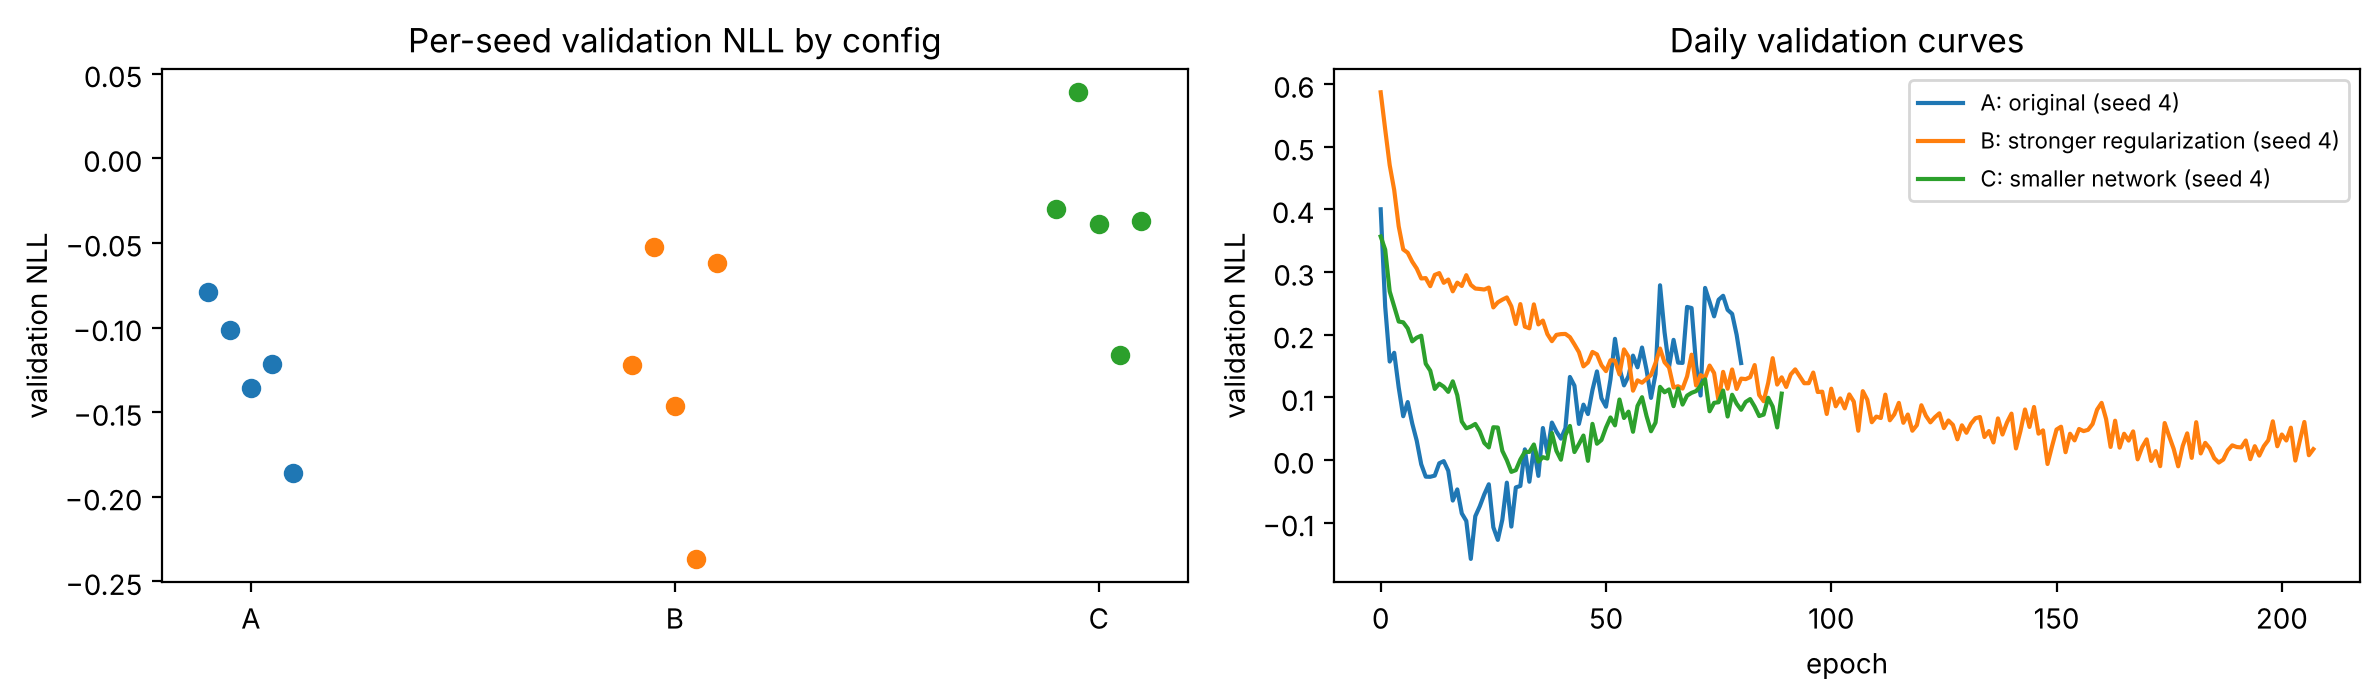

RESULT: selected B: stronger regularization; test NLL -0.143, Brier 0.0636 vs Stage 1 (3 seeds, moment-matched) NLL -0.122, Brier 0.0629; per-seed val NLL sd: A 0.036, B 0.067, C 0.049


In [17]:
D_CONFIGS = {
    "A: original":                 dict(units=(16,), dense=8, dropout=0.3, l2=1e-3, lr=3e-3, patience=60),
    "B: stronger regularization":  dict(units=(16,), dense=8, dropout=0.4, l2=1e-2, lr=1e-3, patience=30),
    "C: smaller network":          dict(units=(8,), dense=4, dropout=0.3, l2=1e-3, lr=3e-3, patience=60),
}
N_SEEDS = 5
d_runs = {}
for name, cfg in D_CONFIGS.items():
    runs = []
    for s in range(N_SEEDS):
        if name.startswith("A") and s < len(ds["runs"][7]["t"]):
            runs.append(ds["runs"][7]["t"][s])           # identical settings: reuse the Stage 1 run
        else:
            runs.append(run_daily_cfg(dly, seed=s, **cfg))
    d_runs[name] = runs
    print(f"{name}: {N_SEEDS} seeds ready")

rows = []
for name, runs in d_runs.items():
    va_nll = []
    for r in runs:
        va = r["masks"][1]
        va_nll.append(E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"])
    best_ep = [int(np.argmin(r["hist"]["val_loss"])) + 1 for r in runs]
    row = {"config": name, "val NLL per seed (mean)": np.mean(va_nll), "val NLL per seed (sd)": np.std(va_nll),
           "best epoch (median)": np.median(best_ep), "best epochs": best_ep}
    for lab, rg in DRNG.items():
        for k_ in (3, N_SEEDS):
            comps = comps_on(runs[:k_], rg); idx = comps[0].index; y = dly["y"].loc[idx].values * 100
            mm = mix_metrics(y, comps)
            row[f"{lab} NLL ({k_}-seed mixture)"] = mm["NLL"]
            if k_ == N_SEEDS:
                row[f"{lab} CRPS"] = mm["CRPS"]
                cm = E.contract_metrics(price_ladder_mix(dcon[dcon.date.isin(idx)], comps))
                row[f"{lab} Brier"], row[f"{lab} accuracy"] = cm["brier"], cm["accuracy"]
    rows.append(row)
d_tab = pd.DataFrame(rows).set_index("config")
display(d_tab.round(4))

chosen = d_tab[f"val NLL ({N_SEEDS}-seed mixture)"].idxmin()
print(f"Selected on validation NLL ({N_SEEDS}-seed mixture): {chosen}")
REV["r5_daily_configs"], REV["r5_chosen"] = d_tab, chosen

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (name, runs) in enumerate(d_runs.items()):
    va_nll = [E.dist_metrics(r["y"][r["masks"][1]] * 100, r["dist"][r["masks"][1]])["NLL"] for r in runs]
    ax[0].scatter(np.full(len(va_nll), i) + np.linspace(-0.1, 0.1, len(va_nll)), va_nll)
    h = runs[-1]["hist"]; ax[1].plot(h["val_loss"], label=f"{name} (seed {N_SEEDS - 1})")
ax[0].set_xticks(range(len(d_runs))); ax[0].set_xticklabels([n.split(":")[0] for n in d_runs]); ax[0].set_ylabel("validation NLL")
ax[0].set_title("Per-seed validation NLL by config")
ax[1].set_xlabel("epoch"); ax[1].set_ylabel("validation NLL"); ax[1].set_title("Daily validation curves"); ax[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

stage1 = ds["table"].set_index(["split", "model"]).loc[("test", "GARCH-LSTM-t lb7 (x3)")]
print(f"RESULT: selected {chosen}; test NLL {d_tab.loc[chosen, 'test NLL (5-seed mixture)']:.3f}, Brier "
      f"{d_tab.loc[chosen, 'test Brier']:.4f} vs Stage 1 (3 seeds, moment-matched) NLL {stage1['NLL']:.3f}, Brier {stage1['brier']:.4f}; "
      f"per-seed val NLL sd: " + ", ".join(f"{n.split(':')[0]} {d_tab.loc[n, 'val NLL per seed (sd)']:.3f}" for n in d_tab.index))

### Revision log (for the contribution table)

| Date | Owner | What |
|---|---|---|
| 2026-10-23 | Wenjun Chen | Revision 1: validation-fitted and rolling scale calibration; coverage at 50/80/90/95% |
| 2026-10-23 | Wenjun Chen | Revision 2: ECM-GARCH-t baseline (weekly and daily) |
| 2026-10-23 | Wenjun Chen | Revision 3: exact seed-mixture scoring vs moment matching |
| 2026-10-23 | Wenjun Chen | Revision 4: Diebold–Mariano tests with Holm correction |
| 2026-10-23 | Wenjun Chen | Revision 5: daily model with 5 seeds and three regularization configurations |
| 2026-11-04 | Wenjun Chen | Data update: AAA daily series extended to Jun 2015 – Nov 2026 from Wayback snapshots of gasprices.aaa.com (367 → 3,865 days); daily test window fixed at Aug 20 – Oct 19 2026; notebook rerun and daily readings in Stage 1 and Revisions 2–5 rewritten |

#### ▶ What the next cell does: save the revision tables

Saves the tables collected in `REV` to `results/part2_revisions.pkl`. Parts 3 and 4 do not read this file; it is only a record of the revision results.

**Output:** the saved file path.

In [18]:
H.save("part2_revisions", {k: v for k, v in REV.items()})   # revision tables only; Parts 3-4 do not read this file

saved results/part2_revisions.pkl for the next part (data fingerprint b2dc33c005be)


#### ▶ What the next cell does: hand the Stage 1 results to Parts 3 and 4

Saves the weekly feature frame (`w`) and all Stage 1 forecast distributions (`res`) to `results/part2.pkl`, together with the data fingerprint. Part 3 and Part 4 load this file instead of rebuilding Part 2. This cell is unchanged from the original notebook; the revisions do not alter what is handed on.

**Output:** the saved file path.

In [19]:
H.save("part2", {"w": s1["w"], "res": s1["res"]})  # hands the results to Parts 3 and 4

saved results/part2.pkl for the next part (data fingerprint b2dc33c005be)


## 4. Optimization experiments (Stage 2)

Each experiment changes **one** setting of the weekly GARCH-LSTM-t and keeps everything else at the baseline
configuration (lookback 8, units 32/16, dropout 0.2, L2 1e-4, AdamW lr 1e-3, batch 32, same splits, same three seeds).
Outcome: validation NLL, the mean and standard deviation over the three single-seed models (Section 3 tables score the
three-seed ensemble, which is why the baseline value there, 1.697, is lower than the 1.704 single-seed mean here).
The test set is not used for these choices.

**Why these two.** Experiment 1 (dropout 0, 0.2, 0.4) tests regularization, because the weekly training set is small (about 360 rows) and the diagnostics in Section 3 show overfitting risk. Experiment 2 (learning rate 3e-4, 1e-3, 3e-3) tests optimization speed and stability, because AdamW with early stopping can stop at different minima depending on step size.

,experiment,setting,val_NLL_mean,val_NLL_sd,epochs_mean
0,E1 dropout,0.0000,1.7065,0.0005,53.6667
1,E1 dropout,0.2000,1.7042,0.0082,70.3333
2,E1 dropout,0.4000,1.6977,0.0109,91.6667
3,E2 learning rate,0.0003,1.7135,0.0076,106.0000
4,E2 learning rate,0.0010,1.7042,0.0082,70.3333
5,E2 learning rate,0.0030,1.6945,0.0102,54.0000


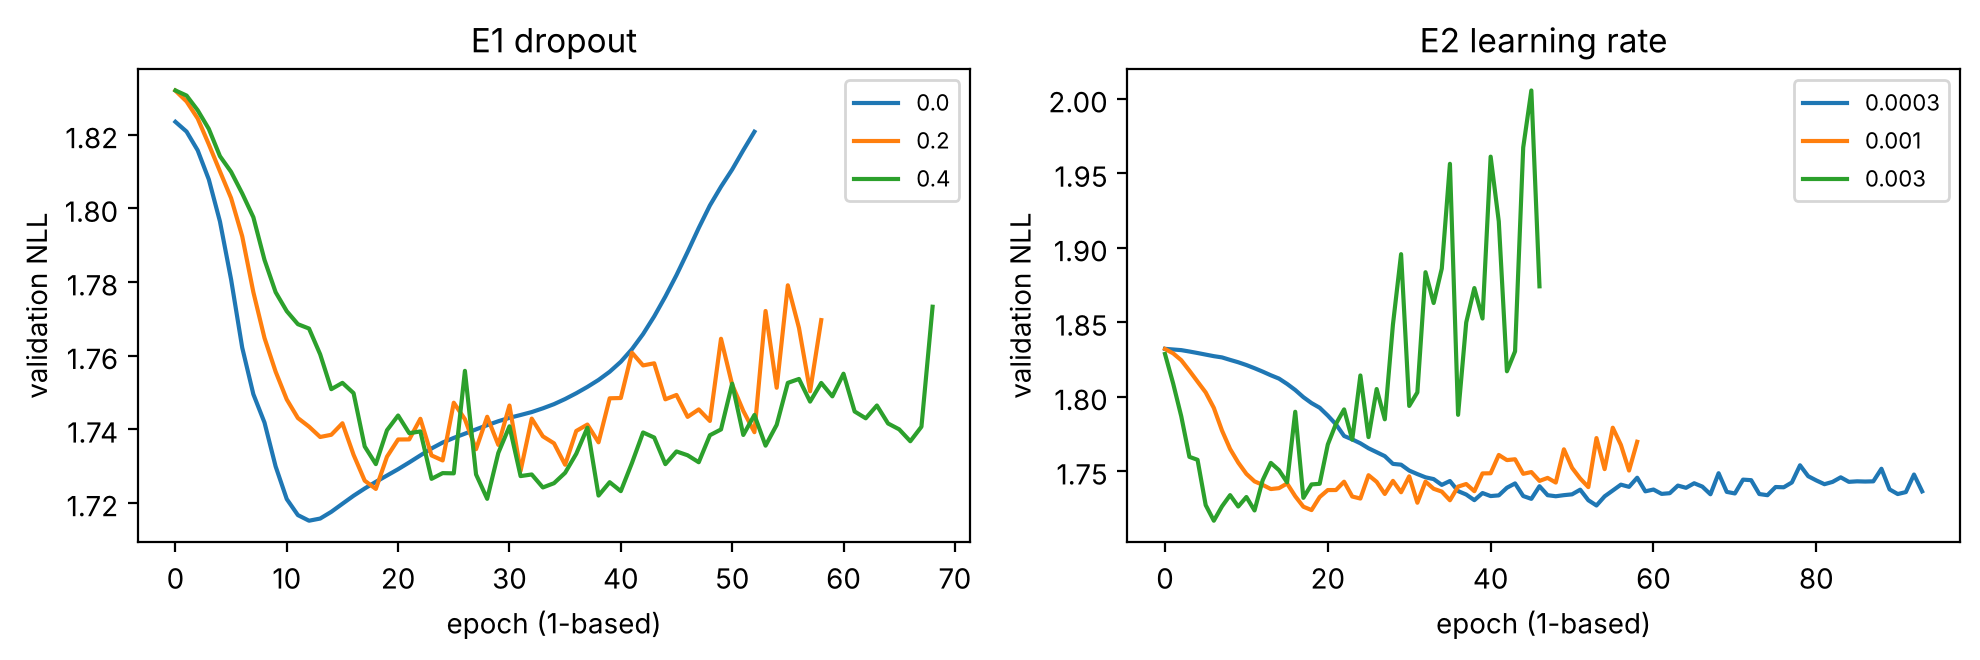

In [20]:
s2, curves = X.stage2_experiments(s1["w"])
display(s2.round(4))
X.plot_stage2(curves); plt.show()

**Reading.** Experiments 1 (dropout) and 2 (learning rate) each change one setting with all else fixed. Best-epoch validation NLL barely moves: dropout 0.4 gives 1.698 against 1.704 at 0.2 and 1.707 at 0, and learning rate 3e-3 gives 1.695 against 1.704 at 1e-3. These gains are about the size of the seed standard deviation (0.0005 to 0.011). The curves show what the table hides. With no dropout, validation NLL reaches its minimum around epoch 12 and then climbs steeply toward 1.82, while dropout 0.2 and 0.4 flatten out near 1.74 to 1.75; dropout mainly protects against overfitting after the minimum. Learning rate 3e-3 reaches its minimum fastest but becomes unstable afterwards (validation NLL spikes toward 2.0), and 3e-4 is slow (106 epochs on average). The learning-rate gain is therefore real but fragile and depends on early stopping.

### 4.1 Using the findings: combined configuration

The best single-factor settings are added one at a time, and a change is kept only if mean validation NLL improves.
The selected configuration becomes the weekly model whose forecast feeds the daily model.

In [21]:
wcfg, tune_tab, tuned_runs = X.weekly_tuned(s1["w"], s2)
display(tune_tab.round(4)); print("Selected weekly configuration:", wcfg)
json.dump(wcfg, open("results/weekly_cfg.json", "w"))
tuned = P.ensemble(tuned_runs)
tt = X._rows({"GARCH-LSTM-t baseline cfg (x3)": s1["res"]["GARCH-LSTM-t (x3)"], "GARCH-LSTM-t tuned cfg (x3)": tuned}, s1["w"]["y"], {"val": X.WVA, "test": X.WTE})
display(tt.set_index(["split", "model"]).sort_index()[["NLL", "CRPS", "MAE", "dir_acc", "cov80"]])

,step,config,val_NLL_mean,val_NLL_sd,kept
0,"baseline (lb 8, lr 1e-3, dropout 0.2)",{},1.7042,0.0082,True
1,+ lr 0.003,{'lr': 0.003},1.6945,0.0102,True
2,+ dropout 0.4,"{'lr': 0.003, 'dropout': 0.4}",1.6848,0.0127,True


Selected weekly configuration: {'lr': 0.003, 'dropout': 0.4}


NLL    CRPS     MAE  dir_acc   cov80
split model                                                                  
test  GARCH-LSTM-t baseline cfg (x3)  2.0315  1.0887  1.4592   0.6196  0.7283
      GARCH-LSTM-t tuned cfg (x3)     2.0051  1.0779  1.4509   0.6413  0.7391
val   GARCH-LSTM-t baseline cfg (x3)  1.6972  0.7232  1.0008   0.6762  0.8190
      GARCH-LSTM-t tuned cfg (x3)     1.6800  0.7169  0.9910   0.7143  0.8286

**Reading.** Adding the two changes one at a time kept both (mean single-seed validation NLL 1.704 to 1.695 to 1.685). On the test set the tuned three-seed ensemble improves NLL (2.032 to 2.005), CRPS (1.089 to 1.078), direction accuracy (0.620 to 0.641) and 80% coverage (0.728 to 0.739). Each gain is small, about one seed standard deviation, but all point the same way, so we keep the tuned configuration as the weekly input to the daily model.

In [22]:
H.save("part3", {"tuned": tuned, "wcfg": wcfg})  # hands the tuned forecast to Part 4

saved results/part3.pkl for the next part (data fingerprint b2dc33c005be)


## 4.2 Revisions to the optimization experiments

This section analyzes five revisions to the Stage 2 optimization experiments. Each revision has a code cell and a Markdown cell titled **Revision** (what I changed, why, and the result). None of the revisions changes the saved weekly configuration (`results/weekly_cfg.json`) or the Part 4 hand-off.

**Revision log (for the contribution table)**

| Date | What I did | Result |
|---|---|---|
| by 2026-11-02 | Added the revision helpers (cached single-seed runs, one-factor function) | Shared settings are trained only once |
| by 2026-11-02 | Revision 1: re-ran E1 and E2 with 5 seeds | Dropout 0.4 (1.7006) and lr 3e-3 (1.6967) still lowest; each beats the baseline in 5 of 5 seeds |
| by 2026-11-02 | Revision 2: wider and finer grid for dropout and learning rate | Dropout is flat from 0.3 to 0.5; lr 5e-3 is lower (1.6853) but at the edge of the range |
| by 2026-11-02 | Revision 3: new experiment E3 on L2 strength | L2 has no effect (1.7041 / 1.7042 / 1.7050) |
| by 2026-11-02 | Revision 4: lr × dropout interaction (2×2 from existing results, then 3×3) | lr and dropout gains roughly add; lowest cell (lr 5e-3, dropout 0.5, 1.6803) not adopted (corner, sd 0.0150) |
| by 2026-11-02 | Revision 5: training and validation curves with best epoch marked | No dropout overfits (val NLL +0.106 after the best epoch); lr 3e-3 peaks at epoch 7 then rises 0.158 |
| by 2026-11-02 | Revision 6: learning-rate schedule and dropout 0.5 vs the selected setting (5 seeds) | LR schedule leaves the final model unchanged but cuts the post-minimum rise (0.2294 to 0.0787); dropout 0.5 is about equal to 0.4 |

In [23]:
# Revision helpers. Each (configuration, seed) pair is trained once and cached,
# so settings shared by several revisions are not retrained.
BASE = dict(lookback=8, dropout=0.2, l2=1e-4, lr=1e-3)   # baseline weekly configuration
_cache = {}

def run_cfg(seed, **change):
    cfg = {**BASE, **change}
    key = (seed,) + tuple(sorted(cfg.items()))
    if key not in _cache:
        r = P.run_weekly(s1["w"], head="t", seed=seed, **cfg)
        va = r["masks"][1]
        _cache[key] = {"nll": E.dist_metrics(r["y"][va] * 100, r["dist"][va])["NLL"],
                       "epochs": len(r["hist"]["loss"])}
    return _cache[key]

def one_factor(param, values, seeds=range(3), **fixed):
    """Change one setting, keep everything else at BASE (or `fixed`), report val NLL over seeds."""
    rows = []
    for v in values:
        res = [run_cfg(s, **fixed, **{param: v}) for s in seeds]
        nll = [x["nll"] for x in res]
        rows.append({"param": param, "value": v, **fixed,
                     "val_NLL_mean": np.mean(nll), "val_NLL_sd": np.std(nll),
                     "epochs_mean": np.mean([x["epochs"] for x in res]),
                     **{f"seed{s}": n for s, n in zip(seeds, nll)}})
    return pd.DataFrame(rows)

In [24]:
# Revision 1: E1 and E2 with 5 seeds instead of 3
r1_drop = one_factor("dropout", [0.0, 0.2, 0.4], seeds=range(5))
r1_lr = one_factor("lr", [3e-4, 1e-3, 3e-3], seeds=range(5))
display(r1_drop.round(4)); display(r1_lr.round(4))

# Paired check: same seed, compare each setting with the baseline (dropout 0.2, lr 1e-3)
cols = [f"seed{s}" for s in range(5)]
base = r1_drop.loc[r1_drop["value"] == 0.2, cols].values[0].astype(float)
for name, tab in [("dropout", r1_drop), ("lr", r1_lr)]:
    for _, row in tab.iterrows():
        wins = int((row[cols].values.astype(float) < base).sum())
        print(f"{name} {row['value']:g}: lower val NLL than the baseline in {wins} of 5 seeds")

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2,seed3,seed4
0,dropout,0.0,1.7130,0.0098,53.4,1.7071,1.7064,1.7059,1.7137,1.7317
1,dropout,0.2,1.7062,0.0073,65.6,1.7157,1.7004,1.6967,1.7135,1.7050
2,dropout,0.4,1.7006,0.0092,86.4,1.7130,1.6891,1.6909,1.7060,1.7038


,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2,seed3,seed4
0,lr,0.0003,1.7152,0.0068,99.2,1.7189,1.7028,1.7189,1.7133,1.7218
1,lr,0.0010,1.7062,0.0073,65.6,1.7157,1.7004,1.6967,1.7135,1.7050
2,lr,0.0030,1.6967,0.0084,51.8,1.7086,1.6845,1.6904,1.7008,1.6992


dropout 0: lower val NLL than the baseline in 1 of 5 seeds
dropout 0.2: lower val NLL than the baseline in 0 of 5 seeds
dropout 0.4: lower val NLL than the baseline in 5 of 5 seeds
lr 0.0003: lower val NLL than the baseline in 1 of 5 seeds
lr 0.001: lower val NLL than the baseline in 0 of 5 seeds
lr 0.003: lower val NLL than the baseline in 5 of 5 seeds


### Revision 1: More seeds

**What I changed.** I re-ran Experiment 1 (dropout 0, 0.2, 0.4) and Experiment 2 (learning rate 3e-4, 1e-3, 3e-3) with 5 seeds instead of 3. I also compared each setting with the baseline seed by seed.

**Why.** With 3 seeds, the gains were about the same size as the seed standard deviation. For example, dropout 0.4 was 0.0065 lower than dropout 0.2, but the seed sd was 0.0082 to 0.0109. So we could not tell if the gains were real or just random variation.

**Result.** With 5 seeds, the ranking did not change. Dropout 0.4 has the lowest mean val NLL at 1.7006, compared with 1.7062 at dropout 0.2 and 1.7130 at dropout 0. Learning rate 3e-3 has the lowest at 1.6967, compared with 1.7062 at 1e-3 and 1.7152 at 3e-4. The gaps are still small. Dropout 0.4 is 0.0056 below the baseline, which is smaller than the seed sd (0.0073 to 0.0092). Learning rate 3e-3 is 0.0095 below, about the same as its sd (0.0084).

The paired check is much clearer. Dropout 0.4 and learning rate 3e-3 each beat the baseline in 5 of 5 seeds. Dropout 0 and learning rate 3e-4 beat it in only 1 of 5. Much of the seed sd comes from the seed itself and affects all settings in the same way, so comparing seed by seed removes it. Both gains are small, but they are consistent. The first three seeds give the same values as the original run, so the results are reproducible.

In [25]:
# Revision 2: wider and finer grid (3 seeds, other settings at the baseline)
r2_drop = one_factor("dropout", [0.3, 0.4, 0.5])
r2_lr = one_factor("lr", [2e-3, 3e-3, 5e-3])
display(r2_drop.round(4)); display(r2_lr.round(4))

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,dropout,0.3,1.6991,0.0071,85.3333,1.7090,1.6926,1.6958
1,dropout,0.4,1.6977,0.0109,91.6667,1.7130,1.6891,1.6909
2,dropout,0.5,1.6978,0.0132,106.0000,1.7135,1.6812,1.6988


,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,lr,0.002,1.6948,0.0126,59.0000,1.7125,1.6840,1.6878
1,lr,0.003,1.6945,0.0102,54.0000,1.7086,1.6845,1.6904
2,lr,0.005,1.6853,0.0093,50.3333,1.6979,1.6760,1.6819


### Revision 2: Wider and finer grid

**What I changed.** I tested dropout 0.3, 0.4 and 0.5, and learning rate 2e-3, 3e-3 and 5e-3. All other settings stayed at the baseline.

**Why.** In the original experiments, the best values (dropout 0.4 and learning rate 3e-3) were the largest values tested. A better value could be outside the tested range or between two tested values. Dropout 0.4 and learning rate 3e-3 are included again as a check: with the same seeds, they should give the original 1.6977 and 1.6945.

**Result.** Dropout 0.4 and learning rate 3e-3 gave the original values again (1.6977 and 1.6945), so the runs are reproducible.

For dropout, the results are flat. Dropout 0.3 gives 1.6991, 0.4 gives 1.6977, and 0.5 gives 1.6978. The largest difference is 0.0014, which is much smaller than the seed sd (0.0071 to 0.0132). The sd grows with dropout, from 0.0071 at 0.3 to 0.0132 at 0.5, and training takes longer (85 to 106 epochs). So dropout above 0.3 gives no extra gain, and 0.4 is still a reasonable choice.

For learning rate, 2e-3 (1.6948) and 3e-3 (1.6945) are almost the same. Learning rate 5e-3 is lower at 1.6853. It beats 3e-3 in all 3 seeds, its sd (0.0093) is not larger, and it stops earliest (50 epochs). The best learning rate is again at the edge of the range. Revision 4 tests whether this gain still holds when combined with dropout 0.4.

In [26]:
# Revision 3: new experiment E3, L2 strength (3 seeds, other settings at the baseline)
r3 = one_factor("l2", [0.0, 1e-4, 1e-3])
display(r3.round(4))

,param,value,val_NLL_mean,val_NLL_sd,epochs_mean,seed0,seed1,seed2
0,l2,0.0000,1.7041,0.0089,70.3333,1.7164,1.7004,1.6955
1,l2,0.0001,1.7042,0.0082,70.3333,1.7157,1.7004,1.6967
2,l2,0.0010,1.7050,0.0065,92.3333,1.7140,1.6989,1.7023


### Revision 3: New experiment E3 (L2 regularization)

**What I changed.** I added a third controlled experiment that tests L2 strength 0, 1e-4 (baseline) and 1e-3. All other settings stayed at the baseline.

**Why.** The weekly model has about 8,700 parameters but only about 360 training rows, so it can overfit. Experiment 1 showed that stronger dropout helped, so stronger L2 might help too. The original experiments never tested L2. The val NLL here is computed from the predictions and does not include the L2 penalty, so the three settings can be compared fairly.

**Result.** L2 has almost no effect. Mean val NLL is 1.7041 with no L2, 1.7042 at 1e-4 and 1.7050 at 1e-3. The largest difference is 0.0009, which is much smaller than the seed sd (0.0065 to 0.0089). The single-seed values for no L2 and 1e-4 are almost the same, for example 1.7164 and 1.7157 for seed 0. L2 1e-3 trains longer (92 epochs vs. 70) and has a slightly lower sd (0.0065), but it does not improve the mean. A likely reason is that dropout and the AdamW weight decay (1e-4) already regularize the weights. We keep the baseline L2 of 1e-4.

In [27]:
# Revision 4: learning rate x dropout grid (3 seeds)
lrs, drops = [1e-3, 3e-3, 5e-3], [0.2, 0.4, 0.5]
r4 = pd.concat([one_factor("dropout", drops, lr=lr) for lr in lrs], ignore_index=True)
m = r4.pivot(index="lr", columns="value", values="val_NLL_mean")
sd = r4.pivot(index="lr", columns="value", values="val_NLL_sd")
print("Mean val NLL (rows = lr, columns = dropout)")
print(m.round(4).to_string())
print("\nSeed sd of val NLL")
print(sd.round(4).to_string())
print("\nChange in val NLL from dropout 0.2 to 0.4 at each lr:", (m[0.4] - m[0.2]).round(4).to_dict())

Mean val NLL (rows = lr, columns = dropout)
value     0.2     0.4     0.5
lr                           
0.001  1.7042  1.6977  1.6978
0.003  1.6945  1.6848  1.6847
0.005  1.6853  1.6866  1.6803

Seed sd of val NLL
value     0.2     0.4     0.5
lr                           
0.001  0.0082  0.0109  0.0132
0.003  0.0102  0.0127  0.0071
0.005  0.0093  0.0138  0.0150

Change in val NLL from dropout 0.2 to 0.4 at each lr: {0.001: -0.0066, 0.003: -0.0097, 0.005: 0.0013}


### Revision 4: Interaction between learning rate and dropout

**What I changed.** I arranged the existing results as a 2×2 table of learning rate (1e-3, 3e-3) and dropout (0.2, 0.4). Then I extended it to a 3×3 grid with learning rate 5e-3 and dropout 0.5.

**Why.** Section 4.1 added the two changes one at a time in a fixed order. This assumes that the effect of dropout does not depend on the learning rate, but this was never checked.

**Result.** The 2×2 table uses numbers already in Sections 4 and 4.1.

| | dropout 0.2 | dropout 0.4 | change from dropout |
|---|---|---|---|
| lr 1e-3 | 1.7042 | 1.6977 | −0.0065 |
| lr 3e-3 | 1.6945 | 1.6848 | −0.0097 |

At lr 1e-3 and 3e-3, dropout 0.4 lowers val NLL by a similar amount. The difference is 0.0032, which is smaller than the seed sd of about 0.01. So the two gains add up roughly.

The 3×3 grid gives the following mean val NLL (seed sd in brackets).

| lr \ dropout | 0.2 | 0.4 | 0.5 |
|---|---|---|---|
| 1e-3 | 1.7042 (0.0082) | 1.6977 (0.0109) | 1.6978 (0.0132) |
| 3e-3 | 1.6945 (0.0102) | 1.6848 (0.0127) | 1.6847 (0.0071) |
| 5e-3 | 1.6853 (0.0093) | 1.6866 (0.0138) | 1.6803 (0.0150) |

At lr 1e-3 and 3e-3, dropout 0.4 and 0.5 give almost the same result (1.6977 vs. 1.6978, and 1.6848 vs. 1.6847). At lr 5e-3, the pattern is not smooth. Dropout 0.4 is slightly worse than 0.2 (1.6866 vs. 1.6853), but dropout 0.5 is the lowest in the grid at 1.6803. Because the values go up and then down, the differences at lr 5e-3 are most likely random variation, not a real interaction. The seed sd also grows with dropout at lr 5e-3, from 0.0093 at 0.2 to 0.0138 at 0.4 and 0.0150 at 0.5, so training becomes less stable.

The lowest mean is lr 5e-3 with dropout 0.5 (1.6803). It is only 0.0045 below the selected setting, lr 3e-3 with dropout 0.4 (1.6848), and this gap is much smaller than its sd of 0.0150. It is also at the corner of the grid and is the least stable setting. So we keep the original configuration. Learning rate 3e-3 with dropout 0.5 is a good alternative. It has the same mean (1.6847) and the lowest sd in the grid (0.0071).

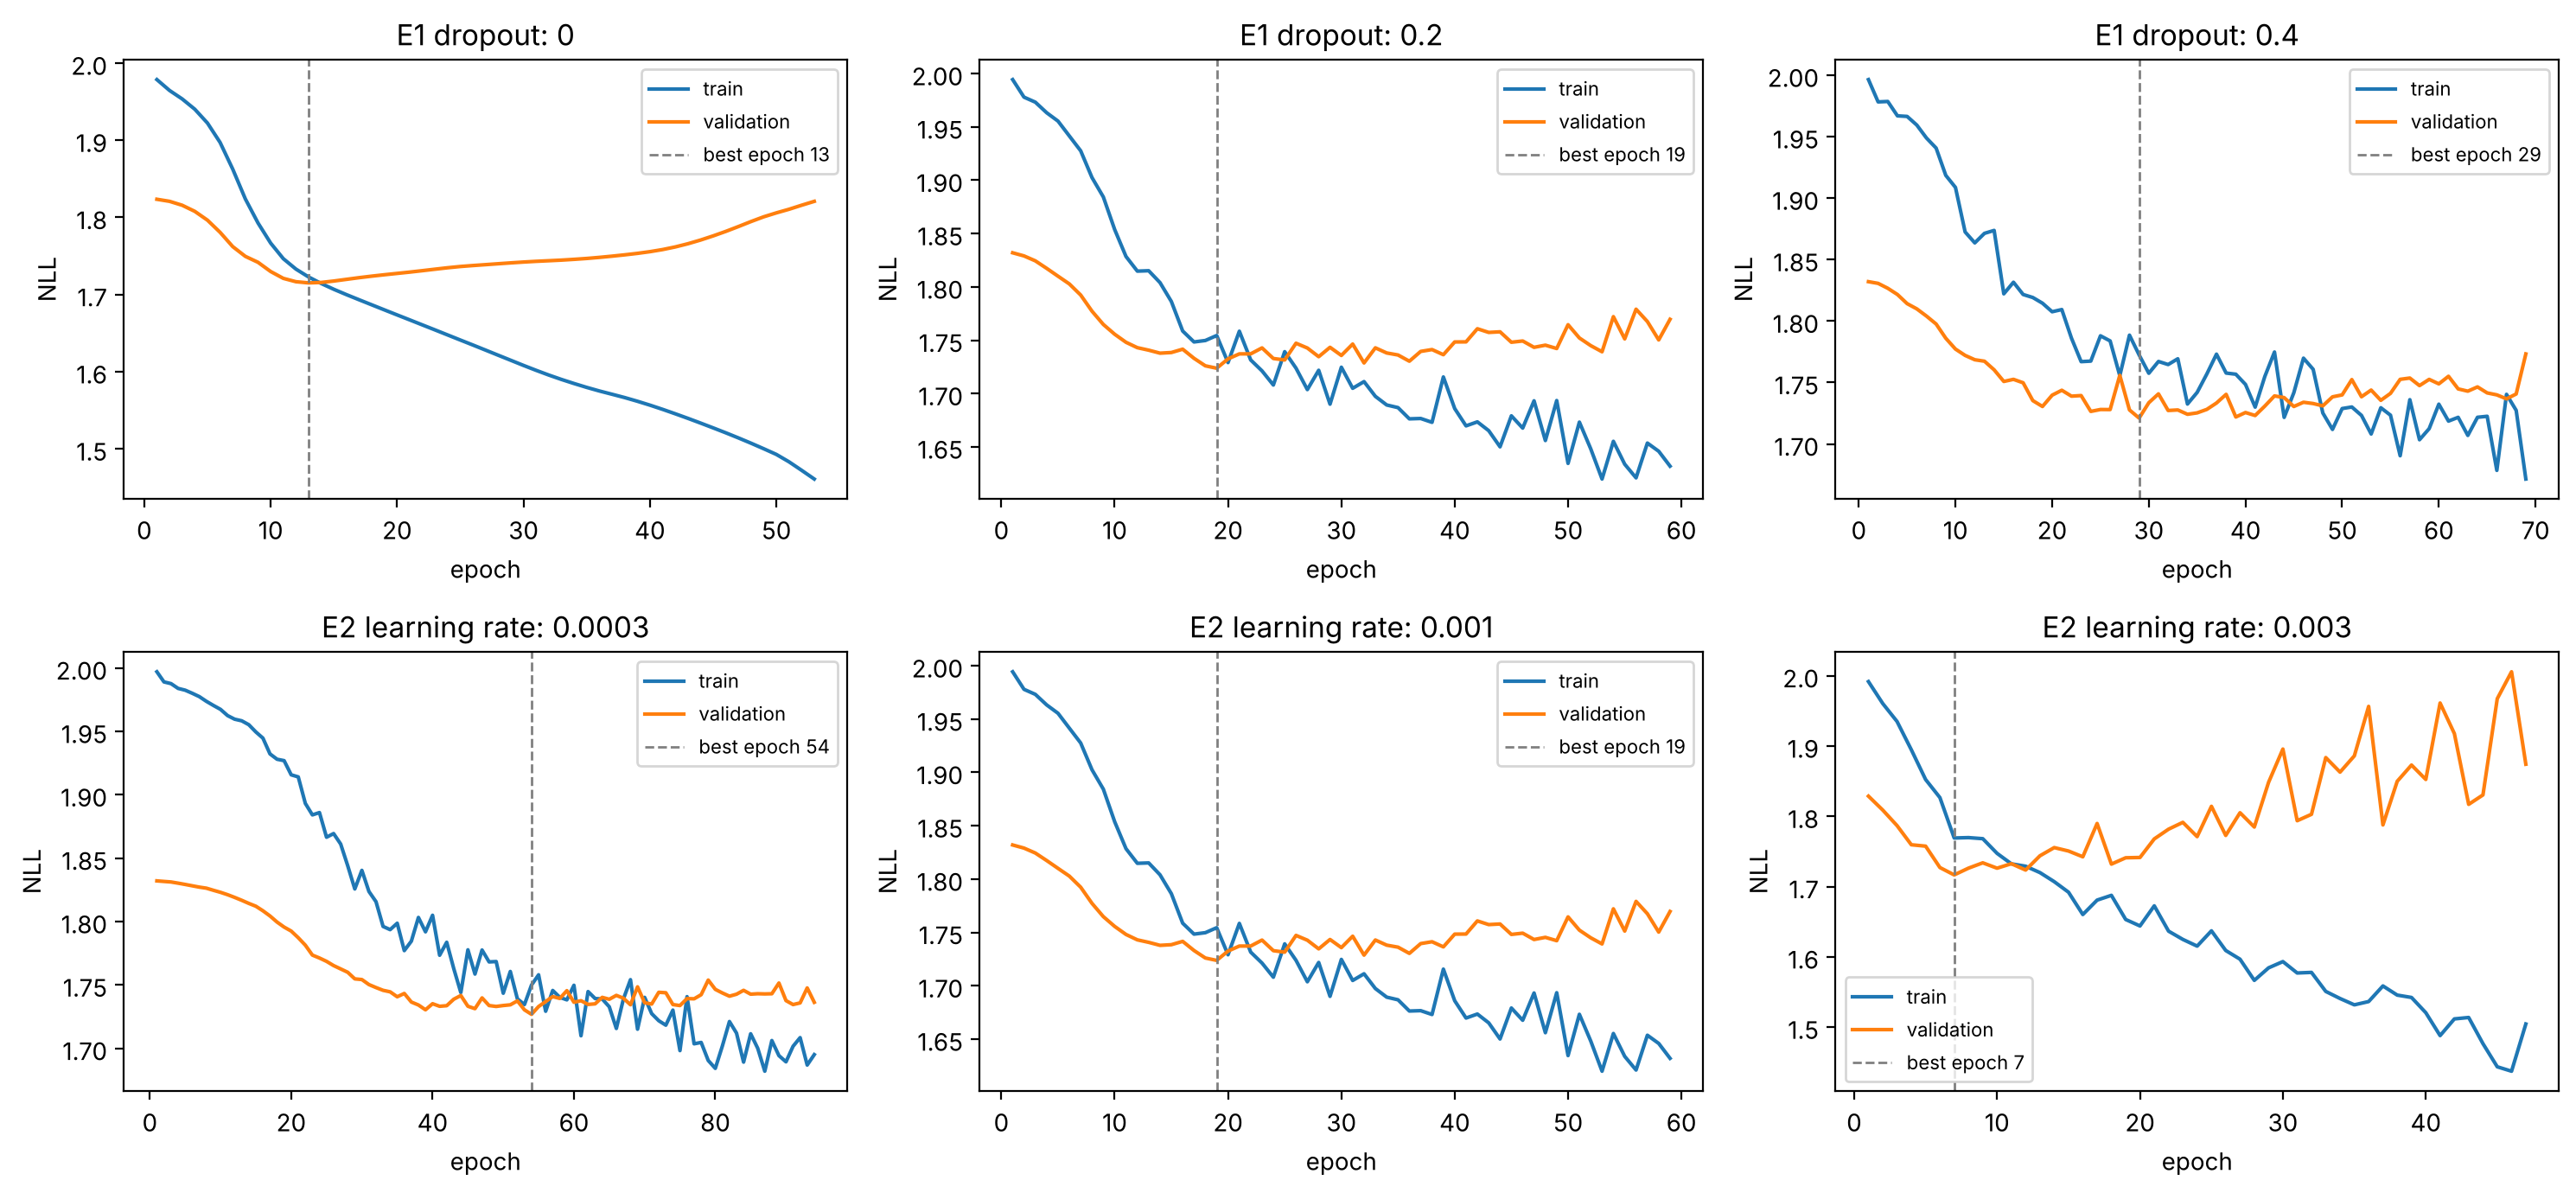

,experiment,setting,best_epoch,train_NLL_at_best,val_NLL_at_best,val_NLL_last,val_rise_after_best
0,E1 dropout,0.0000,13,1.7228,1.7151,1.8208,0.1057
1,E1 dropout,0.2000,19,1.7544,1.7238,1.7696,0.0459
2,E1 dropout,0.4000,29,1.7724,1.7211,1.7733,0.0522
3,E2 learning rate,0.0003,54,1.7499,1.7268,1.7363,0.0095
4,E2 learning rate,0.0010,19,1.7544,1.7238,1.7696,0.0459
5,E2 learning rate,0.0030,7,1.7691,1.7166,1.8741,0.1575


In [28]:
# Revision 5: training and validation NLL for every E1 and E2 setting (seed 0), best epoch marked
settings = [("E1 dropout", [0.0, 0.2, 0.4]), ("E2 learning rate", [3e-4, 1e-3, 3e-3])]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for row, (exp, vals) in zip(axes, settings):
    for a, v in zip(row, vals):
        h = curves[(exp, v)]
        ep = np.arange(1, len(h["loss"]) + 1)
        best = int(np.argmin(h["val_loss"])) + 1
        a.plot(ep, h["loss"], label="train")
        a.plot(ep, h["val_loss"], label="validation")
        a.axvline(best, color="gray", ls="--", lw=1, label=f"best epoch {best}")
        a.set_title(f"{exp}: {v:g}"); a.set_xlabel("epoch"); a.set_ylabel("NLL"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

rows = []
for (exp, v), h in curves.items():
    i = int(np.argmin(h["val_loss"]))
    rows.append({"experiment": exp, "setting": v, "best_epoch": i + 1,
                 "train_NLL_at_best": h["loss"][i], "val_NLL_at_best": h["val_loss"][i],
                 "val_NLL_last": h["val_loss"][-1],
                 "val_rise_after_best": h["val_loss"][-1] - h["val_loss"][i]})
display(pd.DataFrame(rows).round(4))

### Revision 5: Training and validation curves

**What I changed.** I plotted training and validation NLL together for every setting in Experiments 1 and 2 and marked the best epoch. I also added a table with the NLL at the best epoch and how much validation NLL rose after it.

**Why.** The original figure showed only validation NLL. Without the training curve, we could not see whether validation NLL rose while training NLL kept falling, which is the sign of overfitting.

**Result.** Without dropout, the curves show clear overfitting. Training NLL keeps falling from about 1.98 to 1.46. Validation NLL reaches its minimum of 1.7151 at epoch 13 and then rises to 1.8208, an increase of 0.1057. With dropout 0.2 and 0.4, validation NLL stays roughly flat after the best epoch. It rises by only 0.0459 and 0.0522, about half as much. Dropout also moves the best epoch later, to epoch 19 and 29.

For learning rate, 3e-4 is slow but very stable. Its best epoch is 54, and validation NLL rises by only 0.0095 afterwards. Learning rate 3e-3 reaches its best epoch fastest, at epoch 7. After that, validation NLL rises with large spikes up to about 2.0, the largest rise at 0.1575. So the gain from lr 3e-3 depends on early stopping restoring the weights from epoch 7.

In all settings, training NLL starts higher than validation NLL (about 1.98 vs. 1.83). This also happens without dropout, so it likely comes from the different volatility in the two periods, not only from dropout.

sanity check (seed 0, lr 3e-3, dropout 0.4): new function 1.7013 vs revision helper 1.7013


                                       val_NLL_mean  val_NLL_sd  best_epoch_mean  val_rise_after_best_mean  seeds_better_than_A   seed0   seed1   seed2   seed3   seed4
config                                                                                                                                                                 
A: lr 3e-3, dropout 0.4 (selected)           1.6856      0.0099             20.8                    0.2294                    0  1.7013  1.6702  1.6830  1.6868  1.6869
B: lr 3e-3, dropout 0.5                      1.6864      0.0060             21.2                    0.1580                    1  1.6942  1.6769  1.6831  1.6906  1.6873
C: lr 3e-3, dropout 0.4 + LR schedule        1.6856      0.0099             20.8                    0.0787                    0  1.7013  1.6702  1.6830  1.6868  1.6869
D: lr 3e-3, dropout 0.5 + LR schedule        1.6864      0.0060             21.2                    0.0600                    1  1.6942  1.6769  1.6831  1.6906 

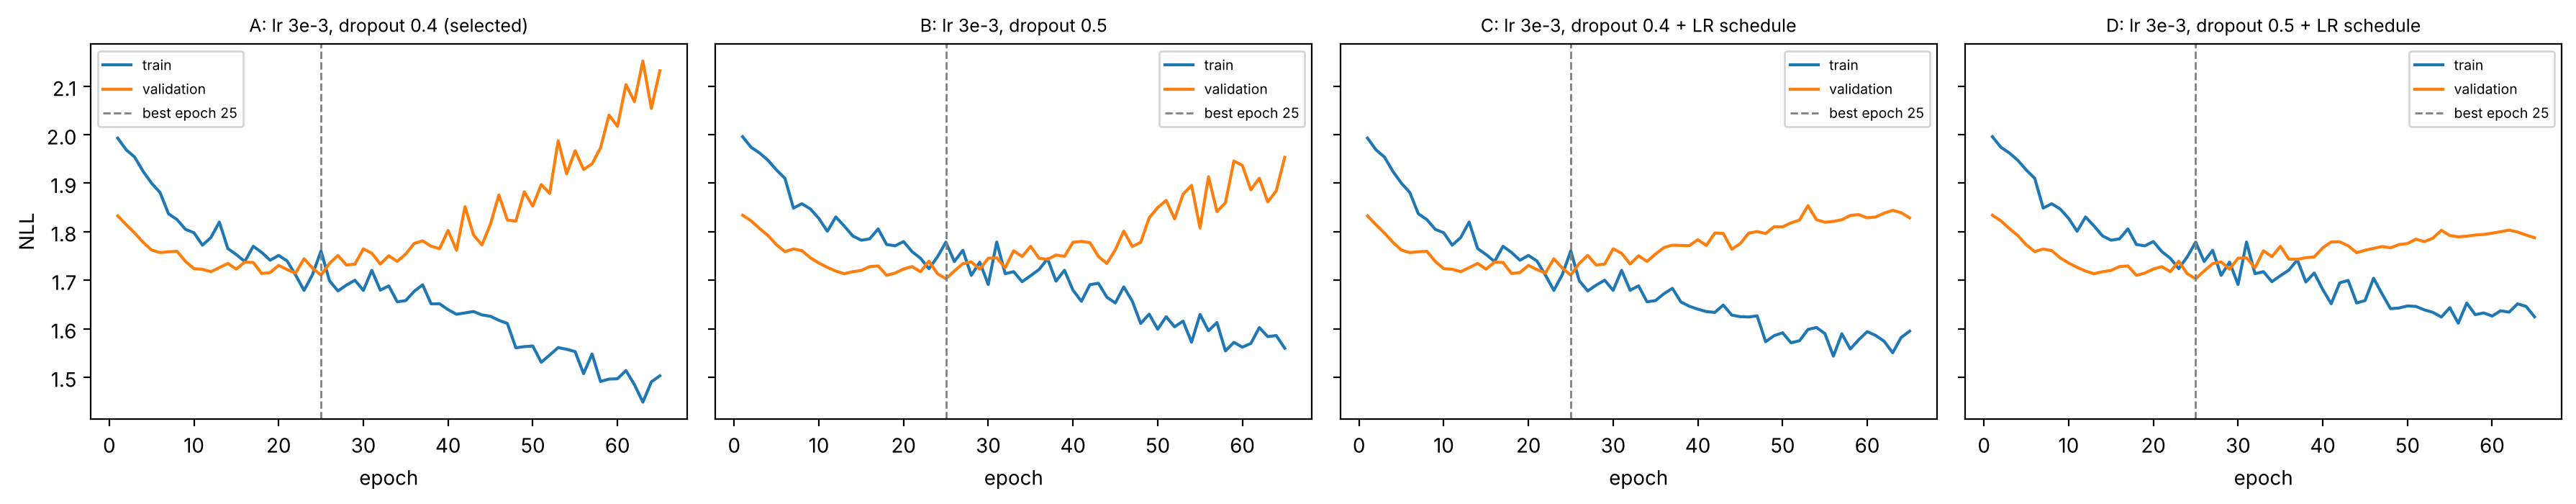

In [29]:
# Revision 6: lower validation NLL without overfitting after the best epoch.
# Same model, data, splits and early stopping as P.run_weekly, plus an optional learning-rate schedule:
# ReduceLROnPlateau halves the learning rate when validation NLL stops improving for 10 epochs.
from tensorflow import keras

def run_weekly_v2(seed=0, lr=3e-3, dropout=0.4, l2=1e-4, lookback=8, units=(32, 16),
                  schedule=False, factor=0.5, lr_patience=10, min_lr=1e-4, patience=40, epochs=400):
    w = s1["w"]; feats = D.WEEKLY_FEATS
    X, y, idx = D.sequences(w, feats, lookback)
    tr, va, te = P.split_masks(idx, P.W_SPLIT, P.W_SPLIT.get("train_start"))
    tr &= ~np.isnan(y); va &= ~np.isnan(y)
    sc = M.Scaler(keep_last_raw=True).fit(X[tr])
    m = M.build_lstm(X.shape[1], X.shape[2], head="t", seed=seed, units=units, dropout=dropout, l2=l2)
    m.compile(optimizer=keras.optimizers.AdamW(learning_rate=lr, weight_decay=1e-4, clipnorm=1.0), loss=M.nll_t)
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=patience, restore_best_weights=True)]
    if schedule:
        cb.append(keras.callbacks.ReduceLROnPlateau("val_loss", factor=factor, patience=lr_patience, min_lr=min_lr))
    h = m.fit(sc(X[tr]), y[tr][:, None] * 100, validation_data=(sc(X[va]), y[va][:, None] * 100),
              epochs=epochs, batch_size=32, callbacks=cb, verbose=0, shuffle=True).history
    d = M.predict_dist(m, sc(X), "t"); d.index = idx
    nll = E.dist_metrics(y[va] * 100, d[va])["NLL"]
    best = int(np.argmin(h["val_loss"]))
    return {"val_NLL": nll, "best_epoch": best + 1, "val_rise_after_best": h["val_loss"][-1] - h["val_loss"][best], "hist": h}

# Sanity check: without a schedule, this function must reproduce the cached result from the revision helpers
chk = run_weekly_v2(seed=0, lr=3e-3, dropout=0.4)["val_NLL"]
ref = run_cfg(0, lr=3e-3, dropout=0.4)["nll"]
print(f"sanity check (seed 0, lr 3e-3, dropout 0.4): new function {chk:.4f} vs revision helper {ref:.4f}")

R6 = {"A: lr 3e-3, dropout 0.4 (selected)":       dict(lr=3e-3, dropout=0.4),
      "B: lr 3e-3, dropout 0.5":                   dict(lr=3e-3, dropout=0.5),
      "C: lr 3e-3, dropout 0.4 + LR schedule":     dict(lr=3e-3, dropout=0.4, schedule=True),
      "D: lr 3e-3, dropout 0.5 + LR schedule":     dict(lr=3e-3, dropout=0.5, schedule=True)}
SEEDS6 = range(5)
r6_runs = {name: [run_weekly_v2(seed=s, **cfg) for s in SEEDS6] for name, cfg in R6.items()}

base = np.array([r["val_NLL"] for r in r6_runs["A: lr 3e-3, dropout 0.4 (selected)"]])
rows = []
for name, runs in r6_runs.items():
    nll = np.array([r["val_NLL"] for r in runs])
    rows.append({"config": name, "val_NLL_mean": nll.mean(), "val_NLL_sd": nll.std(),
                 "best_epoch_mean": np.mean([r["best_epoch"] for r in runs]),
                 "val_rise_after_best_mean": np.mean([r["val_rise_after_best"] for r in runs]),
                 "seeds_better_than_A": int((nll < base).sum()),
                 **{f"seed{s}": v for s, v in zip(SEEDS6, nll)}})
r6 = pd.DataFrame(rows).set_index("config")
print(r6.round(4).to_string())

fig, axes = plt.subplots(1, 4, figsize=(18, 3.6), sharey=True)
for a, (name, runs) in zip(axes, r6_runs.items()):
    h = runs[0]["hist"]; ep = np.arange(1, len(h["loss"]) + 1); b = int(np.argmin(h["val_loss"])) + 1
    a.plot(ep, h["loss"], label="train"); a.plot(ep, h["val_loss"], label="validation")
    a.axvline(b, color="gray", ls="--", lw=1, label=f"best epoch {b}")
    a.set_title(name.split(":")[0] + ":" + name.split(":")[1], fontsize=9); a.set_xlabel("epoch"); a.legend(fontsize=7)
axes[0].set_ylabel("NLL"); plt.tight_layout(); plt.show()


### Revision 6: Lower validation NLL without overfitting after the best epoch

**What I changed.** I compared four settings of the weekly GARCH-LSTM-t with 5 seeds. A is the selected setting (lr 3e-3, dropout 0.4). B uses dropout 0.5, which had the same mean and the lowest seed sd in Revision 4. C and D add a learning-rate schedule (ReduceLROnPlateau) to A and B. The schedule halves the learning rate when validation NLL has not improved for 10 epochs, down to 1e-4. Everything else is unchanged: same data, splits, early stopping (patience 40, best weights restored) and seeds. A sanity check confirms that the new training function reproduces the earlier result when no schedule is used.

**Why.** Revision 5 showed that lr 3e-3 reaches its best epoch fastest (epoch 7) but then overfits the most (validation NLL rose by 0.1575 after the best epoch). Its low validation NLL depends on early stopping catching the right epoch. A learning-rate schedule keeps the large steps at the start and takes smaller steps once progress stops, so validation NLL should stay near its minimum instead of rising. The selection rule was set before running: choose the lowest mean validation NLL; if two settings are within one seed sd of each other, prefer the one with the smaller rise after the best epoch.

**Result.** The sanity check passed. Without a schedule, the new function gives 1.7013 for seed 0, the same as the revision helper.

The learning-rate schedule did not change the final model. C has exactly the same validation NLL as A for every seed (mean 1.6856, sd 0.0099), and D is the same as B (mean 1.6864, sd 0.0060). The best epochs are also the same. The schedule lowers the learning rate only after validation NLL has not improved for 10 epochs. In every run this happened after the best epoch, and the lower learning rate never found a lower validation NLL. Early stopping then restored the same best-epoch weights.

The schedule did change what happens after the best epoch. Validation NLL rose by 0.2294 on average without the schedule (A) and by 0.0787 with it (C), about one third as much. With dropout 0.5, the rise fell from 0.1580 (B) to 0.0600 (D). So the schedule removes most of the overfitting after the minimum. Because early stopping already discards those epochs, the reported model does not change.

Dropout 0.5 and dropout 0.4 give almost the same validation NLL. B is 0.0008 higher than A, which is much smaller than the seed sd, and it beats A in only 1 of 5 seeds. B is more stable across seeds (sd 0.0060 vs. 0.0099) and overfits less after the best epoch (0.1580 vs. 0.2294).

Under the rule set before running, all four settings are within one seed sd, so the setting with the smallest rise wins. That is D (rise 0.0600). D gives the same final model as B, so in practice the choice is dropout 0.5 instead of 0.4. We therefore propose lr 3e-3 with dropout 0.5 for the next round. The Part 4 results in this notebook were produced with lr 3e-3 and dropout 0.4 (the saved `weekly_cfg.json`), so the change is not applied yet; it is a Stage 3 item and is expected to move validation NLL by less than 0.001. 

In [30]:
p3 = {"tuned": tuned, "wcfg": wcfg}   # hand-off from Section 4 (also saved to results/part3.pkl)
aaa = D.load_aaa_daily()

## 5. Generalization and diagnostic analysis

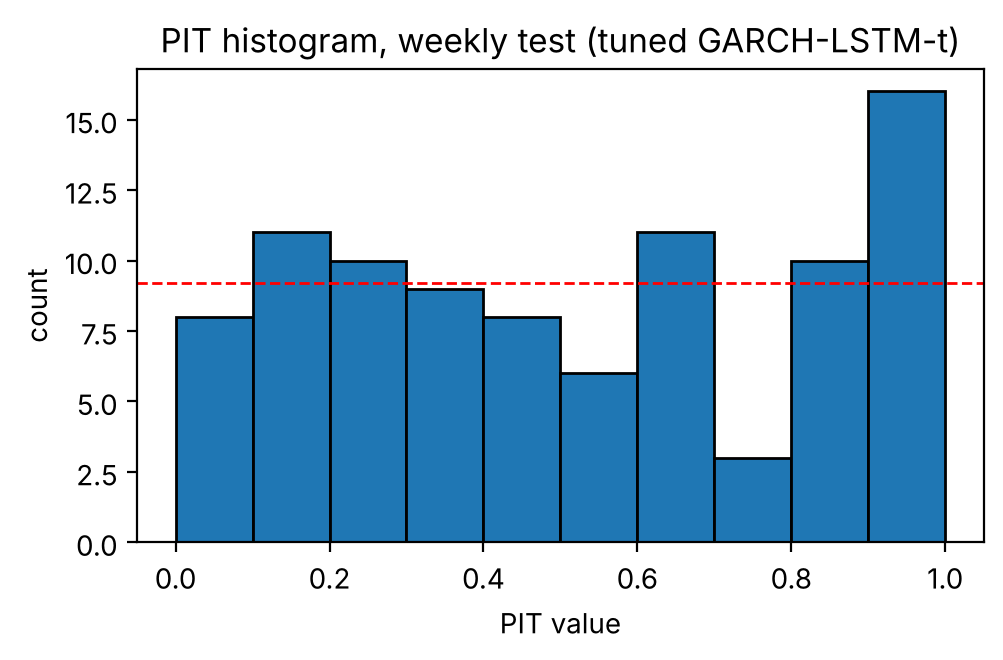

KS test of PIT uniformity: stat 0.097, p = 0.336


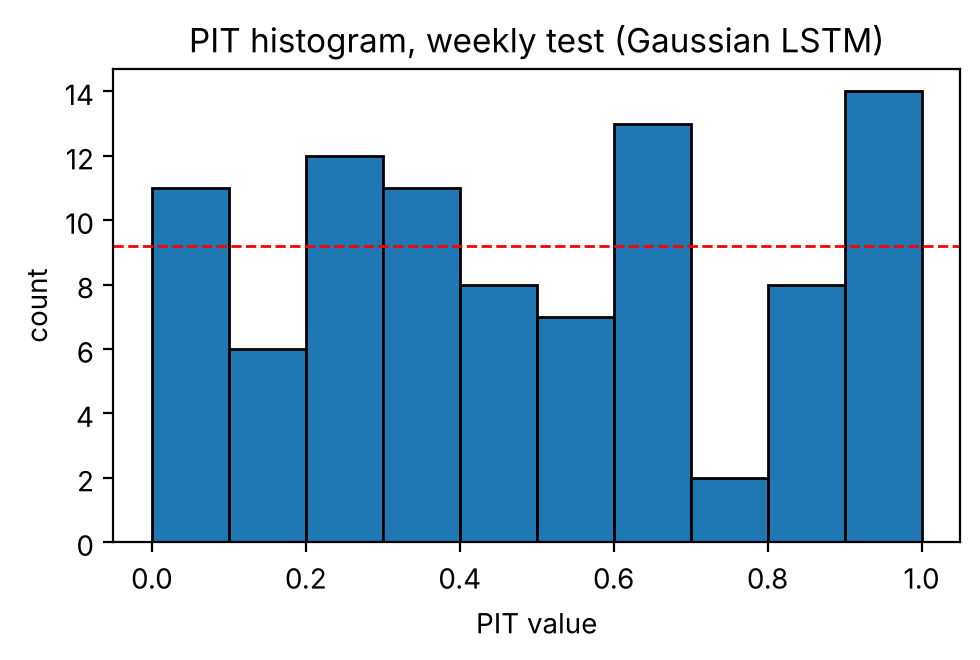

KS test (Gaussian LSTM): stat 0.075, p = 0.658


,weeks,MAE,dir_acc
regime,,,
wholesale falling,39,1.172,0.718
wholesale rising,53,1.656,0.585


In [31]:
fig, ks = X.plot_pit(s1["w"], tuned, title="PIT histogram, weekly test (tuned GARCH-LSTM-t)"); plt.show()
print("KS test of PIT uniformity: stat %.3f, p = %.3f" % (ks.statistic, ks.pvalue))
fig, ks_g = X.plot_pit(s1["w"], s1["res"]["Gaussian LSTM (x3)"], title="PIT histogram, weekly test (Gaussian LSTM)"); plt.show()
print("KS test (Gaussian LSTM): stat %.3f, p = %.3f" % (ks_g.statistic, ks_g.pvalue))
display(X.error_by_regime(s1["w"], tuned).round(3))

**Reading.** The PIT histogram is roughly uniform but not flat: the top bin holds 16 of 92 weeks against about 9 expected and the 0.7 to 0.8 bin only 3, so realized price increases land in the upper tail of our forecast more often than they should. The KS test does not reject uniformity for the tuned model (p = 0.34) or the Gaussian LSTM (p = 0.66), but with 92 test weeks this test has low power and cannot separate them. The error breakdown shows where the weakness is: when wholesale prices are rising the model is worse (MAE 1.66, direction 0.59) than when they are falling (MAE 1.17, direction 0.72), consistent with the rockets-and-feathers asymmetry and with the upper-tail excess in the PIT.

In [32]:
# Revision 1: targeted calibration tests for the weekly forecast. KS spreads its power over the whole PIT curve;
# these tests look only at the failures the histogram shows (upper tail, interval coverage, mean bias), and by regime.
from scipy import stats as st
dd = tuned.loc[X.WTE[0]:X.WTE[1]].dropna(); ww = s1["w"].loc[dd.index]
u = E.cdf(ww.y.values * 100, dd.mu.values, dd.scale.values, dd.df.values)
regime = np.where(ww.d_gulf.values > 0, "wholesale rising", "wholesale falling")

def pit_tests(u, label):
    n = len(u); hi, lo, in80 = int((u > .9).sum()), int((u < .1).sum()), int((np.abs(u - .5) <= .4).sum())
    return [dict(group=label, test="upper tail (PIT > 0.9)", observed=hi, expected=round(.1 * n, 1), rate=hi / n, p_value=st.binomtest(hi, n, .1).pvalue),
            dict(group=label, test="lower tail (PIT < 0.1)", observed=lo, expected=round(.1 * n, 1), rate=lo / n, p_value=st.binomtest(lo, n, .1).pvalue),
            dict(group=label, test="80% interval coverage", observed=in80, expected=round(.8 * n, 1), rate=in80 / n, p_value=st.binomtest(in80, n, .8).pvalue),
            dict(group=label, test="mean PIT (0.5 = unbiased)", observed=n, expected=np.nan, rate=u.mean(), p_value=st.ttest_1samp(u, .5).pvalue)]

rows = pit_tests(u, f"all test weeks (n={len(u)})")
for g in ["wholesale rising", "wholesale falling"]:
    rows += pit_tests(u[regime == g], f"{g} (n={(regime == g).sum()})")
pit_tab = pd.DataFrame(rows)
display(pit_tab.round(3))
print("All tests two-sided binomial (t-test for the mean). With 12 tests, use p < 0.004 (Bonferroni) before calling a regime result firm.")
a = pit_tab.set_index(["group", "test"]); allg = pit_tab.group.iloc[0]
hi_r = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale rising"))].iloc[0]
hi_f = pit_tab[(pit_tab.test.str.startswith("80%")) & (pit_tab.group.str.startswith("wholesale falling"))].iloc[0]
print("\nResult: upper tail %d of %d weeks (expected %.1f, p = %.3f); 80%% coverage %.2f (p = %.3f); coverage %.2f when wholesale rises "
      "(p = %.3f) vs %.2f when it falls (p = %.3f)." % (a.loc[(allg, "upper tail (PIT > 0.9)"), "observed"], len(u), .1 * len(u),
      a.loc[(allg, "upper tail (PIT > 0.9)"), "p_value"], a.loc[(allg, "80% interval coverage"), "rate"], a.loc[(allg, "80% interval coverage"), "p_value"],
      hi_r.rate, hi_r.p_value, hi_f.rate, hi_f.p_value))

,group,test,observed,expected,rate,p_value
0,all test weeks (n=92),upper tail (PIT > 0.9),16,9.2,0.174,0.024
1,all test weeks (n=92),lower tail (PIT < 0.1),8,9.2,0.087,0.862
2,all test weeks (n=92),80% interval coverage,68,73.6,0.739,0.151
3,all test weeks (n=92),mean PIT (0.5 = unbiased),92,NaN,0.515,0.640
4,wholesale rising (n=53),upper tail (PIT > 0.9),10,5.3,0.189,0.039
5,wholesale rising (n=53),lower tail (PIT < 0.1),5,5.3,0.094,1.000
6,wholesale rising (n=53),80% interval coverage,38,42.4,0.717,0.167
7,wholesale rising (n=53),mean PIT (0.5 = unbiased),53,NaN,0.496,0.921
8,wholesale falling (n=39),upper tail (PIT > 0.9),6,3.9,0.154,0.278
9,wholesale falling (n=39),lower tail (PIT < 0.1),3,3.9,0.077,1.000


All tests two-sided binomial (t-test for the mean). With 12 tests, use p < 0.004 (Bonferroni) before calling a regime result firm.

Result: upper tail 16 of 92 weeks (expected 9.2, p = 0.024); 80% coverage 0.74 (p = 0.151); coverage 0.72 when wholesale rises (p = 0.167) vs 0.77 when it falls (p = 0.688).


**Revision 1: targeted tests for the weekly PIT, overall and by regime.**

*What changed.* The cell above adds exact binomial tests aimed at the failures the histogram shows (weeks with PIT above 0.9 or below 0.1, and 80% interval coverage), a t-test of mean PIT, and the same tests split by rising versus falling wholesale prices.

*Why.* The KS test spreads its power across the whole distribution, so with 92 weeks it cannot detect one overloaded bin. The reading above names a specific failure, and a test aimed at that failure is more informative. The regime split links the PIT result to the error-by-regime table.

*Result.* The upper tail holds 16 of 92 weeks against 9.2 expected, which a two-sided binomial test rejects (p = 0.024) even though KS does not (p = 0.34). The 80% coverage of 0.74 is lower than nominal but not significantly so (p = 0.151). By regime, coverage is 0.72 when wholesale prices rise (p = 0.167) and 0.77 when they fall (p = 0.688), and the upper-tail excess is 10 of 53 rising weeks (p = 0.039) against 6 of 39 falling weeks (p = 0.278). Twelve tests are run, so only p < 0.004 should be treated as firm. The tail excess is real at the 5% level, but the regime split is suggestive rather than proven.

,signal,contracts,events,accuracy,atm_accuracy,atm_n,brier,logloss
0,model,520,30,0.9250,0.7833,120,0.0540,0.1858
1,model+market stack,520,30,0.9423,0.8167,120,0.0443,0.1468
2,market mid,520,30,0.9462,0.8333,120,0.0415,0.1430


Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19): {'model': 0.254, 'market': 1.086, 'const': 0.303}


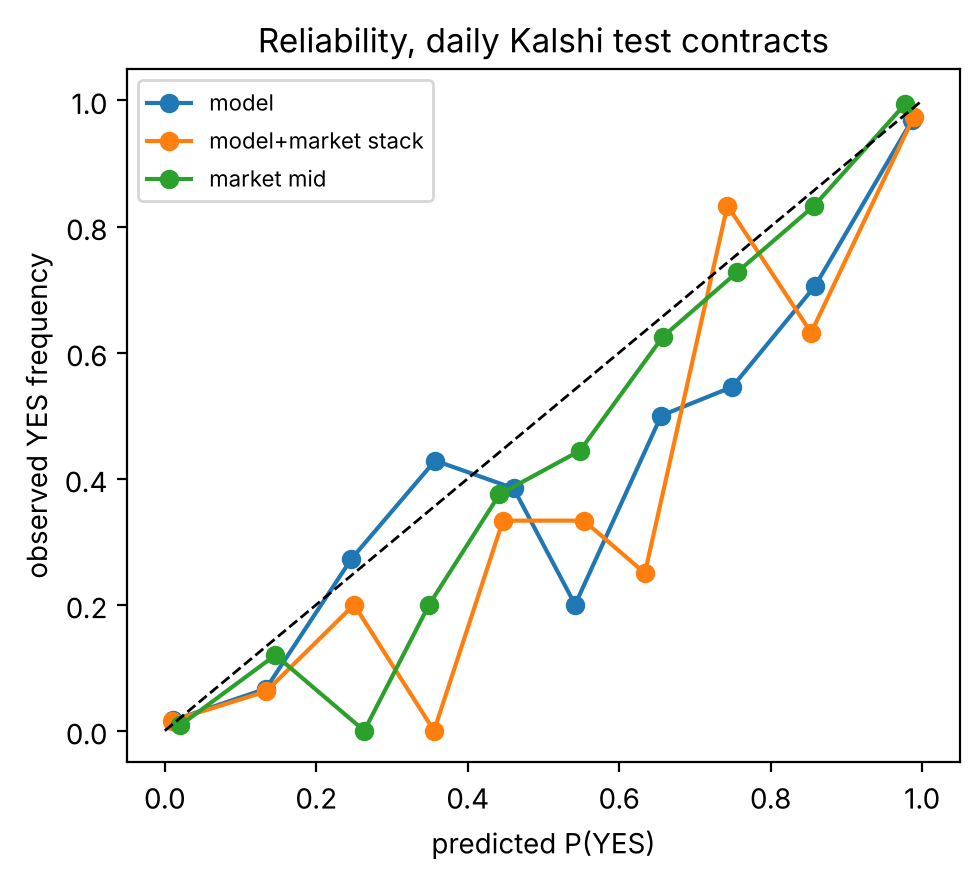

,contracts,accuracy,brier
bucket,,,
<=0.5c,64,0.734,0.188
0.5-1c,60,0.850,0.109
1-2c,120,0.900,0.071
2-3c,120,0.992,0.007
>3c,156,1.000,0.000


In [33]:
# Final daily model: GARCH-LSTM-t (lookback 7, three seeds) fed by the tuned weekly forecast
ds_f = X.daily_stage(tuned.mu, lookbacks=(7,), heads=("t",))
fin = X.final_daily(ds_f)
display(fin["metrics"].round(4))
print("Blend coefficients (fit on the Aug 20 - Sep 19 calibration window; scored on Sep 20 - Oct 19):", {k: round(v, 3) for k, v in fin["stack_coef"].items()})
json.dump(fin["stack_coef"], open("results/stack_coef.json", "w"))
X.plot_reliability(fin); plt.show()
display(X.accuracy_by_distance(fin["model_test"]).round(3))

**Reading.** Scored on Sep 20 to Oct 19 (520 contracts, 30 settlement days), the model alone gets accuracy 0.925 and ATM accuracy 0.783 (Brier 0.054). The blend, fitted on the earlier Aug 20 to Sep 19 calibration window, gets 0.942 and 0.817 (Brier 0.044), slightly behind the market (0.946, 0.833, Brier 0.0415). The blend puts most weight on the market (coefficients 1.09 vs 0.25). The reliability plot rests on only 30 settlement days and is too noisy to read for mispricing; Revision 2 below tests market calibration with proper intervals. Accuracy depends on distance from the price: 0.73 to 0.85 within 1 cent, 0.90 at 1 to 2 cents and 0.99 or better beyond 2 cents.

In [34]:
# Revision 2: is the market really mis-priced? Kalshi mid (1 h after open) vs outcome by price bucket, with 95% CIs
# that resample whole settlement days (all strikes of a day settle on one number). Uses data only, no model.
mk_all = ds_f["contracts"]; mk_all = mk_all[mk_all.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
mk_all = mk_all.dropna(subset=["bid", "ask", "y"]).copy(); mk_all["mid"] = (mk_all.bid + mk_all.ask) / 2
edges = [0, .1, .3, .5, .7, .9, 1.0001]; labels = ["<10c", "10-30c", "30-50c", "50-70c", "70-90c", ">=90c"]
mk_all["bucket"] = pd.cut(mk_all.mid, edges, labels=labels, right=False)
mid_band = mk_all.mid.between(.1, .9)

def calib_stats(m):
    g = m.groupby("bucket", observed=False).agg(price=("mid", "sum"), yes=("y", "sum"), n=("y", "size")).reindex(labels)
    band = m[m.mid.between(.1, .9)]
    gap = (g.yes - g.price) / g.n
    return np.r_[gap.values, (band.y.sum() - band.mid.sum()) / max(len(band), 1)]

days = mk_all.date.unique(); by_day = {d_: x for d_, x in mk_all.groupby("date")}; rng = np.random.default_rng(0)
boot = np.array([calib_stats(pd.concat([by_day[d_] for d_ in rng.choice(days, len(days))])) for _ in range(2000)])
point = calib_stats(mk_all)
g = mk_all.groupby("bucket", observed=False).agg(contracts=("y", "size"), mean_price=("mid", "mean"), yes_rate=("y", "mean")).reindex(labels)
cal_tab = pd.concat([g, pd.DataFrame([[mid_band.sum(), mk_all.mid[mid_band].mean(), mk_all.y[mid_band].mean()]],
                                     index=["all 10-90c"], columns=g.columns)])
cal_tab["yes_minus_price"] = point
cal_tab["ci95_low"] = np.nanpercentile(boot, 2.5, axis=0); cal_tab["ci95_high"] = np.nanpercentile(boot, 97.5, axis=0)
print(f"Kalshi daily AAA, test window, {len(mk_all)} contracts on {len(days)} settlement days (negative = YES priced too high)")
display(cal_tab.round(3))

Kalshi daily AAA, test window, 1105 contracts on 61 settlement days (negative = YES priced too high)


,contracts,mean_price,yes_rate,yes_minus_price,ci95_low,ci95_high
<10c,395,0.023,0.010,-0.013,-0.023,-0.002
10-30c,79,0.174,0.101,-0.073,-0.147,0.017
30-50c,65,0.388,0.369,-0.018,-0.193,0.133
50-70c,51,0.602,0.667,0.064,-0.091,0.193
70-90c,95,0.798,0.779,-0.020,-0.123,0.073
>=90c,420,0.978,0.998,0.019,0.013,0.024
all 10-90c,291,0.503,0.485,-0.019,-0.097,0.057


**Revision 2: market calibration with day-level confidence intervals.**

*What changed.* The cell above compares the Kalshi mid-price one hour after the open with the outcome in six price buckets over the whole test window (1,105 contracts, 61 settlement days). It gives 95% intervals that resample whole settlement days. It uses market data only, no model.

*Why.* The reading of the reliability plot says YES contracts between 0.3 and 0.9 were priced too high, based on 30 days and no uncertainty. All strikes of a day settle on one number, so contract-level noise understates the uncertainty.

*Result.* The only significant mispricing is at the extremes. Contracts under 10 cents resolved YES 1.0% of the time against an average price of 2.3% (gap -1.3 points, 95% CI -2.3 to -0.2). Contracts at 90 cents or more resolved YES 99.8% against 97.8% (gap +1.9, CI +1.3 to +2.4). So long shots were overpriced and favourites underpriced, the favourite-longshot pattern Bürgi et al. (2026) report for Kalshi. Between 10 and 90 cents every bucket's interval includes zero (pooled gap -1.9 points, CI -9.7 to +5.7). The earlier claim that mid-range YES contracts were overpriced is therefore not supported. The extreme-bucket gaps are 1 to 2 cents, about the size of the 1 to 2 cent spread in those buckets, so they do not by themselves show a tradable edge.

In [35]:
# Small-sample check: 95% confidence intervals that resample whole settlement days (event-block bootstrap)
tw = ds_f["contracts"]; tw = tw[tw.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
priced = E.price_ladder(tw, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]])
_, mk = E.market_metrics(priced)
ci, info = E.event_bootstrap(priced[priced.ticker.isin(mk.ticker)], mk)
print("A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts:", info)
display(ci.round(4))

A = GARCH-LSTM-t, B = Kalshi price 1 h after open, same contracts: {'contracts': 1105, 'events': 61, 'atm_contracts': 247}


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9140,0.8845,0.9372
1,accuracy B,0.9330,0.9162,0.9500
2,accuracy A-B,-0.0190,-0.0472,0.0053
3,Brier A,0.0630,0.0429,0.0901
4,Brier B,0.0489,0.0404,0.0572
5,Brier A-B,0.0141,-0.0054,0.0408
6,ATM accuracy A,0.8016,0.7449,0.8537
7,ATM accuracy B,0.8502,0.8008,0.8964
8,ATM accuracy A-B,-0.0486,-0.0920,-0.0079


**Reading.** Resampling whole settlement days (61 days, 1,105 contracts) gives honest small-sample intervals. The market scores better than the model on every metric, but only the at-the-money gap is significant. ATM accuracy is 0.850 for the market against 0.802 for the model (difference -4.9 points, 95% CI -9.2 to -0.8). Over all strikes, accuracy is 0.933 against 0.914 (difference -1.9 points, CI -4.7 to +0.5) and Brier is 0.049 against 0.063 (difference +0.014, CI -0.005 to +0.041); both intervals include zero. Part of the gap may be the extra hour of information the market has; Stage 3 will compare at matched times.

In [36]:
# Revision 3: does the model add anything to the market? Split the blend's gain into (a) re-calibrating the market alone
# and (b) adding the model on top. Same calibration window (Aug 20 - Sep 19) and the same untouched test window (Sep 20 - Oct 19).
from sklearn.linear_model import LogisticRegression
lg = lambda p: np.log(p / (1 - p))
c_te = ds_f["contracts"]; c_te = c_te[c_te.date.isin(ds_f["df"].loc[X.TE[0]:X.TE[1]].index)]
ct_all = E.price_ladder(c_te, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]]).dropna(subset=["bid", "ask", "y"])
cfit, ctst = ct_all[ct_all.date <= "2026-09-19"], ct_all[ct_all.date > "2026-09-19"].copy()
mkt_logit = lambda c: lg(((c.bid + c.ask) / 2).clip(.01, .99)).values[:, None]
lr_m = LogisticRegression(C=1.0).fit(mkt_logit(cfit), cfit.y)
recal = ctst.copy(); recal["p"] = np.clip(lr_m.predict_proba(mkt_logit(ctst))[:, 1], 1e-4, 1 - 1e-4)
st_t = fin["stacked_test"]; mk_t = fin["market_test"]
summary = pd.DataFrame([{"signal": "market mid", **E.contract_metrics(mk_t)},
                        {"signal": "market re-calibrated (no model)", **E.contract_metrics(recal)},
                        {"signal": "model + market blend", **E.contract_metrics(st_t)}])
display(summary.round(4))
print("market-only recalibration: logit(p) = %.3f * logit(mid) + %.3f" % (lr_m.coef_[0][0], lr_m.intercept_[0]))
ci_mod, info3 = E.event_bootstrap(st_t, recal)          # A = blend, B = re-calibrated market: isolates the model's contribution
ci_cal, _ = E.event_bootstrap(recal, mk_t)              # A = re-calibrated market, B = raw market: the recalibration effect
print("A = model + market blend, B = market re-calibrated without the model:", info3); display(ci_mod.round(4))
print("A = market re-calibrated, B = raw market mid:"); display(ci_cal.round(4))
b = ci_mod.set_index("metric"); c_ = ci_cal.set_index("metric")
print("\nResult: model's contribution beyond a re-calibrated market: Brier %+.4f (95%% CI %+.4f to %+.4f), ATM accuracy %+.3f (CI %+.3f to %+.3f); "
      "re-calibrating the market alone changes Brier by %+.4f (CI %+.4f to %+.4f)." % (b.loc["Brier A-B", "estimate"], b.loc["Brier A-B", "ci95_low"],
      b.loc["Brier A-B", "ci95_high"], b.loc["ATM accuracy A-B", "estimate"], b.loc["ATM accuracy A-B", "ci95_low"], b.loc["ATM accuracy A-B", "ci95_high"],
      c_.loc["Brier A-B", "estimate"], c_.loc["Brier A-B", "ci95_low"], c_.loc["Brier A-B", "ci95_high"]))

,signal,contracts,events,accuracy,atm_accuracy,atm_n,brier,logloss
0,market mid,520,30,0.9462,0.8333,120,0.0415,0.1430
1,market re-calibrated (no model),520,30,0.9442,0.8250,120,0.0420,0.1403
2,model + market blend,520,30,0.9423,0.8167,120,0.0443,0.1468


market-only recalibration: logit(p) = 1.372 * logit(mid) + 0.123


A = model + market blend, B = market re-calibrated without the model: {'contracts': 520, 'events': 30, 'atm_contracts': 120}


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9423,0.9235,0.9596
1,accuracy B,0.9442,0.9255,0.9615
2,accuracy A-B,-0.0019,-0.0118,0.0078
3,Brier A,0.0443,0.0315,0.0585
4,Brier B,0.0420,0.0301,0.0559
5,Brier A-B,0.0023,-0.0011,0.0061
6,ATM accuracy A,0.8167,0.7415,0.8833
7,ATM accuracy B,0.8250,0.7500,0.9000
8,ATM accuracy A-B,-0.0083,-0.0417,0.0250


A = market re-calibrated, B = raw market mid:


,metric,estimate,ci95_low,ci95_high
0,accuracy A,0.9442,0.9255,0.9615
1,accuracy B,0.9462,0.9275,0.9623
2,accuracy A-B,-0.0019,-0.0059,0.0000
3,Brier A,0.0420,0.0301,0.0559
4,Brier B,0.0415,0.0312,0.0540
5,Brier A-B,0.0005,-0.0015,0.0026
6,ATM accuracy A,0.8250,0.7500,0.9000
7,ATM accuracy B,0.8333,0.7583,0.9000
8,ATM accuracy A-B,-0.0083,-0.0250,0.0000



Result: model's contribution beyond a re-calibrated market: Brier +0.0023 (95% CI -0.0011 to +0.0061), ATM accuracy -0.008 (CI -0.042 to +0.025); re-calibrating the market alone changes Brier by +0.0005 (CI -0.0015 to +0.0026).


**Revision 3: separating what the model adds from re-calibrating the market.**

*What changed.* The cell above fits a market-only logistic recalibration on the same Aug 20 to Sep 19 window as the blend. It then compares three signals on Sep 20 to Oct 19: raw market, re-calibrated market and model plus market. Day-level bootstrap intervals are given for each step.

*Why.* The blend gives the market a coefficient of 1.09 and the model only 0.25. A market coefficient above 1 means the blend partly just stretches the market's probabilities away from 0.5. Without this split, the blend's score cannot be credited to the model.

*Result.* Re-calibrating the market alone gives a coefficient of 1.37 but does not help out of sample (Brier 0.0420 vs 0.0415 for the raw mid, difference +0.0005, CI -0.0015 to +0.0026). The model's own contribution on top of the re-calibrated market is a Brier difference of +0.0023 (95% CI -0.0011 to +0.0061; positive means the blend is worse) and an ATM accuracy difference of -0.008 (CI -0.042 to +0.025). Both intervals include zero, so the model adds no detectable information to the market at 9 a.m.

In [37]:
display(fin["backtest"].round(4))
y19 = fin["trades_stack"]; y19 = y19[y19.date == "2026-10-19"]
print("Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at", aaa.loc["2026-10-19"], "):")
display(y19[["ticker", "strike", "prev", "bid", "ask", "p", "y", "trade", "pnl"]].round(3))
yy = fin["model_test"]; yy = yy[yy.date == "2026-10-19"]
print("Model-only accuracy on that event: %.3f over %d strikes" % (((yy.p > .5) == (yy.y == 1)).mean(), len(yy)))

,signal,trades,hit_rate,pnl_per_contract,total_pnl_$,capital_$,roi
0,model,133,0.5113,-0.0133,-1.7663,68.46,-0.0258
1,model+market stack,92,0.7500,-0.0239,-2.1949,70.23,-0.0313


Oct 19 contract KXAAAGASD-26OCT19 (opened 8:00 a.m. ET Oct 18, settled at 4.2953 ):


,ticker,strike,prev,bid,ask,p,y,trade,pnl
22,KXAAAGASD-26OCT19-4.3150,4.315,4.299,0.01,0.02,0.003,0.0,False,0.0
23,KXAAAGASD-26OCT19-4.3100,4.310,4.299,0.01,0.02,0.003,0.0,False,0.0
24,KXAAAGASD-26OCT19-4.3050,4.305,4.299,0.01,0.02,0.005,0.0,False,0.0
25,KXAAAGASD-26OCT19-4.3000,4.300,4.299,0.10,0.11,0.065,0.0,False,0.0
26,KXAAAGASD-26OCT19-4.2950,4.295,4.299,0.38,0.45,0.446,1.0,False,0.0
27,KXAAAGASD-26OCT19-4.2900,4.290,4.299,0.98,0.99,0.995,1.0,False,0.0
28,KXAAAGASD-26OCT19-4.2850,4.285,4.299,0.98,0.99,0.997,1.0,False,0.0


Model-only accuracy on that event: 0.941 over 17 strikes


**Reading.** Fees follow Kalshi's schedule effective July 7, 2026 (Kalshi, 2026): 0.07 x P x (1 - P), rounded up to the centicent (an earlier version of this notebook rounded to the cent and overstated fees). Trading at 9:00 a.m. with a 3-cent edge threshold loses: model-only -2.6% ROI (133 trades, 51% won) and the blend -3.1% (92 trades, 75% won). The blend wins most trades yet loses money because it mostly buys expensive favorites (average cost about 76 cents per contract), so each win is small and each loss is large. So at 9:00 a.m. there is no tradable edge. On the Oct 19 contract the model got 16 of 17 strikes right (0.941). Trading optimization stays optional, as the feedback recommends.

In [38]:
# Revision 4: how sure are we that the 9 a.m. strategies lose? Day-block bootstrap of total P&L and ROI, split by side
# (YES vs NO), against two no-skill controls on the same book: buy every YES, or every NO, priced 20-80 cents.
def side_pnl(tr, edge=0.03):
    t = tr[tr.trade].copy(); no_px = 1 - t.bid
    t["side"] = np.where(t.p - t.ask - E.kalshi_fee(t.ask) > edge, "YES", "NO")
    t["cost"] = np.where(t.side == "YES", t.ask, no_px); return t[["date", "side", "cost", "pnl"]]

def blind(c, side):
    c = c.dropna(subset=["bid", "ask", "y"]); c = c[(c.ask > 0) & (c.ask < 1) & (c.bid > 0)]
    px = c.ask if side == "YES" else 1 - c.bid; keep = px.between(.20, .80); c, px = c[keep], px[keep]
    win = c.y if side == "YES" else 1 - c.y
    return pd.DataFrame({"date": c.date, "side": side, "cost": px, "pnl": win - px - E.kalshi_fee(px)})

def boot_roi(t, n=2000, seed=0):
    g = t.groupby("date")[["pnl", "cost"]].sum(); rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(g), (n, len(g))); P_, C_ = g.pnl.values[idx].sum(1), g.cost.values[idx].sum(1)
    return dict(trades=len(t), days=len(g), total_pnl=g.pnl.sum(), roi=g.pnl.sum() / g.cost.sum(),
                roi_ci95_low=np.percentile(P_ / C_, 2.5), roi_ci95_high=np.percentile(P_ / C_, 97.5),
                share_days_positive=(g.pnl > 0).mean())

book_te = fin["trades_model"]                               # Sep 20 - Oct 19 contracts with a 9 a.m. book
legs = {"model": side_pnl(fin["trades_model"]), "model+market blend": side_pnl(fin["trades_stack"]),
        "control: every YES 20-80c": blind(book_te, "YES"), "control: every NO 20-80c": blind(book_te, "NO")}
rows = []
for name, t in legs.items():
    for side in (["all"] + sorted(t.side.unique()) if not name.startswith("control") else ["all"]):
        tt = t if side == "all" else t[t.side == side]
        if len(tt): rows.append({"strategy": name, "side": side, **boot_roi(tt)})
bt_tab = pd.DataFrame(rows); bt_tab.insert(0, "window", "Sep 20 - Oct 19")
c_cal = ds_f["contracts"]; c_cal = c_cal[c_cal.date.isin(ds_f["df"].loc[X.TE[0]:"2026-09-19"].index)]     # same controls, earlier month
bt_tab = pd.concat([bt_tab, pd.DataFrame([{"window": "Aug 20 - Sep 19", "strategy": f"control: every {s_} 20-80c", "side": "all",
                                           **boot_roi(blind(c_cal, s_))} for s_ in ("YES", "NO")])], ignore_index=True)
display(bt_tab.round(3))
r_ = bt_tab.set_index(["window", "strategy", "side"])
def _f(k):
    if k not in r_.index: return "no trades"
    x = r_.loc[k]; return "%+.1f%% (95%% CI %+.1f%% to %+.1f%%, %d trades)" % (100 * x.roi, 100 * x.roi_ci95_low, 100 * x.roi_ci95_high, x.trades)
W = "Sep 20 - Oct 19"
print("\nResult: model %s; model NO side %s; model YES side %s; blend %s. Controls: every YES %s and every NO %s in Sep 20 - Oct 19, "
      "every NO %s in Aug 20 - Sep 19." % (_f((W, "model", "all")), _f((W, "model", "NO")), _f((W, "model", "YES")), _f((W, "model+market blend", "all")),
      _f((W, "control: every YES 20-80c", "all")), _f((W, "control: every NO 20-80c", "all")), _f(("Aug 20 - Sep 19", "control: every NO 20-80c", "all"))))

,window,strategy,side,trades,days,total_pnl,roi,roi_ci95_low,roi_ci95_high,share_days_positive
0,Sep 20 - Oct 19,model,all,133,29,-1.766,-0.026,-0.207,0.154,0.483
1,Sep 20 - Oct 19,model,NO,53,15,2.125,0.078,-0.219,0.286,0.533
2,Sep 20 - Oct 19,model,YES,80,19,-3.891,-0.095,-0.330,0.165,0.474
3,Sep 20 - Oct 19,model+market blend,all,92,27,-2.195,-0.031,-0.173,0.100,0.593
4,Sep 20 - Oct 19,model+market blend,NO,21,10,0.837,0.049,-0.229,0.261,0.800
5,Sep 20 - Oct 19,model+market blend,YES,71,24,-3.032,-0.057,-0.205,0.091,0.625
6,Sep 20 - Oct 19,control: every YES 20-80c,all,69,30,-9.568,-0.255,-0.470,-0.037,0.367
7,Sep 20 - Oct 19,control: every NO 20-80c,all,68,30,4.021,0.130,-0.151,0.398,0.500
8,Aug 20 - Sep 19,control: every YES 20-80c,all,113,31,-8.249,-0.151,-0.434,0.127,0.452
9,Aug 20 - Sep 19,control: every NO 20-80c,all,108,31,-13.704,-0.254,-0.513,0.031,0.387



Result: model -2.6% (95% CI -20.7% to +15.4%, 133 trades); model NO side +7.8% (95% CI -21.9% to +28.6%, 53 trades); model YES side -9.5% (95% CI -33.0% to +16.5%, 80 trades); blend -3.1% (95% CI -17.3% to +10.0%, 92 trades). Controls: every YES -25.5% (95% CI -47.0% to -3.7%, 69 trades) and every NO +13.0% (95% CI -15.1% to +39.8%, 68 trades) in Sep 20 - Oct 19, every NO -25.4% (95% CI -51.3% to +3.1%, 108 trades) in Aug 20 - Sep 19.


**Revision 4: uncertainty and no-skill controls for the 9 a.m. backtest.**

*What changed.* The cell above splits each strategy's trades into YES and NO buys. It adds 95% intervals for ROI that resample whole settlement days, and the share of days with positive P&L. It also adds two no-skill controls on the same book: buy every YES, or every NO, priced 20 to 80 cents. The controls are run in both months.

*Why.* The backtest gave one ROI per strategy with no uncertainty, and trades on the same day are not independent. A model is only useful if it beats blindly taking one side.

*Result.* The controls show how much the outcome depends on the month. Buying every YES lost in both months (-25.5%, CI -47.0% to -3.7%, Sep 20 to Oct 19; -15.1%, CI -43.4% to +12.7%, Aug 20 to Sep 19). Buying every NO gained +13.0% (CI -15.1% to +39.8%) in the second month but lost -25.4% (CI -51.3% to +3.1%) in the first. For the model and the blend, the day-block intervals all include zero: the model returned -2.6% (CI -20.7% to +15.4%, 133 trades), +7.8% on its NO-side trades and -9.5% on its YES-side trades, and the blend -3.1% (CI -17.3% to +10.0%, 92 trades). A strategy that only beats the control by taking more NO positions in a month when prices fell has no demonstrated edge. All intervals are wide, so 30 days cannot settle the question either way.

In [39]:
# Minimum-implementation fallback: the 10-year weekly model alone, scored out of sample on real Kalshi WEEKLY AAA contracts
# (forecast origins in the weekly test period from 2025; EIA->AAA basis estimated only on Mondays before 2025)
wk = X.weekly_on_kalshi(s1["w"], tuned)
print("EIA->AAA basis used: mean %.3f $/gal, sd %.3f (n = %d)" % (wk["basis_mean"], wk["basis_sd"], wk["basis_n"]))
print({k: round(v, 3) if isinstance(v, float) else v for k, v in wk["metrics"].items()})

EIA->AAA basis used: mean 0.002 $/gal, sd 0.018 (n = 455)
{'contracts': 967, 'events': 88, 'accuracy': 0.73, 'atm_accuracy': 0.653, 'atm_n': 72, 'brier': 0.192, 'logloss': 0.628}


**Reading.** The minimum-implementation fallback works but is clearly weaker. Scored out of sample on 967 real Kalshi weekly AAA contracts (88 events whose forecast origin falls in the weekly test period, with the EIA-to-AAA basis estimated only on 36 Mondays before 2025), the 10-year weekly model alone gets accuracy 0.730, ATM accuracy 0.653 and Brier 0.192. The daily model scores 0.914 on daily contracts, but the horizons differ (one week versus one day), so the comparison only shows that the fallback is a usable, evaluated deliverable if daily labels became unavailable.

### Tomorrow's forecast
Trains once and saves `model/` if it is not there yet, then prints tomorrow's AAA price, 80% and 95% intervals and confidence.

In [40]:
import json
from pathlib import Path
from gaslab import service
json.dump(p3["wcfg"], open("results/weekly_cfg.json", "w"))
if not Path("model/meta.json").exists():
    service.train(seeds=3)
fc = service.forecast()

AAA national average forecast for 2026-11-04 (last value 2026-11-03: $4.1493)
  Forecast price : $4.1310  (-1.83 cents)
  80% interval   : $4.1213 to $4.1407
  95% interval   : $4.1145 to $4.1476
  Direction      : DOWN with 98% probability
  Confidence     : 51% chance the price lands within +/- half a cent of the forecast


In [41]:
# Revision 5: score the published forecast against what actually happened. Pulls the settled AAA value for the
# forecast date from Kalshi's public API (no key needed); if that fails, type the AAA value into REALIZED.
import urllib.request
REALIZED = None                                          # if the API is unreachable, type the AAA value for the forecast date here, e.g. REALIZED = 4.2900
tgt = pd.Timestamp(fc["target_date"]); ev = "KXAAAGASD-" + tgt.strftime("%y%b%d").upper()
settled = None
try:
    url = f"https://api.elections.kalshi.com/trade-api/v2/markets?event_ticker={ev}&limit=200"
    mkts = json.load(urllib.request.urlopen(url, timeout=15))["markets"]
    settled = pd.DataFrame([dict(ticker=m["ticker"], strike=float(m.get("floor_strike") or m["ticker"].split("-")[-1]),
                                 result=m.get("result"), value=m.get("expiration_value")) for m in mkts])
    vals = pd.to_numeric(settled.value, errors="coerce").dropna()
    if REALIZED is None and len(vals): REALIZED = float(vals.iloc[0])
except Exception as e:
    print("Kalshi API not reachable (%s); using REALIZED as typed." % type(e).__name__)
if REALIZED is None:
    print(f"{ev} has not settled yet and no REALIZED value was typed in; nothing to score.")
else:
    from scipy import stats as st
    A0 = fc["last_aaa"]; dist = st.t(df=fc["df"], loc=fc["mu_pct"], scale=fc["scale_pct"]) if np.isfinite(fc["df"]) else st.norm(fc["mu_pct"], fc["scale_pct"])
    pit = float(dist.cdf(100 * np.log(REALIZED / A0)))
    chk = {"forecast date": fc["target_date"], "forecast $": round(fc["forecast"], 4), "realized $": round(REALIZED, 4),
           "error (cents)": round((REALIZED - fc["forecast"]) * 100, 2),
           "direction right": bool(np.sign(REALIZED - A0) == np.sign(fc["forecast"] - A0)),
           "inside 80% interval": bool(fc["interval80"][0] <= REALIZED <= fc["interval80"][1]),
           "inside 95% interval": bool(fc["interval95"][0] <= REALIZED <= fc["interval95"][1]), "PIT": round(pit, 3)}
    display(pd.Series(chk, name="out-of-sample check").to_frame())
    print("Result: forecast $%.4f, realized $%.4f (error %+.2f cents), direction %s, %s the 80%% interval, %s the 95%% interval, PIT %.2f." % (
          fc["forecast"], REALIZED, chk["error (cents)"], "right" if chk["direction right"] else "wrong",
          "inside" if chk["inside 80% interval"] else "outside", "inside" if chk["inside 95% interval"] else "outside", pit))
    if settled is not None and settled.result.isin(["yes", "no"]).any():
        s = settled[settled.result.isin(["yes", "no"])].copy(); s["y"] = (s.result == "yes").astype(float)
        s["p"] = np.clip(1 - dist.cdf(100 * np.log(s.strike / A0)), 1e-4, 1 - 1e-4)
        atm = (np.abs(s.strike - A0) * 100 <= 1.0)
        print(f"{ev}: {len(s)} strikes, model accuracy {((s.p > .5) == (s.y == 1)).mean():.3f}, "
              f"ATM accuracy {((s.p[atm] > .5) == (s.y[atm] == 1)).mean():.3f} (n={atm.sum()}), Brier {np.mean((s.p - s.y) ** 2):.4f}")

,out-of-sample check
forecast date,2026-11-04
forecast $,4.131
realized $,4.1239
error (cents),-0.71
direction right,True
inside 80% interval,True
inside 95% interval,True
PIT,0.166


Result: forecast $4.1310, realized $4.1239 (error -0.71 cents), direction right, inside the 80% interval, inside the 95% interval, PIT 0.17.
KXAAAGASD-26NOV04: 17 strikes, model accuracy 0.882, ATM accuracy 1.000 (n=4), Brier 0.0617


**Revision 5: scoring the published forecast against what happened.**

*What changed.* The cell above pulls the settled AAA value for the forecast date from Kalshi's public API (with a manual fallback). It reports the error in cents, whether the price fell inside the 80% and 95% intervals, the direction, the PIT, and the accuracy and Brier score across that day's listed strikes.

*Why.* The forecast was printed without being checked. The forecast date has now passed, so it is a genuine out-of-sample test of the deliverable, with no possibility of tuning to it.

*Result.* The forecast for Nov 4 was $4.1310 (down 1.83 cents from $4.1493); the settled value was $4.1239, an error of -0.71 cents. The direction was right, the value fell inside the 80% and 95% intervals, and the PIT was 0.17. Across that day's 17 listed strikes the model was right on 0.882 (ATM 4 of 4) with Brier 0.0617. One day is an anecdote, not evidence, but it confirms the pipeline works end to end on unseen data. The same cell can be re-run daily during Stage 3 to build a forward track record.

## 5.6 Learning, generalization and failure diagnostics of the final models

The sections above test calibration (PIT), the market benchmark and the backtest. Parts 2 and 3 already show the weekly learning curves, the convergence tables for the Stage 1 runs, the seed spread of validation NLL, Diebold–Mariano tests and the dropout, learning-rate and L2 experiments. Those diagnostics are not repeated here. This section asks the questions they leave open, for the two models that are actually delivered: the **tuned weekly GARCH-LSTM-t** and the **final daily GARCH-LSTM-t (lookback 7, fed by the tuned weekly forecast)**.

| Step | Diagnostic | Question it answers |
|---|---|---|
| 5.6a | Train / validation / test metrics, skill relative to the ECM, target-shift table, convergence of the final daily runs | Is the model underfitting, overfitting or generalizing, and how much of the test-period change is the data rather than the model? |
| 5.6b | Confusion matrix, precision, recall, F1, balanced accuracy by distance from the price, with a no-change baseline; threshold check | Does the headline accuracy (0.914) measure skill, or easy contracts? Which error type dominates? |
| 5.6c | Residual analysis (bias, Ljung–Box, coverage at 50/80/95%), error breakdown by kind of day, worst-day table | Is anything systematic left in the errors, and where does the model fail? |
| 5.6d | Contract-level seed stability | Would another seed have taken the other side of the same contract? |
| 5.6e | Summary table and decisions | What changes in the next modeling round? |

Rules: identical splits to Parts 2 and 3 (weekly train 2016–22, validation 2023–24, test 2025–26; daily train to Jun 30 2026, validation Jul 1 – Aug 19, test from Aug 20). Nothing is tuned on the test window; the one threshold check in 5.6b is chosen on the first half of the test window and scored on the second half, the same split the blend uses. Every verdict printed by the code follows a rule stated in the cell, and all of them are collected in 5.6e.

n  sd_pct  mean_abs_pct  share_up
data          split                                      
weekly retail train   365   2.021         1.463     0.512
              val     105   1.457         1.164     0.429
              test     92   2.513         1.590     0.500
daily AAA     train  3599   0.348         0.230     0.414
              val      50   0.462         0.335     0.440
              test     61   0.435         0.272     0.492

WEEKLY (train 2016-22, val 2023-24, test 2025-26)


NLL               NLL_skill_vs_Asymmetric                  MAE                cov80                    n             
split                              train    val   test                   train    val   test  train    val   test  train    val   test  train    val  test
model                                                                                                                                                     
Asymmetric ECM                     1.885  1.713  2.336                   0.000  0.000  0.000  1.115  1.021  1.433  0.877  0.905  0.772  365.0  105.0  92.0
GARCH-LSTM-t tuned (final weekly)  1.659  1.680  2.005                  -0.226 -0.033 -0.331  1.048  0.991  1.451  0.858  0.829  0.739  365.0  105.0  92.0
Persistence                        2.361  1.801  2.723                   0.476  0.088  0.387  1.463  1.164  1.590  0.764  0.848  0.761  365.0  105.0  92.0

DAILY (train to Jun 30 2026, val Jul 1 - Aug 19, test from Aug 20); accuracy/Brier on the Kalshi strikes of those days


NLL               NLL_skill_vs_Daily                cov80              accuracy                brier                     n        \
split                  train    val   test              train    val   test  train   val   test    train    val   test  train    val   test   train   val   
model                                                                                                                                                       
Daily ECM             -0.192  0.597  0.584              0.000  0.000  0.000  0.884  0.72  0.770    0.901  0.898  0.911  0.072  0.075  0.071  3181.0  50.0   
GARCH-LSTM-t lb7 (x3) -0.689 -0.169 -0.134             -0.497 -0.766 -0.718  0.853  0.76  0.705    0.930  0.918  0.914  0.052  0.062  0.063  3181.0  50.0   
Momentum              -0.135  0.695  0.493              0.057  0.098 -0.091  0.810  0.86  0.852    0.890  0.883  0.888  0.082  0.090  0.086  3181.0  50.0   
Persistence            0.612  1.092  0.709              0.804  0.495  0.125  0.649  0.70  0.803    0.799  0.851  0.873  0.146  0.113  0.102  3181.0  50.0   

                             
split                  test  
model                        
Daily ECM              61.0  
GARCH-LSTM-t lb7 (x3)  61.0  
Momentum               61.0  
Persistence            61.0


weekly: NLL train 1.659 -> val 1.680 -> test 2.005 (gap test-train +0.346; ECM gap +0.451). Skill vs ECM: train -0.226, test -0.331. 80% coverage train 0.86, val 0.83, test 0.74.
  -> GENERALIZES: most of its training-period advantage over the ECM survives on test

daily: NLL train -0.689 -> val -0.169 -> test -0.134 (gap test-train +0.555; ECM gap +0.776). Skill vs ECM: train -0.497, test -0.718. 80% coverage train 0.85, val 0.76, test 0.70.
  -> GENERALIZES: most of its training-period advantage over the ECM survives on test


,seed,epochs_run,best_epoch,train_loss_at_best,val_loss_at_best,final_train_loss,final_val_loss,val_minus_train_at_best,train_windows
0,0,101,41,-0.596,-0.080,-0.692,0.123,0.516,3181
1,1,78,18,-0.503,-0.076,-0.654,0.120,0.427,3181
2,2,75,15,-0.501,-0.107,-0.688,0.156,0.394,3181


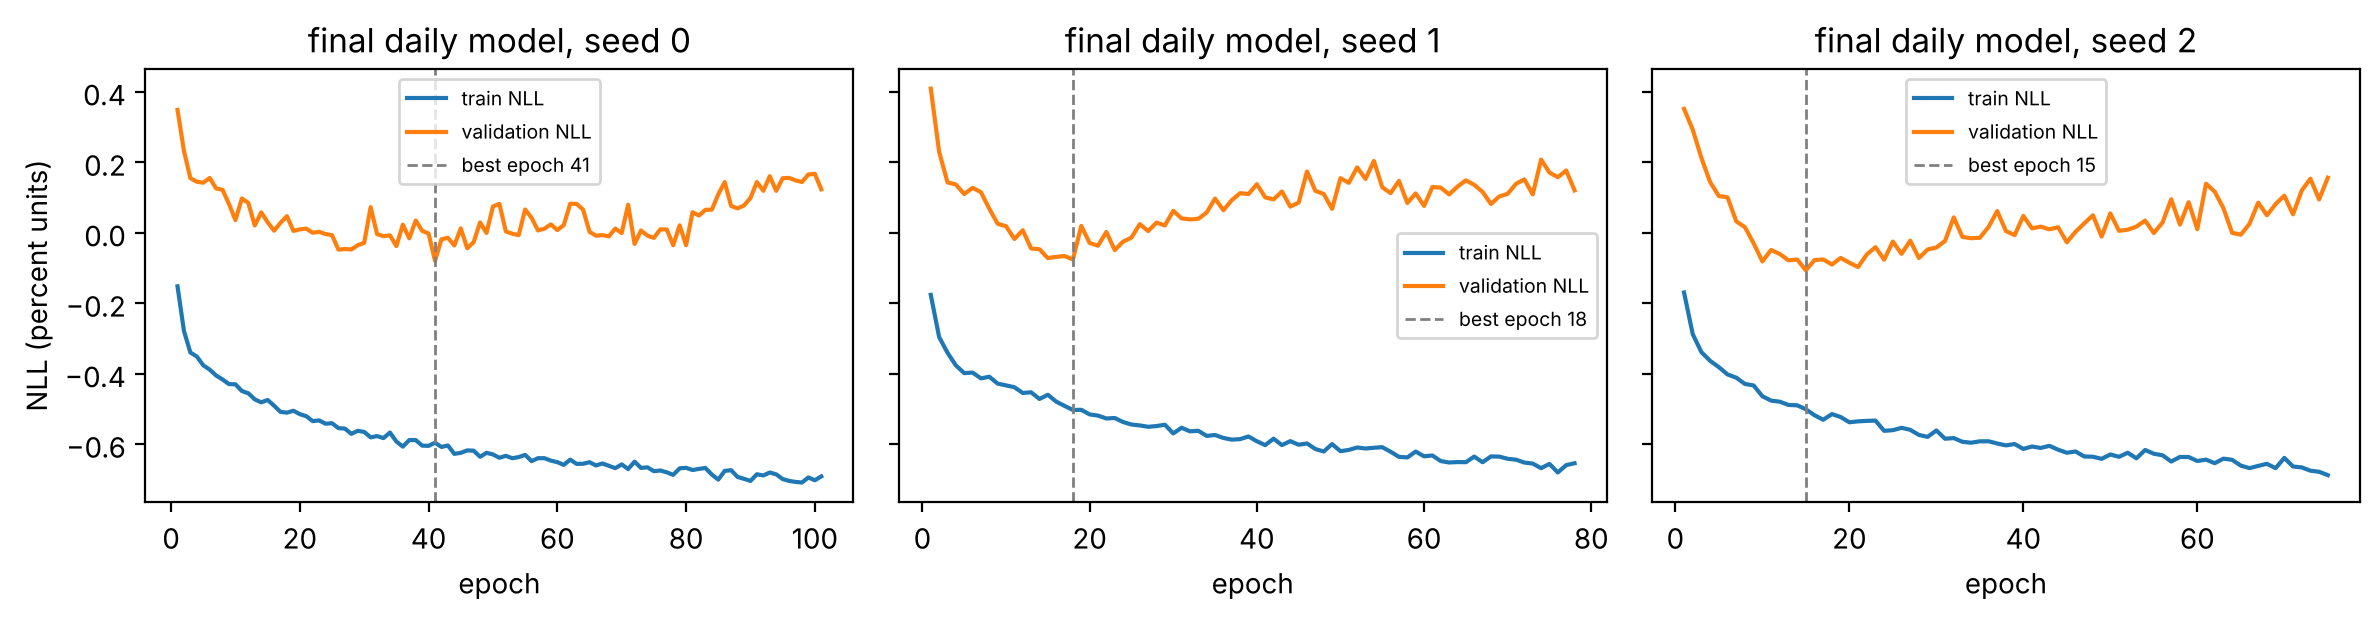

Convergence: best epoch 15-41 of 101 run; after the best epoch training NLL keeps falling (-0.533 -> -0.678) while validation NLL rises by 0.221 on average. 3181 training windows.


In [42]:
# 5.6a  Generalization gap of the FINAL models: identical metrics on the training, validation and test periods.
# Raw train-to-test changes mix overfitting with the fact that 2025-26 was more volatile, so every model is also
# scored RELATIVE to the ECM baseline on the same period ("skill" = NLL - ECM NLL; negative = better than ECM).
# If the network's skill over the ECM is much larger on training data than on test data, it learned patterns
# that do not carry over (overfitting). If it is no better than the ECM even on training data, it is underfitting.
# Note: validation was used for early stopping, so validation scores are slightly optimistic for the LSTMs.
from scipy import stats as st
FINDINGS = []                                            # collected by 5.6a-5.6d, summarised in 5.6e

def gap_table(models, y, rngs, ref, contracts=None):
    common = sorted(set.intersection(*[set(d.dropna().index) for d in models.values()]) & set(y.dropna().index))
    models = {k: d.loc[common] for k, d in models.items()}       # same dates for every model (the LSTM loses its lookback rows)
    t = X._rows(models, y, rngs, contracts)
    t["NLL_skill_vs_" + ref.split()[0]] = t.NLL - t.split.map(t[t.model == ref].set_index("split").NLL)
    return t

WR = {"train": (P.W_SPLIT["train_start"], P.W_SPLIT["train_end"]), "val": X.WVA, "test": X.WTE}
DR = {"train": ("2000-01-01", P.D_SPLIT["train_end"]), "val": X.VA, "test": X.TE}
w_mod = {"GARCH-LSTM-t tuned (final weekly)": tuned, "Asymmetric ECM": s1["res"]["Asymmetric ECM"], "Persistence": s1["res"]["Persistence"]}
d_mod = {k: ds_f["res"][k] for k in ["GARCH-LSTM-t lb7 (x3)", "Daily ECM", "Momentum", "Persistence"]}
gw = gap_table(w_mod, s1["w"]["y"], WR, "Asymmetric ECM")
gd = gap_table(d_mod, ds_f["df"]["y"], DR, "Daily ECM", ds_f["contracts"])
order = ["train", "val", "test"]
# Target shift: was the test period simply harder? (data only, no model)
def shift_rows(y, rngs, lab):
    return [dict(data=lab, split=k, n=int(y.loc[a:b].notna().sum()), sd_pct=y.loc[a:b].std() * 100,
                 mean_abs_pct=y.loc[a:b].abs().mean() * 100, share_up=(y.loc[a:b].dropna() > 0).mean()) for k, (a, b) in rngs.items()]
shift_tab = pd.DataFrame(shift_rows(s1["w"]["y"], WR, "weekly retail") + shift_rows(ds_f["df"]["y"], DR, "daily AAA"))
display(shift_tab.set_index(["data", "split"]).round(3))
print("WEEKLY (train 2016-22, val 2023-24, test 2025-26)")
display(gw.pivot(index="model", columns="split", values=["NLL", "NLL_skill_vs_Asymmetric", "MAE", "cov80", "n"])
          .reindex(columns=order, level=1).round(3))
print("DAILY (train to Jun 30 2026, val Jul 1 - Aug 19, test from Aug 20); accuracy/Brier on the Kalshi strikes of those days")
display(gd.pivot(index="model", columns="split", values=["NLL", "NLL_skill_vs_Daily", "cov80", "accuracy", "brier", "n"])
          .reindex(columns=order, level=1).round(3))

def _gap(t, m, col="NLL"):
    s = t[t.model == m].set_index("split")[col]; return s.get("train", np.nan), s.get("val", np.nan), s.get("test", np.nan)
for lab, t, m, ref, skc in [("weekly", gw, "GARCH-LSTM-t tuned (final weekly)", "Asymmetric ECM", "NLL_skill_vs_Asymmetric"),
                            ("daily", gd, "GARCH-LSTM-t lb7 (x3)", "Daily ECM", "NLL_skill_vs_Daily")]:
    tr, va, te = _gap(t, m); rtr, _, rte = _gap(t, ref); s_tr, _, s_te = _gap(t, m, skc)
    c_tr, c_va, c_te = _gap(t, m, "cov80")
    if s_tr < 0:
        verdict = ("OVERFITTING: more than half of its training-period advantage over the ECM is lost on test" if s_te > s_tr / 2 else
                   "GENERALIZES: most of its training-period advantage over the ECM survives on test")
    else:
        verdict = ("UNDERFITTING: no better than the ECM on training or test data" if s_te >= 0 else
                   "NO OVERFITTING: not better than the ECM in-sample but better on test (gain comes from adapting to the new regime, not from memorised patterns)")
    print(f"\n{lab}: NLL train {tr:.3f} -> val {va:.3f} -> test {te:.3f} (gap test-train {te - tr:+.3f}; ECM gap {rte - rtr:+.3f}). "
          f"Skill vs ECM: train {s_tr:+.3f}, test {s_te:+.3f}. 80% coverage train {c_tr:.2f}, val {c_va:.2f}, test {c_te:.2f}.\n  -> {verdict}")
    FINDINGS.append(dict(diagnostic=f"{lab} train/val/test gap", evidence=f"NLL {tr:.2f}/{va:.2f}/{te:.2f}; skill vs ECM {s_tr:+.2f} train, {s_te:+.2f} test; cov80 test {c_te:.2f}",
                         verdict=verdict.split(":")[0]))

# Convergence of the final daily model (its weekly input is the TUNED weekly forecast, so these are not the Part 2 runs)
conv_f = X.convergence_table({"final daily GARCH-LSTM-t": ds_f["runs"][7]["t"]})
display(conv_f[["seed", "epochs_run", "best_epoch", "train_loss_at_best", "val_loss_at_best", "final_train_loss", "final_val_loss",
                "val_minus_train_at_best", "train_windows"]].round(3))
fig, ax = plt.subplots(1, len(ds_f["runs"][7]["t"]), figsize=(4 * len(ds_f["runs"][7]["t"]), 3.2), sharey=True)
for a, (sd, r) in zip(np.atleast_1d(ax), enumerate(ds_f["runs"][7]["t"])):
    h = r["hist"]; ep = np.arange(1, len(h["loss"]) + 1); b = int(np.argmin(h["val_loss"])) + 1
    a.plot(ep, h["loss"], label="train NLL"); a.plot(ep, h["val_loss"], label="validation NLL")
    a.axvline(b, ls="--", c="gray", lw=1, label=f"best epoch {b}"); a.set_title(f"final daily model, seed {sd}"); a.set_xlabel("epoch")
    a.legend(fontsize=7)
np.atleast_1d(ax)[0].set_ylabel("NLL (percent units)"); fig.tight_layout(); plt.show()
rise = (conv_f.final_val_loss - conv_f.val_loss_at_best)
print(f"Convergence: best epoch {conv_f.best_epoch.min()}-{conv_f.best_epoch.max()} of {conv_f.epochs_run.max()} run; after the best epoch "
      f"training NLL keeps falling ({conv_f.train_loss_at_best.mean():.3f} -> {conv_f.final_train_loss.mean():.3f}) while validation NLL rises by "
      f"{rise.mean():.3f} on average. {conv_f.train_windows.iloc[0]} training windows.")
FINDINGS.append(dict(diagnostic="daily convergence", evidence=f"best epoch {conv_f.best_epoch.min()}-{conv_f.best_epoch.max()}; val NLL rises {rise.mean():.2f} after it",
                     verdict="overfits after the best epoch (early stopping is doing the regularizing)" if rise.mean() > 0.1 else "converges without overfitting"))

**Reading (5.6a).** The target-shift table is data only. Weekly, the 2025–26 test period is the most volatile of the three (standard deviation of weekly changes 2.51% against 2.02% in training and 1.46% in validation). A rise in test NLL is therefore expected for *every* model and is not by itself evidence of overfitting, which is why the table also reports skill relative to the ECM on the same weeks. A model that has memorised the training period has a large advantage over the ECM in training that shrinks on test; a model that is no better than the ECM even in training is underfitting. Validation was the calmest period and was also used for early stopping and for tuning (Part 3), so validation scores are optimistic and a validation-to-test drop partly reflects choosing settings in a calm regime.

Daily, the test window is slightly more volatile than training (sd 0.44% against 0.35%) and the direction mix is similar: 41% of the 3,599 training days were price increases against 49% of test days.

The convergence table repeats, for the delivered runs, what Part 2 found: with 3,181 training windows validation NLL is lowest between epochs 15 and 41 and then rises (by 0.22 on average) while training NLL keeps falling (-0.53 to -0.68), so early stopping still does the regularizing. Both printed verdicts are GENERALIZES: the weekly model's NLL advantage over the ECM is -0.23 in training and -0.33 on test, and the daily model's is -0.50 and -0.72. The advantage does not shrink on test, so the models are neither memorizing the training period nor underfitting; the remaining problem is overfitting after the minimum, which early stopping handles.

*Effect on next decisions.* If the daily verdict is overfitting or underfitting relative to the ECM, the next daily model should not grow in capacity; the levers are more labels and the regime input (5.6e). The weekly model's verdict decides whether its gain over the ECM comes from fitting or from adapting its volatility to the new regime; Part 2 Revision 2 suggests the latter, since ECM-GARCH-t matched it.

Class balance: 51.0% of 1105 test contracts settled YES; ATM (<=1c): 247 contracts, 51% YES, near (1-2c): 243 contracts, 53% YES, far (>2c): 615 contracts, 50% YES


n  yes_share  accuracy  balanced_acc  precision_yes  recall_yes  f1_yes  recall_no  f1_no  macro_f1   TP  FP  FN   TN
contracts   signal                                                                                                                                     
all         GARCH-LSTM-t       1105      0.510     0.914         0.914          0.929       0.901   0.914      0.928  0.914     0.914  507  39  56  503
            Kalshi mid 9 a.m.  1105      0.510     0.933         0.933          0.934       0.934   0.934      0.932  0.932     0.933  526  37  37  505
            Momentum           1105      0.510     0.888         0.888          0.884       0.897   0.891      0.878  0.885     0.888  505  66  58  476
            No-change rule     1105      0.510     0.872         0.873          0.906       0.837   0.870      0.910  0.875     0.872  471  49  92  493
ATM (<=1c)  GARCH-LSTM-t        247      0.510     0.802         0.801          0.798       0.817   0.808      0.785  0.795     0.801  103  26  23   95
            Kalshi mid 9 a.m.   247      0.510     0.850         0.850          0.850       0.857   0.854      0.843  0.846     0.850  108  19  18  102
            Momentum            247      0.510     0.777         0.777          0.780       0.786   0.783      0.769  0.772     0.777   99  28  27   93
            No-change rule      247      0.510     0.692         0.693          0.705       0.683   0.694      0.702  0.691     0.692   86  36  40   85
near (1-2c) GARCH-LSTM-t        243      0.527     0.918         0.917          0.915       0.930   0.922      0.904  0.912     0.917  119  11   9  104
            Kalshi mid 9 a.m.   243      0.527     0.938         0.937          0.925       0.961   0.943      0.913  0.933     0.938  123  10   5  105
            Momentum            243      0.527     0.901         0.900          0.894       0.922   0.908      0.878  0.894     0.901  118  14  10  101
            No-change rule      243      0.527     0.877         0.878          0.902       0.859   0.880      0.896  0.873     0.876  110  12  18  103
far (>2c)   GARCH-LSTM-t        615      0.502     0.958         0.958          0.993       0.922   0.956      0.993  0.959     0.958  285   2  24  304
            Kalshi mid 9 a.m.   615      0.502     0.964         0.964          0.974       0.955   0.964      0.974  0.964     0.964  295   8  14  298
            Momentum            615      0.502     0.927         0.927          0.923       0.932   0.928      0.922  0.926     0.927  288  24  21  282
            No-change rule      615      0.502     0.943         0.943          0.996       0.890   0.940      0.997  0.946     0.943  275   1  34  305

,comparison,ATM_macroF1_diff,ci95_low,ci95_high
0,GARCH-LSTM-t minus Kalshi mid 9 a.m.,-0.049,-0.094,-0.004
1,GARCH-LSTM-t minus Momentum,0.024,-0.020,0.066
2,GARCH-LSTM-t minus No-change rule,0.109,0.026,0.192


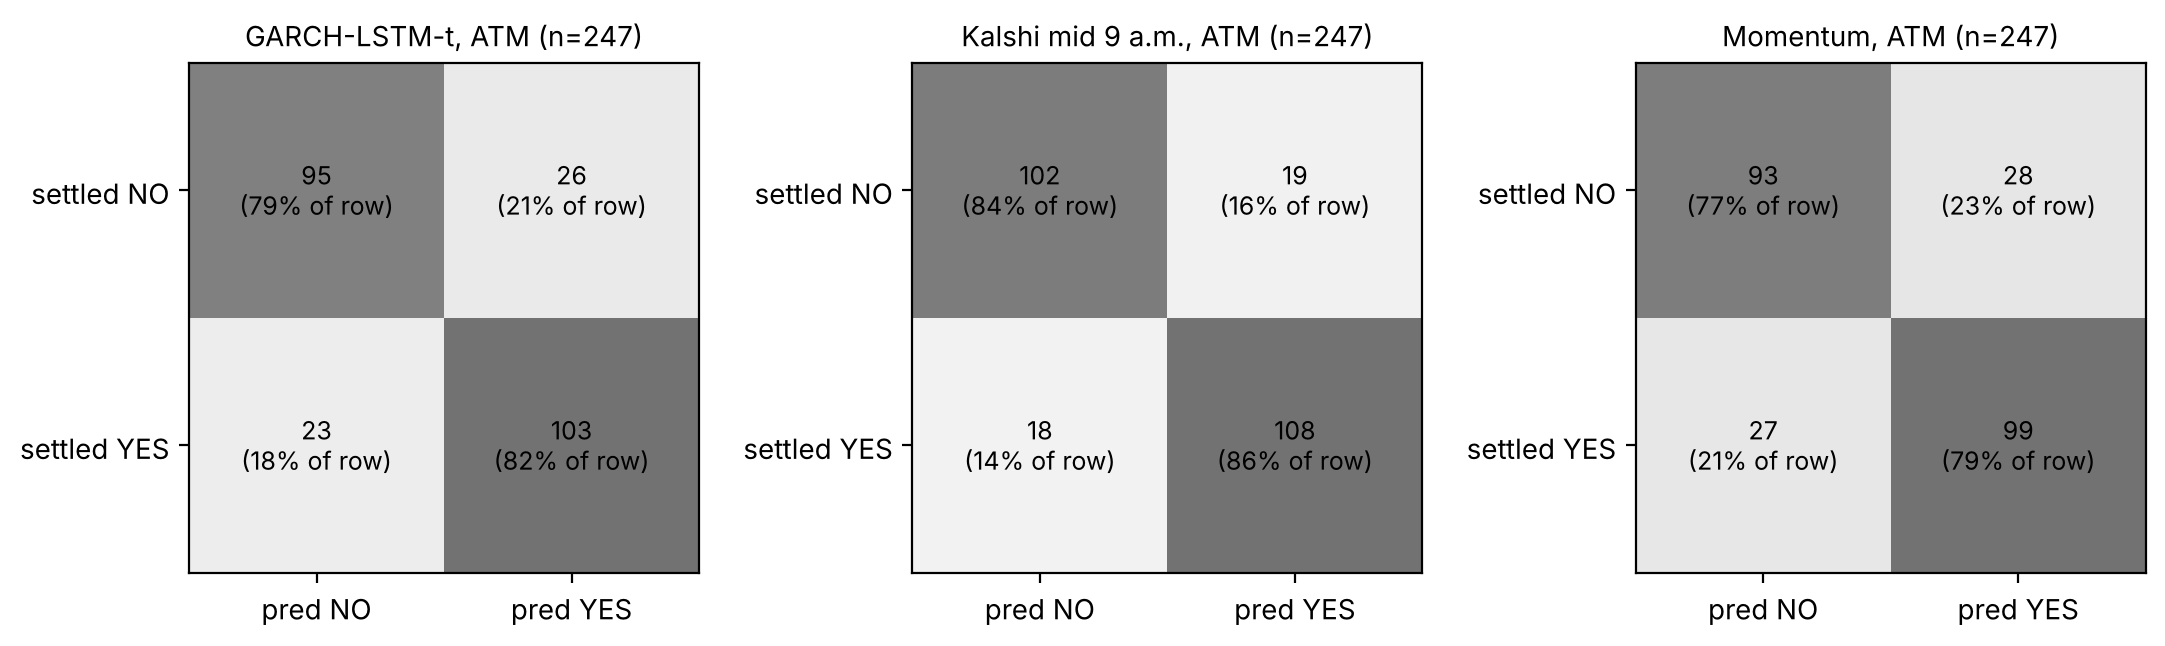

ATM errors of the model: 23 missed YES (price ended above the strike, model said NO; 17 of them on days AAA rose) vs 26 false YES. Recall YES 0.82 vs recall NO 0.79.


,threshold,window,accuracy,balanced_acc,macro_f1,recall_yes,recall_no
0,0.500,fit Aug 20 - Sep 19,0.904,0.909,0.903,0.883,0.934
1,0.500,scored Sep 20 - Oct 19,0.925,0.925,0.924,0.928,0.923
2,0.575,fit Aug 20 - Sep 19,0.913,0.919,0.912,0.880,0.959
3,0.575,scored Sep 20 - Oct 19,0.931,0.930,0.929,0.923,0.936


Threshold chosen on the first half: 0.575; on the later half macro-F1 0.924 at 0.5 vs 0.929 at 0.575.


In [43]:
# 5.6b  Contract-level classification diagnostics: confusion matrix, precision, recall, F1 and balanced accuracy,
# overall and by distance from yesterday's price. Accuracy alone hides two problems:
#   (1) class imbalance: most listed strikes are far from the price, so their outcome is nearly certain;
#   (2) a trivial "no-change" rule (YES iff yesterday's AAA is already above the strike) gets those right for free.
# Signals on the same test contracts (Aug 20 - Oct 19, only contracts with a 9 a.m. book):
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, balanced_accuracy_score
TEW = ds_f["df"].loc[X.TE[0]:X.TE[1]].index
c_te = ds_f["contracts"][ds_f["contracts"].date.isin(TEW)]
cl = E.price_ladder(c_te, ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]])
cl = cl.dropna(subset=["bid", "ask", "y"]).copy()
cl["p_mkt"] = ((cl.bid + cl.ask) / 2).clip(.005, .995)
cl = cl.merge(E.price_ladder(c_te, ds_f["res"]["Momentum"].loc[X.TE[0]:X.TE[1]])[["ticker", "p"]].rename(columns={"p": "p_mom"}), on="ticker")
cl["p_nochg"] = np.where(cl.prev > cl.strike, 1.0, 0.0)
cl["dist_c"] = (cl.strike - cl.prev).abs() * 100
cl["band"] = pd.cut(cl.dist_c, [-.01, 1, 2, 100], labels=["ATM (<=1c)", "near (1-2c)", "far (>2c)"])
SIGS = {"GARCH-LSTM-t": "p", "Kalshi mid 9 a.m.": "p_mkt", "Momentum": "p_mom", "No-change rule": "p_nochg"}

def cls_metrics(y, p, thr=.5):
    y = np.asarray(y).astype(int); yh = (np.asarray(p) > thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yh, labels=[0, 1]).ravel()
    pr, rc, f1, _ = precision_recall_fscore_support(y, yh, labels=[0, 1], zero_division=0)
    return dict(n=len(y), yes_share=y.mean(), accuracy=(tp + tn) / len(y),
                balanced_acc=balanced_accuracy_score(y, yh) if 0 < y.sum() < len(y) else np.nan,
                precision_yes=pr[1], recall_yes=rc[1], f1_yes=f1[1], precision_no=pr[0], recall_no=rc[0], f1_no=f1[0],
                macro_f1=f1.mean(), TP=tp, FP=fp, FN=fn, TN=tn)

rows = []
for sub, g in [("all", cl)] + [(b, cl[cl.band == b]) for b in cl.band.cat.categories]:
    for nm, col in SIGS.items():
        rows.append(dict(contracts=sub, signal=nm, **cls_metrics(g.y, g[col])))
cls_tab = pd.DataFrame(rows)
print(f"Class balance: {cl.y.mean():.1%} of {len(cl)} test contracts settled YES; "
      + ", ".join(f"{b}: {len(g)} contracts, {g.y.mean():.0%} YES" for b, g in cl.groupby("band", observed=True)))
display(cls_tab.set_index(["contracts", "signal"])[["n", "yes_share", "accuracy", "balanced_acc", "precision_yes", "recall_yes",
                                                     "f1_yes", "recall_no", "f1_no", "macro_f1", "TP", "FP", "FN", "TN"]].round(3))

# Day-block bootstrap (all strikes of a day settle on one number) for the ATM macro-F1 gaps
def day_boot(g, f, n=2000, seed=0):
    days = g.date.unique(); by = {d_: x for d_, x in g.groupby("date")}; rng = np.random.default_rng(seed)
    v = [f(pd.concat([by[d_] for d_ in rng.choice(days, len(days))])) for _ in range(n)]
    return f(g), *np.nanpercentile(v, [2.5, 97.5])
atm = cl[cl.band == "ATM (<=1c)"]
mf1 = lambda col: (lambda g: cls_metrics(g.y, g[col])["macro_f1"])
boot_rows = []
for other in ["p_mkt", "p_mom", "p_nochg"]:
    est, lo, hi = day_boot(atm, lambda g, o=other: mf1("p")(g) - mf1(o)(g))
    boot_rows.append(dict(comparison=f"GARCH-LSTM-t minus {[k for k, v in SIGS.items() if v == other][0]}", ATM_macroF1_diff=est, ci95_low=lo, ci95_high=hi))
boot_cls = pd.DataFrame(boot_rows); display(boot_cls.round(3))

# Confusion matrices at the money, where the decision is genuinely uncertain
fig, ax = plt.subplots(1, 3, figsize=(11, 3.3))
for a, (nm, col) in zip(ax, [("GARCH-LSTM-t", "p"), ("Kalshi mid 9 a.m.", "p_mkt"), ("Momentum", "p_mom")]):
    cm = confusion_matrix(atm.y.astype(int), (atm[col] > .5).astype(int), labels=[0, 1])
    a.imshow(cm, cmap="Greys", vmin=0, vmax=cm.max() * 1.6)
    for i in range(2):
        for j in range(2): a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.0%} of row)", ha="center", va="center", fontsize=9)
    a.set_xticks([0, 1], ["pred NO", "pred YES"]); a.set_yticks([0, 1], ["settled NO", "settled YES"]); a.set_title(f"{nm}, ATM (n={len(atm)})", fontsize=10)
fig.tight_layout(); plt.show()

# Which kind of error dominates at the money, and on which days?
a_m = atm.assign(pred=(atm.p > .5).astype(int), up=(atm.date.map(ds_f["df"].y) > 0))
fn_, fp_ = int(((a_m.y == 1) & (a_m.pred == 0)).sum()), int(((a_m.y == 0) & (a_m.pred == 1)).sum())
fn_up = ((a_m.y == 1) & (a_m.pred == 0) & a_m.up).sum()
atm_row = cls_tab[(cls_tab.contracts == "ATM (<=1c)") & (cls_tab.signal == "GARCH-LSTM-t")].iloc[0]
print(f"ATM errors of the model: {fn_} missed YES (price ended above the strike, model said NO; {fn_up} of them on days AAA rose) vs "
      f"{fp_} false YES. Recall YES {atm_row.recall_yes:.2f} vs recall NO {atm_row.recall_no:.2f}.")

# Threshold sensitivity (class imbalance): choose the cut-off on the first half of the test window, apply it to the second half
cut = "2026-09-19"; fit_h, tst_h = cl[cl.date <= cut], cl[cl.date > cut]
grid = np.round(np.arange(.30, .71, .025), 3)
best_thr = grid[int(np.argmax([cls_metrics(fit_h.y, fit_h.p, t)["macro_f1"] for t in grid]))]
thr_tab = pd.DataFrame([dict(threshold=t, window=wn, **{k: cls_metrics(g.y, g.p, t)[k] for k in ["accuracy", "balanced_acc", "macro_f1", "recall_yes", "recall_no"]})
                        for t in sorted({.5, best_thr}) for wn, g in [("fit Aug 20 - Sep 19", fit_h), ("scored Sep 20 - Oct 19", tst_h)]])
display(thr_tab.round(3))
t5 = thr_tab[(thr_tab.threshold == .5) & thr_tab.window.str.startswith("scored")].iloc[0]
tb = thr_tab[(thr_tab.threshold == best_thr) & thr_tab.window.str.startswith("scored")].iloc[0]
print(f"Threshold chosen on the first half: {best_thr:.3f}; on the later half macro-F1 {t5.macro_f1:.3f} at 0.5 vs {tb.macro_f1:.3f} at {best_thr:.3f}.")

m_all = cls_tab.set_index(["contracts", "signal"])
FINDINGS.append(dict(diagnostic="class imbalance / no-change baseline",
                     evidence=f"accuracy all strikes: model {m_all.loc[('all', 'GARCH-LSTM-t'), 'accuracy']:.3f}, no-change rule {m_all.loc[('all', 'No-change rule'), 'accuracy']:.3f}; "
                              f"ATM macro-F1 model {m_all.loc[('ATM (<=1c)', 'GARCH-LSTM-t'), 'macro_f1']:.3f}, market {m_all.loc[('ATM (<=1c)', 'Kalshi mid 9 a.m.'), 'macro_f1']:.3f}",
                     verdict="headline accuracy mostly free; ATM is where skill is measured"))
FINDINGS.append(dict(diagnostic="ATM error type", evidence=f"{fn_} missed YES vs {fp_} false YES",
                     verdict="misses up-moves (downward bias)" if fn_ > 1.5 * fp_ else "misses down-moves (upward bias)" if fp_ > 1.5 * fn_ else "balanced errors"))
FINDINGS.append(dict(diagnostic="decision threshold", evidence=f"best on fit half {best_thr:.3f}; later half macro-F1 {t5.macro_f1:.3f} (0.5) vs {tb.macro_f1:.3f}",
                     verdict="keep 0.5" if tb.macro_f1 <= t5.macro_f1 + .01 else "threshold shift helps out of sample"))

**Reading (5.6b).** The YES/NO classes are balanced (51.0% of the 1,105 test contracts settled YES, and 50–53% in every distance band), because Kalshi centres each ladder on the previous price. The real imbalance is in *difficulty*: 615 of 1,105 contracts (56%) are more than 2 cents from yesterday's price, and there the trivial **no-change rule** (YES if and only if yesterday's AAA is already above the strike) is right 94.3% of the time. Over all contracts that rule reaches 0.872 accuracy, against 0.914 for the model and 0.933 for the market. So most of the model's headline accuracy is free; the useful comparison is at the money (247 contracts within 1 cent), where the no-change rule falls to 0.692, the model reaches 0.802 and the market 0.850. At the money the model's errors are balanced: 23 missed YES (17 of them on days AAA rose) against 26 false YES, with recall 0.82 for YES and 0.79 for NO. The day-block intervals on ATM macro-F1 show the model significantly below the market (-0.049, 95% CI -0.094 to -0.004), significantly above the no-change rule (+0.109, CI +0.026 to +0.192) and not distinguishable from momentum (+0.024, CI -0.020 to +0.066).

The threshold check asks whether the class balance or a probability bias would justify a cut-off other than 0.5. It is chosen on Aug 20 – Sep 19 only (0.575) and gives macro-F1 0.929 against 0.924 at 0.5 on Sep 20 – Oct 19, a negligible gain, so we keep 0.5.

*Effect on next decisions.* From now on we report accuracy and macro-F1 **by distance band** and always next to the no-change rule, and we select daily models on ATM log loss/Brier rather than all-strike accuracy. If one error type dominates at the money (for example many "false YES"), that is a bias in the forecast mean, and it is fixed in the model (regime/direction input), not by moving the threshold, unless the threshold check shows an out-of-sample gain.

,daily test residuals
days,61.000
mean error (cents),0.126
bias p-value,0.443
MAE (cents),0.723
RMSE (cents),1.267
"corr(pred, actual)",0.744
Ljung-Box Q(7) residuals p,0.339
Ljung-Box Q(7) squared residuals p,0.993
cov50 (nominal 50%),0.459
cov80 (nominal 80%),0.705


Note: the test days are not all consecutive (a few AAA values are missing), so the autocorrelations are approximate.


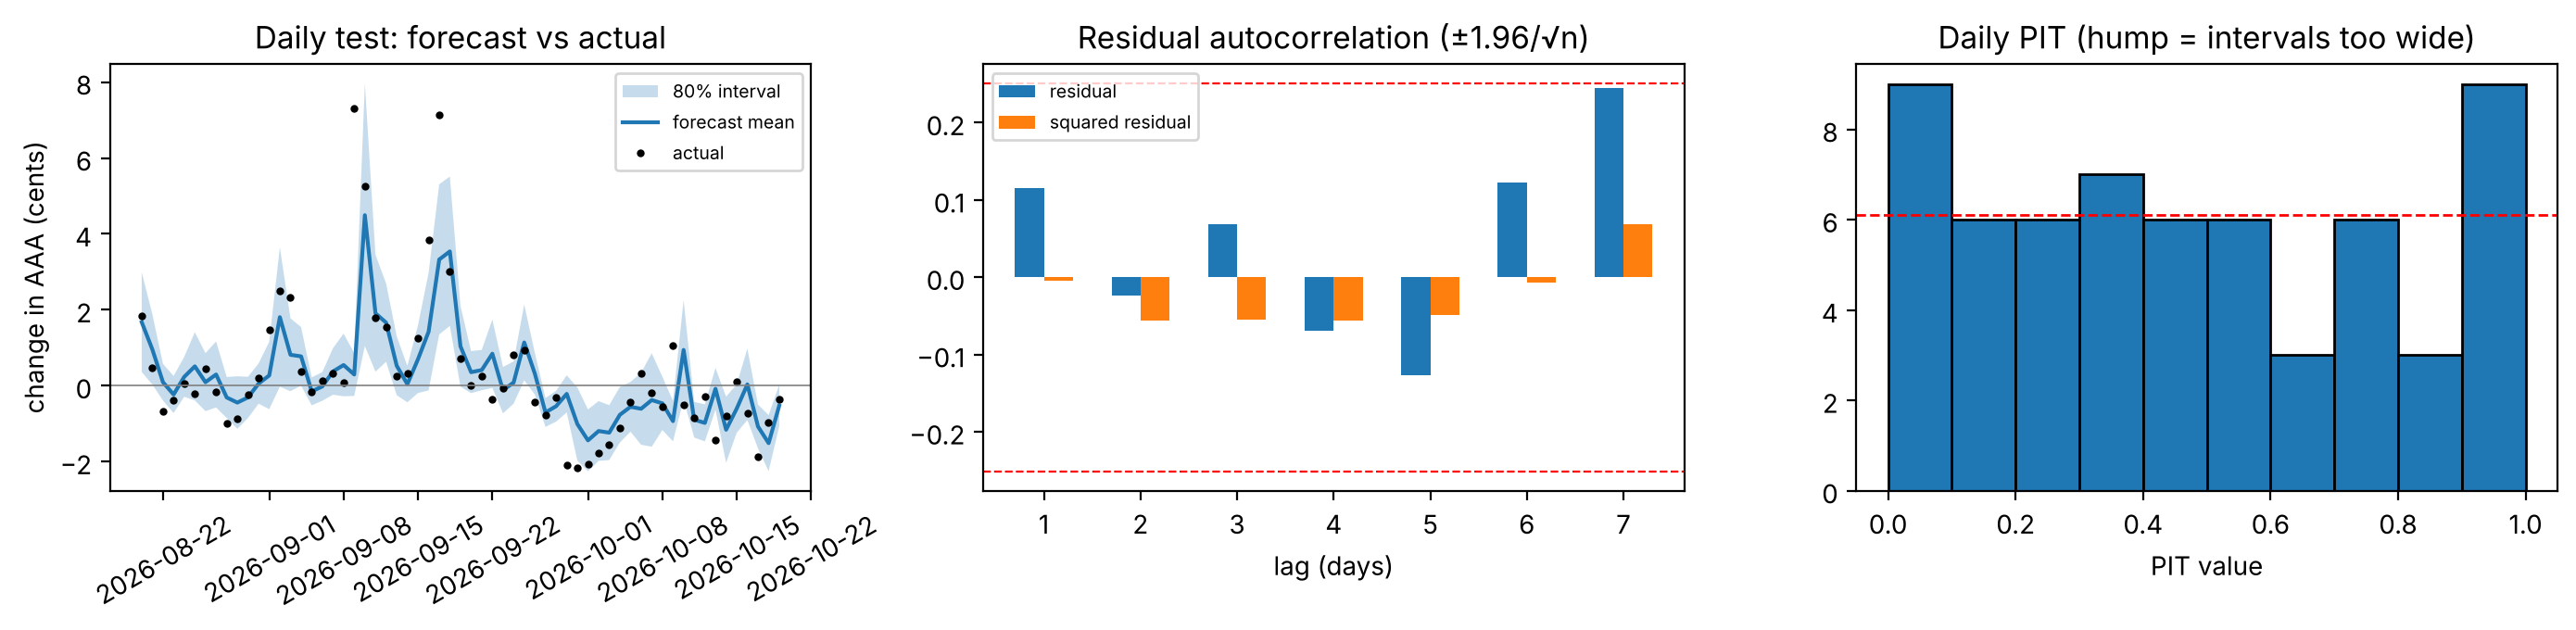

days  MAE_c  bias_c  cov80  dir_acc  contract_err_model  contract_err_market
grouping                 group                                                                                        
realised direction       AAA down           31  0.550  -0.390  0.677    0.774               0.071                0.054
                         AAA up             28  0.947   0.724  0.714    0.857               0.105                0.084
                         flat (<0.05c)       2  0.263  -0.263  1.000    1.000               0.029                0.000
size of move             large >1.5c        16  1.402   0.642  0.562    1.000               0.137                0.088
                         medium 0.5-1.5c    17  0.615   0.023  0.647    0.824               0.073                0.060
                         small <=0.5c       28  0.400  -0.107  0.821    0.714               0.059                0.057
wholesale 2 days earlier falling or flat    37  0.769   0.165  0.649    0.811               0.097                0.059
                         rising             24  0.651   0.066  0.792    0.833               0.070                0.079
weekday of settlement    Fri                 9  0.637  -0.195  0.778    0.778               0.069                0.098
                         Mon                 9  0.227   0.137  0.889    1.000               0.059                0.033
                         Sat                 9  0.550  -0.550  0.556    0.667               0.065                0.065
                         Sun                 9  0.220  -0.036  1.000    0.889               0.031                0.025
                         Thu                 9  0.984   0.722  0.556    0.778               0.092                0.075
                         Tue                 8  1.039  -0.369  0.500    0.625               0.118                0.110
                         Wed                 8  1.525   1.240  0.625    1.000               0.178                0.066

Failure concentration: the worst 7 of 61 days (11%) hold 41% of the model's 95 wrong contracts; 12 days have no wrong contract.


,actual_c,pred_c,lo80_c,hi80_c,pit,d_gulf,strikes,wrong_model,wrong_mkt,outside_80
2026-09-09,7.31,0.298,-0.267,0.863,1.000,0.000,27,14,2,True
2026-09-17,7.14,3.326,1.353,5.308,0.973,0.032,27,7,7,True
2026-09-16,3.83,1.424,-0.121,2.975,0.957,0.009,23,5,1,True
2026-10-09,1.06,-0.930,-1.462,-0.398,0.999,-0.017,17,4,3,True
2026-09-03,2.33,0.816,-0.141,1.776,0.962,-0.115,17,3,0,True
2026-09-29,-2.10,-0.213,-0.702,0.277,0.002,0.000,17,3,2,True


In [44]:
# 5.6c  Residual and failure analysis of the final daily model on the 61 test settlement days.
# Residual = realised AAA change minus forecast mean, in cents. A well-specified model has (i) zero mean residual,
# (ii) no autocorrelation left in the residuals or their squares, (iii) PIT values uniform with nominal interval
# coverage, and (iv) errors that are not concentrated in one kind of day.
from scipy import stats as st
dm = ds_f["res"]["GARCH-LSTM-t lb7 (x3)"].loc[X.TE[0]:X.TE[1]].dropna()
rr = ds_f["df"].loc[dm.index]; rr = rr[rr.y.notna()]; dm = dm.loc[rr.index]
yp = rr.y.values * 100
q = lambda pr: dm.mu.values + dm.scale.values * np.where(np.isinf(dm.df.values), st.norm.ppf(pr), st.t.ppf(pr, np.where(np.isinf(dm.df.values), 30, dm.df.values)))
to_c = lambda pct: rr.aaa_prev.values * (np.exp(pct / 100) - 1) * 100          # percent log change -> cents
res = pd.DataFrame({"actual_c": to_c(yp), "pred_c": to_c(dm.mu.values), "lo80_c": to_c(q(.1)), "hi80_c": to_c(q(.9)),
                    "pit": E.cdf(yp, dm.mu.values, dm.scale.values, dm.df.values), "d_gulf": rr.d_gulf.values}, index=rr.index)
res["err_c"] = res.actual_c - res.pred_c

def acf(x, k):
    x = np.asarray(x) - np.mean(x); d = np.sum(x ** 2)
    return np.array([np.sum(x[j:] * x[:-j]) / d for j in range(1, k + 1)])
def ljung_box(x, k):
    n = len(x); r = acf(x, k); Q = n * (n + 2) * np.sum(r ** 2 / (n - np.arange(1, k + 1))); return Q, st.chi2.sf(Q, k)
K = 7; Q1, p1 = ljung_box(res.err_c, K); Q2, p2 = ljung_box(res.err_c ** 2, K)
bias_p = st.ttest_1samp(res.err_c, 0).pvalue
cov = {f"cov{int(l * 100)}": float(np.mean(np.abs(res.pit - .5) <= l / 2)) for l in (.5, .8, .95)}
resid_tab = pd.Series({"days": len(res), "mean error (cents)": res.err_c.mean(), "bias p-value": bias_p,
                       "MAE (cents)": res.err_c.abs().mean(), "RMSE (cents)": np.sqrt((res.err_c ** 2).mean()),
                       "corr(pred, actual)": np.corrcoef(res.pred_c, res.actual_c)[0, 1],
                       f"Ljung-Box Q({K}) residuals p": p1, f"Ljung-Box Q({K}) squared residuals p": p2,
                       **{f"{k} (nominal {k[3:]}%)": v for k, v in cov.items()},
                       "mean 80% interval width (cents)": (res.hi80_c - res.lo80_c).mean(),
                       "KS test of PIT uniformity p": st.kstest(res.pit, "uniform").pvalue}, name="daily test residuals")
display(resid_tab.to_frame().round(3))
print("Note: the test days are not all consecutive (a few AAA values are missing), so the autocorrelations are approximate.")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
ax[0].fill_between(res.index, res.lo80_c, res.hi80_c, alpha=.25, label="80% interval"); ax[0].plot(res.index, res.pred_c, label="forecast mean")
ax[0].plot(res.index, res.actual_c, "k.", ms=4, label="actual"); ax[0].axhline(0, c="gray", lw=.6)
ax[0].set_ylabel("change in AAA (cents)"); ax[0].set_title("Daily test: forecast vs actual"); ax[0].legend(fontsize=7); ax[0].tick_params(axis="x", rotation=30)
for lab, x, off in [("residual", res.err_c, -.15), ("squared residual", res.err_c ** 2, .15)]:
    ax[1].bar(np.arange(1, K + 1) + off, acf(x, K), width=.3, label=lab)
ax[1].axhline(1.96 / np.sqrt(len(res)), c="r", ls="--", lw=.8); ax[1].axhline(-1.96 / np.sqrt(len(res)), c="r", ls="--", lw=.8)
ax[1].set_xlabel("lag (days)"); ax[1].set_title("Residual autocorrelation (±1.96/√n)"); ax[1].legend(fontsize=7)
ax[2].hist(res.pit, bins=10, range=(0, 1), edgecolor="k"); ax[2].axhline(len(res) / 10, c="r", ls="--", lw=1)
ax[2].set_xlabel("PIT value"); ax[2].set_title("Daily PIT (hump = intervals too wide)"); fig.tight_layout(); plt.show()

# Uneven performance: where are the errors? Contract errors are joined from 5.6b (same test contracts).
wrong = cl.assign(wrong_model=((cl.p > .5) != (cl.y == 1)), wrong_mkt=((cl.p_mkt > .5) != (cl.y == 1))).groupby("date").agg(
    strikes=("y", "size"), wrong_model=("wrong_model", "sum"), wrong_mkt=("wrong_mkt", "sum"))
res = res.join(wrong, how="left")
mv = res.actual_c.abs()
groups = {"realised direction": np.select([res.actual_c > .05, res.actual_c < -.05], ["AAA up", "AAA down"], "flat (<0.05c)"),
          "size of move": pd.cut(mv, [-.01, .5, 1.5, 100], labels=["small <=0.5c", "medium 0.5-1.5c", "large >1.5c"]).astype(str),
          "wholesale 2 days earlier": np.where(res.d_gulf > 0, "rising", "falling or flat"),
          "weekday of settlement": res.index.day_name().str[:3]}
ug = []
for gname, lab in groups.items():
    for v, g in res.groupby(np.asarray(lab)):
        ug.append(dict(grouping=gname, group=v, days=len(g), MAE_c=g.err_c.abs().mean(), bias_c=g.err_c.mean(),
                       cov80=np.mean(np.abs(g.pit - .5) <= .4), dir_acc=np.mean(np.sign(g.pred_c) == np.sign(g.actual_c)) if (g.actual_c != 0).any() else np.nan,
                       contract_err_model=g.wrong_model.sum() / g.strikes.sum(), contract_err_market=g.wrong_mkt.sum() / g.strikes.sum()))
uneven = pd.DataFrame(ug); display(uneven.set_index(["grouping", "group"]).round(3))

# Failure concentration and the worst days (qualitative output analysis)
wm = res.wrong_model.fillna(0).sort_values(ascending=False)
top10 = max(1, int(np.ceil(.1 * len(wm)))); share = wm.iloc[:top10].sum() / max(wm.sum(), 1)
print(f"Failure concentration: the worst {top10} of {len(wm)} days ({top10 / len(wm):.0%}) hold {share:.0%} of the model's {int(wm.sum())} wrong contracts; "
      f"{int((wm == 0).sum())} days have no wrong contract.")
worst = res.loc[wm.index[:6], ["actual_c", "pred_c", "lo80_c", "hi80_c", "pit", "d_gulf", "strikes", "wrong_model", "wrong_mkt"]]
worst["outside_80"] = (worst.actual_c < worst.lo80_c) | (worst.actual_c > worst.hi80_c)
display(worst.round(3))
up_err = uneven.query("grouping == 'realised direction' and group == 'AAA up'"); dn_err = uneven.query("grouping == 'realised direction' and group == 'AAA down'")
FINDINGS.append(dict(diagnostic="daily residuals", evidence=f"bias {res.err_c.mean():+.2f}c (p={bias_p:.2f}); LB p {p1:.2f} / sq {p2:.2f}; cov50/80/95 {cov['cov50']:.2f}/{cov['cov80']:.2f}/{cov['cov95']:.2f}",
                     verdict=("intervals too wide (under-confident)" if cov["cov80"] > .88 else "intervals too narrow (over-confident)" if cov["cov80"] < .72 else "coverage near nominal")
                             + ("; leftover autocorrelation" if min(p1, p2) < .05 else "; no leftover autocorrelation")))
if len(up_err) and len(dn_err):
    FINDINGS.append(dict(diagnostic="uneven errors by direction", evidence=f"contract error rate up days {up_err.contract_err_model.iloc[0]:.3f} vs down days {dn_err.contract_err_model.iloc[0]:.3f}; bias up {up_err.bias_c.iloc[0]:+.2f}c, down {dn_err.bias_c.iloc[0]:+.2f}c",
                         verdict="worse on rising days" if up_err.contract_err_model.iloc[0] > 1.25 * dn_err.contract_err_model.iloc[0] else
                                 "worse on falling days" if dn_err.contract_err_model.iloc[0] > 1.25 * up_err.contract_err_model.iloc[0] else "similar"))
FINDINGS.append(dict(diagnostic="failure concentration", evidence=f"worst {top10} days hold {share:.0%} of wrong contracts", verdict="concentrated" if share > .4 else "spread out"))

**Reading (5.6c).** The residual table checks four properties a well-specified forecast should have. The mean error is +0.13 cents (p = 0.44), so there is no significant bias overall. Ljung–Box tests on the residuals (p = 0.34) and on the squared residuals (p = 0.99) find no leftover autocorrelation or volatility clustering. Coverage is the weak point: the 50%, 80% and 95% intervals cover 0.46, 0.70 and 0.93 of test days, so the daily intervals are slightly too narrow, the same direction as the weekly model's problem (80% coverage 0.74). The PIT is consistent with uniform (KS p = 0.55), though 61 days give little power.

The breakdown by kind of day is the failure analysis. Errors are uneven by direction: the contract error rate is 0.105 on days AAA rose against 0.071 on days it fell, and the bias is +0.72 cents on up days against -0.39 on down days, so the model under-predicts rises. Moves above 1.5 cents are all called in the right direction but too small, and only 0.56 of them fall inside the 80% interval. Failures are concentrated: the worst 7 of 61 days (11%) hold 41% of the 95 wrong contracts, led by +7.3 cents on Sep 9 (14 wrong contracts; the model forecast +0.3) and the Sep 16–17 spikes of +3.8 and +7.1 cents; 12 days have no wrong contract. The market also misses the Sep 17 spike (7 wrong contracts) but not Sep 9 (2). The weekday rows have only 8–9 days each and are descriptive only.

*Effect on next decisions.* Too-narrow daily intervals cost Brier on near-the-money strikes even when the side is right; a scale factor fitted on the validation window (Part 2, Revision 1 method) is the cheap fix to test first. A residual bias on rising days supports adding the rising/falling wholesale regime input already in the Stage 3 plan. Leftover autocorrelation would justify a longer lookback; none would argue against it.

In [45]:
# 5.6d  Stability: do the three seeds of the final daily model agree on the CONTRACT decisions?
# Part 2 (Revision 5) showed the seed spread of daily NLL. Here the question is whether a different seed would have
# bought a different side of the same contract, which matters more for a strike ladder than the NLL spread.
runs_f = ds_f["runs"][7]["t"]
seed_p, seed_rows = {}, []
for sd, r in enumerate(runs_f):
    d_ = r["dist"].loc[X.TE[0]:X.TE[1]].dropna()
    pr = E.price_ladder(c_te, d_).set_index("ticker").p.reindex(cl.ticker)
    seed_p[sd] = pr.values
    yy = ds_f["df"].y.loc[d_.index]; ok = yy.notna()
    seed_rows.append(dict(member=f"seed {sd}", **E.dist_metrics(yy[ok].values * 100, d_[ok.values]),
                          **{k: v for k, v in cls_metrics(cl.y, pr.values).items() if k in ("accuracy", "balanced_acc", "macro_f1")},
                          ATM_accuracy=cls_metrics(cl.y[cl.band == "ATM (<=1c)"], pr.values[(cl.band == "ATM (<=1c)").values])["accuracy"],
                          brier=float(np.mean((pr.values - cl.y.values) ** 2))))
ens_m = E.dist_metrics(ds_f["df"].y.loc[dm.index].values * 100, dm)
seed_rows.append(dict(member="3-seed ensemble", **ens_m, **{k: v for k, v in cls_metrics(cl.y, cl.p).items() if k in ("accuracy", "balanced_acc", "macro_f1")},
                      ATM_accuracy=cls_metrics(atm.y, atm.p)["accuracy"], brier=float(np.mean((cl.p - cl.y) ** 2))))
seed_tab = pd.DataFrame(seed_rows).set_index("member")[["NLL", "CRPS", "MAE", "cov80", "accuracy", "ATM_accuracy", "balanced_acc", "macro_f1", "brier"]]
display(seed_tab.round(4))

P_ = np.column_stack([seed_p[s] for s in seed_p]); side = P_ > .5
cl["seed_disagree"] = side.any(1) & ~side.all(1); cl["seed_sd_p"] = P_.std(1)
stab = cl.groupby("band", observed=True).agg(contracts=("y", "size"), seeds_disagree_on_side=("seed_disagree", "mean"),
                                             mean_sd_of_p=("seed_sd_p", "mean"), max_sd_of_p=("seed_sd_p", "max"))
display(stab.round(3))
dis = cl[cl.seed_disagree]
acc_dis = ((dis.p > .5) == (dis.y == 1)).mean() if len(dis) else np.nan
acc_mkt_dis = ((dis.p_mkt > .5) == (dis.y == 1)).mean() if len(dis) else np.nan
mu_corr = np.corrcoef(np.column_stack([r["dist"].loc[dm.index].mu.values for r in runs_f]).T)
print(f"Seeds disagree on the side of {cl.seed_disagree.mean():.1%} of test contracts ({int(cl.seed_disagree.sum())}); on those the ensemble is right "
      f"{acc_dis:.0%} of the time and the market {acc_mkt_dis:.0%}. Correlation of the seeds' daily mean forecasts: "
      f"{mu_corr[np.triu_indices(len(runs_f), 1)].min():.2f} to {mu_corr[np.triu_indices(len(runs_f), 1)].max():.2f}. "
      f"Seed range of ATM accuracy: {seed_tab.ATM_accuracy.iloc[:-1].min():.3f} to {seed_tab.ATM_accuracy.iloc[:-1].max():.3f}.")
FINDINGS.append(dict(diagnostic="seed stability (contracts)",
                     evidence=f"seeds disagree on {cl.seed_disagree.mean():.1%} of contracts ({stab.seeds_disagree_on_side.get('ATM (<=1c)', np.nan):.0%} of ATM); ATM accuracy by seed {seed_tab.ATM_accuracy.iloc[:-1].min():.2f}-{seed_tab.ATM_accuracy.iloc[:-1].max():.2f}",
                     verdict="unstable at the money" if stab.seeds_disagree_on_side.get("ATM (<=1c)", 0) > .1 else "stable")) 

,NLL,CRPS,MAE,cov80,accuracy,ATM_accuracy,balanced_acc,macro_f1,brier
member,,,,,,,,,
seed 0,-0.1304,0.1331,0.1731,0.6721,0.9167,0.8219,0.9171,0.9167,0.0647
seed 1,-0.0768,0.1323,0.1666,0.6885,0.9186,0.8138,0.9188,0.9186,0.0639
seed 2,-0.0834,0.1323,0.1711,0.7049,0.9104,0.7895,0.9105,0.9104,0.0638
3-seed ensemble,-0.1341,0.1312,0.1682,0.7049,0.9140,0.8016,0.9143,0.9140,0.0630


,contracts,seeds_disagree_on_side,mean_sd_of_p,max_sd_of_p
band,,,,
ATM (<=1c),247,0.081,0.036,0.200
near (1-2c),243,0.049,0.019,0.168
far (>2c),615,0.013,0.006,0.184


Seeds disagree on the side of 3.6% of test contracts (40); on those the ensemble is right 50% of the time and the market 62%. Correlation of the seeds' daily mean forecasts: 0.97 to 0.98. Seed range of ATM accuracy: 0.789 to 0.822.


**Reading (5.6d).** Part 2 showed that the daily NLL depends on the seed (-0.077 to -0.130 across seeds 0–2 here). This table measures what that means for decisions: the seeds would buy different sides on 3.6% of test contracts (40), concentrated at the money (8.1% of ATM contracts, 4.9% near, 1.3% far). On those 40 contracts the ensemble is right 50% of the time and the market 62%, and the seeds' ATM accuracy ranges from 0.789 to 0.822 (ensemble 0.802). The seeds' daily mean forecasts correlate at 0.97–0.98, so the disagreement comes from where the probability mass lands near a strike, not from different forecasts.

*Effect on next decisions.* If seeds disagree on a meaningful share of ATM contracts, the daily model should keep at least five seeds (Part 2, Revision 5), and contracts where the seeds disagree should be treated as "no signal" in any trading rule rather than traded.

In [46]:
# 5.6e  Summary of the diagnostics (every line is computed above; the verdicts follow the stated rules)
diag_summary = pd.DataFrame(FINDINGS)
with pd.option_context("display.max_colwidth", 140): display(diag_summary)

,diagnostic,evidence,verdict
0,weekly train/val/test gap,"NLL 1.66/1.68/2.01; skill vs ECM -0.23 train, -0.33 test; cov80 test 0.74",GENERALIZES
1,daily train/val/test gap,"NLL -0.69/-0.17/-0.13; skill vs ECM -0.50 train, -0.72 test; cov80 test 0.70",GENERALIZES
2,daily convergence,best epoch 15-41; val NLL rises 0.22 after it,overfits after the best epoch (early stopping is doing the regularizing)
3,class imbalance / no-change baseline,"accuracy all strikes: model 0.914, no-change rule 0.872; ATM macro-F1 model 0.801, market 0.850",headline accuracy mostly free; ATM is where skill is measured
4,ATM error type,23 missed YES vs 26 false YES,balanced errors
5,decision threshold,best on fit half 0.575; later half macro-F1 0.924 (0.5) vs 0.929,keep 0.5
6,daily residuals,bias +0.13c (p=0.44); LB p 0.34 / sq 0.99; cov50/80/95 0.46/0.70/0.93,intervals too narrow (over-confident); no leftover autocorrelation
7,uneven errors by direction,"contract error rate up days 0.105 vs down days 0.071; bias up +0.72c, down -0.39c",worse on rising days
8,failure concentration,worst 7 days hold 41% of wrong contracts,concentrated
9,seed stability (contracts),seeds disagree on 3.6% of contracts (8% of ATM); ATM accuracy by seed 0.79-0.82,stable


**What the diagnostics change in the next modeling round.** The table above is regenerated on every run. Read together with the earlier sections, the evidence points to a model limited by inputs and regime, not by capacity or optimization. Both final models generalize relative to the ECM (5.6a). The daily network still overfits after epoch 15–41, so early stopping stays and a bigger network is not the next step. Its headline accuracy is mostly the easy far-from-price contracts that the no-change rule also gets right (5.6b), so model selection moves to at-the-money metrics. Its errors are not random: the daily and weekly intervals are both slightly too narrow (5.6c, Revision 1), and the hardest days are price spikes (5.6c).

| Finding | Next modeling decision |
|---|---|
| Overfitting after epoch 15–41 even with 3,181 windows; ATM accuracy varies by seed (0.79–0.82) | Keep early stopping and at least 5 seeds; do not grow capacity |
| Accuracy dominated by easy strikes; no-change rule close behind | Select and report on ATM Brier/log loss and macro-F1 by distance band, always beside the no-change rule and the market |
| Daily and weekly 80% intervals too narrow (0.70, 0.74) | Test a validation-fitted scale factor for the daily model; keep the weekly shape problem (Part 2, Revision 1) on the list |
| Errors concentrated on rising and spike days (bias +0.72 cents on up days) | Add the rising-versus-falling wholesale regime input (Stage 3 item 2) and fresher wholesale data (item 1) |
| Seeds disagree on 8% of ATM contracts | Treat seed disagreement as "no trade"; do not optimise a trading rule on 30 days |


## 6. Challenges and mitigation

| Challenge | Effect | Mitigation |
|---|---|---|
| Weekly EIA labels cannot define daily AAA moves | The original daily target was not learnable | Daily AAA values from Kalshi settlements (234 events) and from Wayback Machine snapshots of gasprices.aaa.com (3,865 days); the 10-year weekly model feeds the daily one |
| Only 83 complete daily training windows | Daily networks overfit within a few epochs | Extended AAA history gives 3,181 windows; one 16-unit layer, dropout 0.3, L2 1e-3, early stopping, three-seed ensembles, chronological splits. Overfitting after epoch 15–41 remains, and early stopping handles it |
| Reconstructed AAA history | Wayback values come from week-, month- and year-ago rows for some days; Kalshi settlement dates for Sep 2023 – Apr 2024 were shifted by one day | Cross-checked on overlapping days (99.5% / 98.7% / 87% agreement by row type), source recorded per value in `manual_aaa_sources.csv`, Wayback values take precedence |
| Weak volatility clustering | The GARCH assumption might not hold | ARCH-LM plus an ablation. The GARCH input helps weekly (2.062 to 2.032) but not daily, where the Student-t LSTM without it is as good or better; ECM-GARCH-t matches the weekly deep model |
| Wholesale prices lag the AAA price | Inputs about 2 days stale after the refresh (19–22 days stale before it) | FRED wholesale and crude pulled through Nov 3; on Nov 4–7 the mean error fell from 1.27 to 0.83 cents; daily intraday inputs are a Stage 3 task |
| Market benchmark taken one hour after the open | The market has more information than the model | Stated with every comparison; Stage 3 compares at matched times |
| Fee rounding error found during review | Backtest overstated costs | Fixed to Kalshi's centicent rounding (Kalshi, 2026) |
| Kalshi API rate limits (HTTP 429) | Incomplete historical order books | Retry with backoff; benchmark scored only where a book exists |
| Small evaluation samples (61 test days) | Low-power tests; several earlier conclusions reversed after the rerun | Diebold–Mariano tests with Holm correction, day-block bootstrap intervals, seed spread, sample sizes reported |
| Four team members working on separate notebook copies | Stale or inconsistent numbers across parts | One shared `gaslab/` package, results cached by data fingerprint, branch-and-PR workflow, one integrated notebook run top to bottom |

## 7. Reflection and forward plan

**What mattered most.** The proposal's core problem, learning a daily target from weekly labels, is solved: Kalshi settlements plus Wayback snapshots of AAA give 3,865 daily values and 3,181 training windows, so the daily model is trained and scored on real data. The heavy-tailed Student-t head gave the largest weekly gain (test NLL 2.755 to 2.062); the GARCH input added little weekly (2.062 to 2.032) and nothing daily. A simple ECM-GARCH-t matches the weekly deep model (1.999 vs 2.032), so on weekly data the gain comes from time-varying volatility, not from the network. Tuning lowered weekly test NLL to 2.005, a gain of about one seed standard deviation.

**What the market comparison says.** The Kalshi price one hour after the open scores better (daily test Brier 0.049 vs 0.063; ATM accuracy 0.850 vs 0.802), but only the ATM gap is significant (95% CI -9.2 to -0.8 points). Adding our model to the market does not help (Brier 0.0443 vs 0.0415), and the fee-aware 9 a.m. backtest loses (-2.6% model, -3.1% blend, intervals include zero). After the wholesale refresh, the mean error on Nov 4–7 was about 0.8 cents against 2.8 for "tomorrow equals today", but Brier was still 0.065 against 0.022 for the market (4 days only). We claim no trading edge. Limitations: wholesale inputs lag about two days, the daily 80% intervals cover 0.70, the model under-predicts rises, and the evaluation windows are short.

**Lessons.** Simple baselines and significance tests stopped us from keeping claims the data did not support; rerunning on the extended data reversed several of them. Every number is now generated by code and cached by data fingerprint.

**Stage 3 plan.** (1) Fresher inputs: daily wholesale and intraday AAA, the largest known gap. (2) A rising-versus-falling wholesale regime input for the asymmetric errors. (3) A validation-fitted scale factor for the daily intervals, at least five seeds, and the dropout 0.5 setting from Part 3 Revision 6 if it holds. (4) Market comparison at matched times with day-block bootstrap intervals. (5) Optionally one Transformer encoder on identical splits; the neural SDE stays out of scope. Fallback if daily labels stop: the 10-year weekly model, scored on 967 Kalshi weekly contracts (accuracy 0.730, Brier 0.192). Team plan: one lead and one reviewer per workstream, a weekly meeting, and a full notebook rerun before each milestone.

## Revision log (for the contribution table)

| Date | Who | What |
|---|---|---|
| 2026-10-27 | Yixin Tian | Checked the figures in the text against the data (233 settled daily AAA days, 1,105 priced test contracts on 61 days) and filled in the owner field |
| 2026-10-27 | Yixin Tian | Revision 1: binomial tail, coverage and mean-PIT tests for the weekly forecast, overall and by wholesale regime |
| 2026-10-27 | Yixin Tian | Revision 2: market calibration by price bucket with event-block bootstrap intervals (data only) |
| 2026-10-27 | Yixin Tian | Revision 3: split the blend's gain into market recalibration and the model's own contribution |
| 2026-10-27 | Yixin Tian | Revision 4: day-block bootstrap ROI intervals, YES/NO split and no-skill controls for the 9 a.m. backtest |
| 2026-10-27 | Yixin Tian | Revision 5: out-of-sample check of the published forecast against the Kalshi settlement (rerun 2026-11-08 for the Nov 4 forecast) |
| 2026-11-07 | Yixin Tian | 5.6a: train/validation/test gap and skill vs ECM for the final weekly and daily models, target-shift table, convergence of the final daily runs |
| 2026-11-07 | Yixin Tian | 5.6b: confusion matrices, precision/recall/F1 and balanced accuracy by distance band, no-change baseline, day-block intervals, threshold check |
| 2026-11-07 | Yixin Tian | 5.6c: daily residual analysis (bias, Ljung-Box, coverage), error breakdown by kind of day, worst-day table |
| 2026-11-07 | Yixin Tian | 5.6d-e: contract-level seed stability; diagnostic summary and next modeling decisions |


## Reproducibility

Run this notebook top to bottom (Kernel → Restart & Run All). Tested with Python 3.13, TensorFlow 2.21, pandas,
scikit-learn, statsmodels, arch and scipy (the setup cell prints the versions used). Seeds 0–2 are fixed and saved results are keyed to the data fingerprint (b2dc33c005be). A full run takes about 65 minutes on 2 CPUs. Code is in `gaslab/` (data, models, evaluate, pipeline, experiments,
service); data is in `data/`. In the project repository: `python update_data.py` refreshes the data from FRED and Kalshi;
`python train_model.py` then `python forecast.py` give tomorrow's AAA forecast; new rows can be added in
`data/manual_aaa.csv` (`date,aaa`) and `data/manual_wholesale.csv` (`date,whsl_gulf,whsl_nyh,wti,brent`).

## References

AAA. (2026). *AAA gas prices*. https://gasprices.aaa.com

Bollerslev, T. (1986). Generalized autoregressive conditional heteroskedasticity. *Journal of Econometrics, 31*(3), 307–327. https://doi.org/10.1016/0304-4076(86)90063-1

Borenstein, S., Cameron, A. C., & Gilbert, R. (1997). Do gasoline prices respond asymmetrically to crude oil price changes? *The Quarterly Journal of Economics, 112*(1), 305–339. https://doi.org/10.1162/003355397555118

Bürgi, C., Deng, W., & Whelan, K. (2026, February 18). The economics of the Kalshi prediction market. *VoxEU*, CEPR. https://cepr.org/voxeu/columns/economics-kalshi-prediction-market

Chesnes, M. (2016). Asymmetric pass-through in U.S. gasoline prices. *The Energy Journal, 37*(1), 153–180. https://doi.org/10.5547/01956574.37.1.mche

Engle, R. F. (1982). Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation. *Econometrica, 50*(4), 987–1007. https://doi.org/10.2307/1912773

Gneiting, T., & Raftery, A. E. (2007). Strictly proper scoring rules, prediction, and estimation. *Journal of the American Statistical Association, 102*(477), 359–378. https://doi.org/10.1198/016214506000001437

Kalshi. (n.d.). *Kalshi trade API v2* [API documentation]. https://docs.kalshi.com

Kalshi. (2026). *Fee schedule* (effective July 7, 2026). https://kalshi.com/docs/kalshi-fee-schedule.pdf

Kim, H. Y., & Won, C. H. (2018). Forecasting the volatility of stock price index: A hybrid model integrating LSTM with multiple GARCH-type models. *Expert Systems with Applications, 103*, 25–37. https://doi.org/10.1016/j.eswa.2018.03.002

U.S. Energy Information Administration. (2026). *GASREGW, DGASUSGULF, DGASNYH, DCOILBRENTEU, DCOILWTICO* [Data sets]. FRED, Federal Reserve Bank of St. Louis. https://fred.stlouisfed.org

Zhao, P., Zhu, H., Ng, W. S. H., & Lee, D. L. (2024). From GARCH to neural network for volatility forecast. *Proceedings of the AAAI Conference on Artificial Intelligence, 38*(15), 16998–17006. https://doi.org/10.1609/aaai.v38i15.29643